# U-net

## Imports

In [98]:
# In[4]:

import os, json, time, hashlib, shutil, math
from pathlib import Path
from itertools import product
import random  # NEW

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from sklearn.metrics import confusion_matrix, classification_report

# --------------------------
# Reproducible seeding
# --------------------------
SEED = 42  # or any integer you like

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Make cuDNN deterministic (slightly slower but reproducible)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Global seed set to: {SEED}")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Global seed set to: 42
device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


## Basic Data Loading

In [99]:
# Optional PTB-XL download and preprocessing
# -----------------------------------------------------------
# This cell prepares a large clinical ECG dataset for the same
# downstream training code used by the UCR-style datasets.
# It is intentionally gated so "Run all" does not download PTB-XL
# unless explicitly requested.
#
# First-time setup:
#   1. install wfdb in the active environment if needed: pip install wfdb
#   2. set RUN_PTBXL_PREPROCESS = True
#   3. run this cell
#   4. set DATASET_NAME = "PTBXL_LEADII_BINARY" in the next data-loading cell

RUN_PTBXL_PREPROCESS = False

# Robust path resolution for this optional cell, independent of the main loader cell.
HERE = Path().resolve()
DATA_ROOT = HERE / "Data"
if not DATA_ROOT.exists() and (HERE.parent / "Data").exists():
    DATA_ROOT = HERE.parent / "Data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)

PTBXL_VERSION = "1.0.3"
PTBXL_BASE_URL = f"https://physionet.org/files/ptb-xl/{PTBXL_VERSION}"
PTBXL_RAW_DIR = DATA_ROOT / "PTB-XL"
PTBXL_PROCESSED_DIR = DATA_ROOT / "PTBXL_processed"
PTBXL_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

PTBXL_TASK = "binary_norm_abnormal"  # alternatives: "single_label_superclass"
PTBXL_LEAD = "II"
PTBXL_RECORDS_DIR = "records100"  # 100 Hz, 10 s -> 1000 time points
PTBXL_OUTPUT_NPZ = PTBXL_PROCESSED_DIR / f"PTBXL_LEAD{PTBXL_LEAD}_{PTBXL_TASK}.npz"
PTBXL_OUTPUT_SPLITS = PTBXL_PROCESSED_DIR / f"PTBXL_LEAD{PTBXL_LEAD}_{PTBXL_TASK}_splits.csv"


def _download_file(url, dest, chunk_size=1024 * 1024, retries=8, timeout=90):
    """Download one file if it is missing, retrying transient PhysioNet errors."""
    import random
    import time
    import urllib.error
    import urllib.request

    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        return dest

    tmp = dest.with_suffix(dest.suffix + ".part")
    retryable_http = {429, 500, 502, 503, 504}

    for attempt in range(1, int(retries) + 1):
        try:
            request = urllib.request.Request(
                url,
                headers={"User-Agent": "U-net-cikk PTB-XL preprocessing"},
            )
            with urllib.request.urlopen(request, timeout=timeout) as response, tmp.open("wb") as f:
                while True:
                    chunk = response.read(chunk_size)
                    if not chunk:
                        break
                    f.write(chunk)
            tmp.replace(dest)
            return dest
        except urllib.error.HTTPError as exc:
            should_retry = exc.code in retryable_http and attempt < retries
            if tmp.exists():
                tmp.unlink()
            if not should_retry:
                raise
            sleep_s = min(90.0, 2.0 ** attempt) + random.uniform(0.0, 1.0)
            print(f"Download failed with HTTP {exc.code} for {url}. Retrying {attempt}/{retries} in {sleep_s:.1f}s.")
            time.sleep(sleep_s)
        except (urllib.error.URLError, TimeoutError, ConnectionError) as exc:
            if tmp.exists():
                tmp.unlink()
            if attempt >= retries:
                raise
            sleep_s = min(90.0, 2.0 ** attempt) + random.uniform(0.0, 1.0)
            print(f"Download failed for {url}: {exc}. Retrying {attempt}/{retries} in {sleep_s:.1f}s.")
            time.sleep(sleep_s)

    raise RuntimeError(f"Failed to download after {retries} attempts: {url}")


def _load_ptbxl_metadata(raw_dir=PTBXL_RAW_DIR):
    import ast
    import pandas as pd

    raw_dir = Path(raw_dir)
    db_path = _download_file(f"{PTBXL_BASE_URL}/ptbxl_database.csv", raw_dir / "ptbxl_database.csv")
    scp_path = _download_file(f"{PTBXL_BASE_URL}/scp_statements.csv", raw_dir / "scp_statements.csv")

    db = pd.read_csv(db_path)
    scp = pd.read_csv(scp_path, index_col=0)
    db["scp_codes_dict"] = db["scp_codes"].apply(ast.literal_eval)
    return db, scp


def _diagnostic_superclasses(scp_codes, scp_table):
    classes = set()
    for code in scp_codes:
        if code not in scp_table.index:
            continue
        row = scp_table.loc[code]
        if bool(row.get("diagnostic", False)) and isinstance(row.get("diagnostic_class"), str):
            classes.add(row["diagnostic_class"])
    return sorted(classes)


def _build_ptbxl_labels(db, scp_table, task=PTBXL_TASK):
    class_names = None
    y = []
    keep = []
    diagnostic_sets = []

    for _, row in db.iterrows():
        classes_i = _diagnostic_superclasses(row["scp_codes_dict"], scp_table)
        diagnostic_sets.append(";".join(classes_i))

        if task == "binary_norm_abnormal":
            if not classes_i:
                y.append(-1)
                keep.append(False)
            else:
                y.append(0 if classes_i == ["NORM"] else 1)
                keep.append(True)
            class_names = ["NORM", "ABNORMAL"]
        elif task == "single_label_superclass":
            if len(classes_i) != 1:
                y.append(-1)
                keep.append(False)
            else:
                class_names = ["NORM", "MI", "STTC", "CD", "HYP"]
                y.append(class_names.index(classes_i[0]))
                keep.append(True)
        else:
            raise ValueError(f"Unknown PTBXL_TASK={task!r}")

    out = db.copy()
    out["diagnostic_superclasses"] = diagnostic_sets
    out["target"] = np.asarray(y, dtype=np.int64)
    out["keep_for_task"] = np.asarray(keep, dtype=bool)
    return out[out["keep_for_task"]].reset_index(drop=True), class_names


def _download_ptbxl_record_files(record_base, raw_dir=PTBXL_RAW_DIR):
    """Download the .hea and .dat files for one PTB-XL low-resolution record."""
    raw_dir = Path(raw_dir)
    rel = Path(record_base)
    for ext in [".hea", ".dat"]:
        url = f"{PTBXL_BASE_URL}/{record_base}{ext}"
        _download_file(url, raw_dir / f"{record_base}{ext}")
        # A tiny pause avoids hammering PhysioNet during the full 21k-record run.
        import time
        time.sleep(0.05)
    return raw_dir / record_base


def preprocess_ptbxl_lead_dataset(
    task=PTBXL_TASK,
    lead=PTBXL_LEAD,
    records_dir=PTBXL_RECORDS_DIR,
    raw_dir=PTBXL_RAW_DIR,
    output_npz=PTBXL_OUTPUT_NPZ,
    output_splits=PTBXL_OUTPUT_SPLITS,
    max_records=None,
):
    """
    Download PTB-XL records100, extract one lead, and save train/val/test arrays.

    Split protocol follows the standard PTB-XL folds:
      folds 1-8 -> train, fold 9 -> validation, fold 10 -> test.
    """
    try:
        import wfdb
    except ImportError as exc:
        raise ImportError("PTB-XL preprocessing requires wfdb. Install it with: pip install wfdb") from exc

    from tqdm.auto import tqdm

    db, scp_table = _load_ptbxl_metadata(raw_dir)
    task_db, class_names = _build_ptbxl_labels(db, scp_table, task=task)
    task_db = task_db[task_db["filename_lr"].str.startswith(records_dir)].reset_index(drop=True)
    if max_records is not None:
        task_db = task_db.iloc[:int(max_records)].copy()

    X_rows = []
    y_rows = []
    split_rows = []

    for _, row in tqdm(task_db.iterrows(), total=len(task_db), desc=f"PTB-XL {task} {lead}"):
        record_base = row["filename_lr"]
        local_base = _download_ptbxl_record_files(record_base, raw_dir=raw_dir)
        signal, fields = wfdb.rdsamp(str(local_base))
        sig_names = list(fields.get("sig_name", []))
        if lead not in sig_names:
            raise ValueError(f"Lead {lead!r} not found in record {record_base}; available leads: {sig_names}")
        lead_idx = sig_names.index(lead)

        X_rows.append(signal[:, lead_idx].astype(np.float32))
        y_rows.append(int(row["target"]))

        fold = int(row["strat_fold"])
        split = "train" if fold <= 8 else "val" if fold == 9 else "test"
        split_rows.append({
            "ecg_id": int(row["ecg_id"]),
            "patient_id": int(row["patient_id"]),
            "strat_fold": fold,
            "split": split,
            "filename_lr": record_base,
            "target": int(row["target"]),
            "target_label": class_names[int(row["target"])],
            "diagnostic_superclasses": row["diagnostic_superclasses"],
        })

    X = np.stack(X_rows, axis=0).astype(np.float32)
    y = np.asarray(y_rows, dtype=np.int64)
    split_df = pd.DataFrame(split_rows)

    idx_train = split_df.index[split_df["split"] == "train"].to_numpy()
    idx_val = split_df.index[split_df["split"] == "val"].to_numpy()
    idx_test = split_df.index[split_df["split"] == "test"].to_numpy()

    np.savez_compressed(
        output_npz,
        X_train=X[idx_train], y_train=y[idx_train],
        X_val=X[idx_val], y_val=y[idx_val],
        X_test=X[idx_test], y_test=y[idx_test],
        classes=np.asarray(class_names, dtype=object),
        lead=np.asarray([lead], dtype=object),
        task=np.asarray([task], dtype=object),
        source=np.asarray([f"PTB-XL {PTBXL_VERSION} {records_dir}"], dtype=object),
    )
    split_df.to_csv(output_splits, index=False)

    print("Saved:", output_npz.resolve())
    print("Saved:", output_splits.resolve())
    print("Shapes:", X[idx_train].shape, X[idx_val].shape, X[idx_test].shape)
    print("Class counts:", dict(zip(*np.unique(y, return_counts=True))))
    return output_npz, output_splits


if RUN_PTBXL_PREPROCESS:
    preprocess_ptbxl_lead_dataset()
else:
    print("PTB-XL preprocessing is configured but not running. Set RUN_PTBXL_PREPROCESS = True to download/process it.")


PTB-XL preprocessing is configured but not running. Set RUN_PTBXL_PREPROCESS = True to download/process it.


In [100]:
# Optional UCR/UEA NonInvasiveFetalECGThorax download
# -----------------------------------------------------------
# The Time Series Classification archive uses the historical typo
# "Fatal" in the downloadable zip names, while the dataset names in
# the notebook and paper use "Fetal". This downloader handles that
# mapping and writes the .ts files expected by the main loader.

RUN_UCR_THORAX_DOWNLOAD = True
UCR_THORAX_DATASETS = [
    "NonInvasiveFetalECGThorax1",
    "NonInvasiveFetalECGThorax2",
]

UCR_DOWNLOAD_BASE_URLS = [
    "https://www.timeseriesclassification.com/aeon-toolkit/{dataset_name}.zip",
    "http://www.timeseriesclassification.com/aeon-toolkit/{dataset_name}.zip",
    "https://www.timeseriesclassification.com/ClassificationDownloads/{download_name}.zip",
    "http://www.timeseriesclassification.com/ClassificationDownloads/{download_name}.zip",
]

UCR_DOWNLOAD_NAME_OVERRIDES = {
    "NonInvasiveFetalECGThorax1": "NonInvasiveFatalECGThorax1",
    "NonInvasiveFetalECGThorax2": "NonInvasiveFatalECGThorax2",
}


def _label_to_clean_string(label):
    try:
        v = float(label)
        if v.is_integer():
            return str(int(v))
    except Exception:
        pass
    return str(label).strip()


def _convert_ucr_txt_to_ts(txt_path, ts_path, problem_name):
    """Convert classic UCR txt format (label first column) to .ts format."""
    data = np.loadtxt(txt_path)
    if data.ndim != 2 or data.shape[1] < 2:
        raise ValueError(f"Unexpected UCR txt shape for {txt_path}: {data.shape}")

    labels = [_label_to_clean_string(x) for x in data[:, 0]]
    values = data[:, 1:].astype(np.float32)
    class_labels = sorted(set(labels), key=lambda x: float(x) if x.replace('.', '', 1).lstrip('-').isdigit() else x)

    ts_path = Path(ts_path)
    ts_path.parent.mkdir(parents=True, exist_ok=True)
    with ts_path.open("w", encoding="utf-8") as f:
        f.write(f"@problemName {problem_name}\n")
        f.write("@timestamps false\n")
        f.write("@univariate true\n")
        f.write("@missing false\n")
        f.write("@equallength true\n")
        f.write("@classLabel true " + " ".join(class_labels) + "\n")
        f.write("@data\n")
        for row, label in zip(values, labels):
            series = ",".join(f"{float(v):.9g}" for v in row)
            f.write(f"{series}:{label}\n")

    return ts_path


def _find_ucr_split_file(extract_dir, dataset_name, download_name, split):
    candidates = []
    for stem in [dataset_name, download_name]:
        for suffix in [".ts", ".txt", ".arff"]:
            candidates.extend(Path(extract_dir).rglob(f"{stem}_{split}{suffix}"))
    if not candidates:
        raise FileNotFoundError(
            f"Could not find {split} file for {dataset_name} under {extract_dir}."
        )
    return candidates[0]


def ensure_ucr_dataset_downloaded(dataset_name, data_root=DATA_ROOT, force=False):
    import shutil
    import zipfile

    if dataset_name not in UCR_THORAX_DATASETS:
        raise ValueError(f"This helper is configured for {UCR_THORAX_DATASETS}, got {dataset_name!r}")

    data_root = Path(data_root)
    dataset_dir = data_root / dataset_name
    train_ts = dataset_dir / f"{dataset_name}_TRAIN.ts"
    test_ts = dataset_dir / f"{dataset_name}_TEST.ts"
    if not force and train_ts.exists() and test_ts.exists() and train_ts.stat().st_size > 0 and test_ts.stat().st_size > 0:
        print(f"{dataset_name}: already present at {dataset_dir}")
        return dataset_dir

    download_name = UCR_DOWNLOAD_NAME_OVERRIDES.get(dataset_name, dataset_name)
    download_dir = data_root / "_downloads"
    download_dir.mkdir(parents=True, exist_ok=True)
    zip_path = download_dir / f"{dataset_name}.zip"

    last_error = None
    for url_template in UCR_DOWNLOAD_BASE_URLS:
        url = url_template.format(dataset_name=dataset_name, download_name=download_name)
        try:
            if zip_path.exists():
                zip_path.unlink()
            _download_file(url, zip_path)
            if not zipfile.is_zipfile(zip_path):
                raise zipfile.BadZipFile(f"Downloaded file is not a zip: {url}")
            break
        except Exception as exc:
            last_error = exc
            if zip_path.exists():
                zip_path.unlink()
    else:
        raise RuntimeError(f"Failed to download {dataset_name} from configured UCR URLs.") from last_error

    extract_dir = download_dir / f"{download_name}_extract"
    if extract_dir.exists():
        shutil.rmtree(extract_dir)
    extract_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(extract_dir)

    dataset_dir.mkdir(parents=True, exist_ok=True)
    for split in ["TRAIN", "TEST"]:
        src = _find_ucr_split_file(extract_dir, dataset_name, download_name, split)
        dst = dataset_dir / f"{dataset_name}_{split}.ts"
        if src.suffix.lower() == ".ts":
            shutil.copy2(src, dst)
        elif src.suffix.lower() == ".txt":
            _convert_ucr_txt_to_ts(src, dst, dataset_name)
        else:
            raise ValueError(f"Unsupported UCR split format for {src}; expected .ts or .txt")

    print(f"{dataset_name}: ready at {dataset_dir.resolve()}")
    return dataset_dir


def download_ucr_thorax_datasets(datasets=UCR_THORAX_DATASETS, force=False):
    ready = []
    for ds in datasets:
        ready.append(ensure_ucr_dataset_downloaded(ds, force=force))
    return ready


if RUN_UCR_THORAX_DOWNLOAD:
    download_ucr_thorax_datasets()
else:
    print("UCR Thorax download is configured but not running. Set RUN_UCR_THORAX_DOWNLOAD = True to download Thorax1/2.")


NonInvasiveFetalECGThorax1: already present at C:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax1
NonInvasiveFetalECGThorax2: already present at C:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax2


In [101]:
from pathlib import Path
import numpy as np
import pandas as pd

# DATASET_NAME = "ECG5000"
DATASET_NAME = "PTBXL_LEADII_BINARY"
# DATASET_NAME = "NonInvasiveFetalECGThorax1"
# DATASET_NAME = "NonInvasiveFetalECGThorax2"


def resolve_data_root():
    """Resolve Data/ robustly when the notebook is launched from the repo or a child folder."""
    here = Path().resolve()
    data_root = here / "Data"
    if not data_root.exists() and (here.parent / "Data").exists():
        data_root = here.parent / "Data"
    return data_root


HERE = Path().resolve()
DATA_ROOT = resolve_data_root()


def sort_label_values(labels):
    labels = list(labels)
    try:
        return sorted(labels, key=lambda x: float(x))
    except Exception:
        return sorted(labels)


def load_ucr_ts(ts_path: Path):
    """
    Minimal UCR/UEA .ts loader for univariate classification datasets.
    Returns: X (N, L) float32, y_raw (N,) as original labels (strings)
    """
    X, y = [], []
    in_data = False

    with ts_path.open("r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            low = line.lower()
            if low.startswith("@data"):
                in_data = True
                continue
            if not in_data:
                continue

            if ":" not in line:
                continue

            series_part, label_part = line.rsplit(":", 1)
            label = label_part.strip()
            series_str = series_part.strip()

            vals = [v for v in series_str.split(",") if v != ""]
            vals = np.array(vals, dtype=np.float32)

            X.append(vals)
            y.append(label)

    X = np.stack(X, axis=0).astype(np.float32)
    y = np.array(y)
    return X, y


def load_dataset_into_globals(dataset_name):
    """Load one supported dataset and publish the arrays/metadata used downstream."""
    global DATASET_NAME, DATA_DIR, DATA_ROOT
    global X_train, y_train, X_val, y_val, X_test, y_test
    global X_train_raw, X_val_raw, X_test_raw
    global classes, num_classes, seq_len
    global SPLIT_SEED, SPLIT_NAME, SPLIT_INDEX_PATH

    DATASET_NAME = str(dataset_name)
    DATA_ROOT = resolve_data_root()
    DATA_DIR = DATA_ROOT / DATASET_NAME

    if DATASET_NAME == "PTBXL_LEADII_BINARY":
        ptbxl_processed_path = DATA_ROOT / "PTBXL_processed" / "PTBXL_LEADII_binary_norm_abnormal.npz"
        assert ptbxl_processed_path.exists(), (
            f"Missing processed PTB-XL file: {ptbxl_processed_path}. "
            "Run the PTB-XL preprocessing cell above first."
        )

        data = np.load(ptbxl_processed_path, allow_pickle=True)
        X_train = data["X_train"].astype(np.float32)
        y_train = data["y_train"].astype(np.int64)
        X_val = data["X_val"].astype(np.float32)
        y_val = data["y_val"].astype(np.int64)
        X_test = data["X_test"].astype(np.float32)
        y_test = data["y_test"].astype(np.int64)
        classes = [str(x) for x in data["classes"].tolist()]
        num_classes = len(classes)
        seq_len = X_train.shape[1]
        SPLIT_SEED = None
        SPLIT_NAME = "ptbxl_strat_fold_1_8_train_9_val_10_test"
        SPLIT_INDEX_PATH = DATA_ROOT / "PTBXL_processed" / "PTBXL_LEADII_binary_norm_abnormal_splits.csv"

        X_train_raw = X_train.astype(np.float32, copy=True)
        X_val_raw = X_val.astype(np.float32, copy=True)
        X_test_raw = X_test.astype(np.float32, copy=True)

        print("Using dataset:", DATASET_NAME)
        print("Processed file:", ptbxl_processed_path)
        print("Split protocol:", SPLIT_NAME)
        print("Shapes:", "train", X_train.shape, "val", X_val.shape, "test", X_test.shape)
        print("Classes:", classes, "| num_classes:", num_classes, "| seq_len:", seq_len)
        print("Split index file:", SPLIT_INDEX_PATH.resolve())
        return

    assert DATA_DIR.exists(), f"Dataset folder not found: {DATA_DIR}. Run the UCR downloader cell if this is a UCR/UEA dataset."

    train_path = DATA_DIR / f"{DATASET_NAME}_TRAIN.ts"
    test_path  = DATA_DIR / f"{DATASET_NAME}_TEST.ts"
    assert train_path.exists(), f"Missing: {train_path}"
    assert test_path.exists(), f"Missing: {test_path}"

    print("Using dataset:", DATASET_NAME)
    print("Train file:", train_path)
    print("Test file :", test_path)

    X_train_full, y_train_raw = load_ucr_ts(train_path)
    X_test_orig, y_test_raw   = load_ucr_ts(test_path)

    unique_labels = sort_label_values(np.unique(y_train_raw).tolist())
    label_to_idx = {lab: i for i, lab in enumerate(unique_labels)}

    y_train_full = np.array([label_to_idx[lab] for lab in y_train_raw], dtype=np.int64)
    y_test_orig  = np.array([label_to_idx.get(lab, -1) for lab in y_test_raw], dtype=np.int64)

    assert (y_test_orig >= 0).all(), "Found test labels not present in training labels."

    classes = unique_labels
    num_classes = len(classes)
    seq_len = X_train_full.shape[1]

    print("Original train shape:", X_train_full.shape, "Original test shape:", X_test_orig.shape)
    print("Classes:", classes, "| num_classes:", num_classes, "| seq_len:", seq_len)

    from sklearn.model_selection import train_test_split

    SPLIT_SEED = 42
    SPLIT_NAME = f"experimental_60_20_20_seed{SPLIT_SEED}"

    n_train_orig = len(X_train_full)
    X_all = np.concatenate([X_train_full, X_test_orig], axis=0)
    y_all = np.concatenate([y_train_full, y_test_orig], axis=0)
    pool_indices = np.arange(len(X_all))
    source_split = np.array(["original_train"] * n_train_orig + ["original_test"] * len(X_test_orig))
    source_index = np.concatenate([np.arange(n_train_orig), np.arange(len(X_test_orig))])

    # Protocol for UCR-style datasets: stratified 60/20/20 split over the full pool.
    idx_tmp, idx_test = train_test_split(
        pool_indices,
        test_size=0.20,
        random_state=SPLIT_SEED,
        stratify=y_all,
    )

    idx_train, idx_val = train_test_split(
        idx_tmp,
        test_size=0.25,
        random_state=SPLIT_SEED,
        stratify=y_all[idx_tmp],
    )

    X_train, y_train = X_all[idx_train], y_all[idx_train]
    X_val, y_val     = X_all[idx_val], y_all[idx_val]
    X_test, y_test   = X_all[idx_test], y_all[idx_test]

    X_train_raw = X_train.astype(np.float32, copy=True)
    X_val_raw   = X_val.astype(np.float32, copy=True)
    X_test_raw  = X_test.astype(np.float32, copy=True)

    split_rows = []
    for split_name, indices in [("train", idx_train), ("val", idx_val), ("test", idx_test)]:
        for pool_idx in indices:
            cls = int(y_all[pool_idx])
            split_rows.append({
                "dataset": DATASET_NAME,
                "split_protocol": SPLIT_NAME,
                "split_seed": SPLIT_SEED,
                "split": split_name,
                "pool_index": int(pool_idx),
                "source_split": str(source_split[pool_idx]),
                "source_index": int(source_index[pool_idx]),
                "class_id": cls,
                "class_label": classes[cls],
            })

    split_dir = Path("splits") / DATASET_NAME
    split_dir.mkdir(parents=True, exist_ok=True)
    SPLIT_INDEX_PATH = split_dir / f"{SPLIT_NAME}_indices.csv"
    pd.DataFrame(split_rows).to_csv(SPLIT_INDEX_PATH, index=False)

    print("Split protocol:", SPLIT_NAME)
    print("Split sizes:", "train", len(X_train), "val", len(X_val), "test", len(X_test))
    print("Split index file:", SPLIT_INDEX_PATH.resolve())


load_dataset_into_globals(DATASET_NAME)


Using dataset: PTBXL_LEADII_BINARY
Processed file: C:\Repos\U-net_cikk\Data\PTBXL_processed\PTBXL_LEADII_binary_norm_abnormal.npz
Split protocol: ptbxl_strat_fold_1_8_train_9_val_10_test
Shapes: train (17084, 1000) val (2146, 1000) test (2158, 1000)
Classes: ['NORM', 'ABNORMAL'] | num_classes: 2 | seq_len: 1000
Split index file: C:\Repos\U-net_cikk\Data\PTBXL_processed\PTBXL_LEADII_binary_norm_abnormal_splits.csv


## Normalization modes

In [102]:
NORMALIZATION_PER_SAMPLE = "per_sample_zscore"
NORMALIZATION_TRAIN_GLOBAL = "train_global_zscore"
DEFAULT_NORMALIZATION_MODE = NORMALIZATION_PER_SAMPLE


def zscore_per_sample(X):
    mu = X.mean(axis=1, keepdims=True)
    sd = X.std(axis=1, keepdims=True)
    if np.any(sd == 0):
        raise ValueError("Cannot apply per-sample z-score to samples with zero standard deviation.")
    return ((X - mu) / sd).astype(np.float32)


def zscore_train_global(X_train_raw, X_val_raw, X_test_raw):
    """
    Traditional train-set standardization.
    Mean/std are computed on the training split only and then applied to
    train, validation, and test splits.
    """
    mu = float(X_train_raw.mean(dtype=np.float64))
    sd = float(X_train_raw.std(dtype=np.float64))
    if not np.isfinite(sd) or sd == 0:
        raise ValueError(f"Invalid train-set std for global z-score: {sd}")
    return (
        ((X_train_raw - mu) / sd).astype(np.float32),
        ((X_val_raw   - mu) / sd).astype(np.float32),
        ((X_test_raw  - mu) / sd).astype(np.float32),
        {"mean": mu, "std": sd},
    )


def refresh_normalized_splits():
    """Recompute normalized arrays after switching datasets."""
    global X_train_per_sample, X_val_per_sample, X_test_per_sample
    global X_train_global_zscore, X_val_global_zscore, X_test_global_zscore
    global TRAIN_GLOBAL_ZSCORE_STATS, NORMALIZED_SPLITS
    global X_train, X_val, X_test

    X_train_per_sample, X_val_per_sample, X_test_per_sample = (
        zscore_per_sample(X_train_raw),
        zscore_per_sample(X_val_raw),
        zscore_per_sample(X_test_raw),
    )

    X_train_global_zscore, X_val_global_zscore, X_test_global_zscore, TRAIN_GLOBAL_ZSCORE_STATS = zscore_train_global(
        X_train_raw, X_val_raw, X_test_raw
    )

    NORMALIZED_SPLITS = {
        NORMALIZATION_PER_SAMPLE: (X_train_per_sample, X_val_per_sample, X_test_per_sample),
        NORMALIZATION_TRAIN_GLOBAL: (X_train_global_zscore, X_val_global_zscore, X_test_global_zscore),
    }

    # Keep the original WP1-1 behavior as the default arrays used by existing code.
    X_train, X_val, X_test = NORMALIZED_SPLITS[DEFAULT_NORMALIZATION_MODE]
    return NORMALIZED_SPLITS


refresh_normalized_splits()
print("Default normalization:", DEFAULT_NORMALIZATION_MODE)
print("Train-global z-score stats:", TRAIN_GLOBAL_ZSCORE_STATS)


Default normalization: per_sample_zscore
Train-global z-score stats: {'mean': -0.0015212931156082631, 'std': 0.1592299939984211}


In [ ]:
# ===========================================================
# Reproducible waveform and STFT examples for the manuscript
#   - First training example from the first canonical class in each dataset.
#   - Left: waveform before model normalization.
#   - Right: log-magnitude STFT after per-sample z-score normalization.
#   -> figs/dataset_waveform_spectrogram_examples.png
# ===========================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


required_example_globals = [
    "DATA_ROOT", "load_ucr_ts", "sort_label_values", "zscore_per_sample"
]
missing_example_globals = [
    name for name in required_example_globals if name not in globals()
]
if missing_example_globals:
    raise RuntimeError(
        "Run the data-loading and normalization cells first. "
        f"Missing definitions: {missing_example_globals}"
    )

EXAMPLE_DATASET_SPECS = [
    {
        "dataset_name": "ECG5000",
        "dataset_label": "ECG5000",
        "kind": "ucr",
        "expected_length": 140,
    },
    {
        "dataset_name": "NonInvasiveFetalECGThorax1",
        "dataset_label": "Fetal ECG Thorax 1",
        "kind": "ucr",
        "expected_length": 750,
    },
    {
        "dataset_name": "NonInvasiveFetalECGThorax2",
        "dataset_label": "Fetal ECG Thorax 2",
        "kind": "ucr",
        "expected_length": 750,
    },
    {
        "dataset_name": "PTBXL_LEADII_BINARY",
        "dataset_label": "PTB-XL Lead II (binary)",
        "kind": "ptbxl",
        "expected_length": 1000,
    },
]

EXAMPLE_STFT_N_FFT = 64
EXAMPLE_STFT_HOP_LENGTH = 8
EXAMPLE_STFT_LOG_EPS = 1e-6


def _first_canonical_training_example(dataset_spec):
    dataset_name = dataset_spec["dataset_name"]
    if dataset_spec["kind"] == "ucr":
        train_path = (
            Path(DATA_ROOT) / dataset_name / f"{dataset_name}_TRAIN.ts"
        )
        X_train_original, y_train_raw = load_ucr_ts(train_path)
        canonical_labels = sort_label_values(np.unique(y_train_raw).tolist())
        class_label = str(canonical_labels[0])
        matching_indices = np.flatnonzero(y_train_raw.astype(str) == class_label)
        if len(matching_indices) == 0:
            raise RuntimeError(
                f"No training example for canonical class {class_label} in {dataset_name}"
            )
        source_index = int(matching_indices[0])
        waveform = X_train_original[source_index].astype(np.float32, copy=True)
        source_id = f"archive TRAIN index {source_index}"

    elif dataset_spec["kind"] == "ptbxl":
        processed_dir = Path(DATA_ROOT) / "PTBXL_processed"
        processed_path = processed_dir / "PTBXL_LEADII_binary_norm_abnormal.npz"
        split_path = processed_dir / "PTBXL_LEADII_binary_norm_abnormal_splits.csv"
        if not processed_path.is_file() or not split_path.is_file():
            raise FileNotFoundError(
                "Missing processed PTB-XL arrays or split manifest. "
                "Run the PTB-XL preprocessing cell first."
            )
        with np.load(processed_path, allow_pickle=True) as processed:
            X_train_original = processed["X_train"].astype(np.float32)
            y_train_original = processed["y_train"].astype(np.int64)
            class_names = [str(value) for value in processed["classes"].tolist()]
        matching_indices = np.flatnonzero(y_train_original == 0)
        if len(matching_indices) == 0:
            raise RuntimeError("No PTB-XL NORM training example found")
        source_index = int(matching_indices[0])
        waveform = X_train_original[source_index].astype(np.float32, copy=True)
        class_label = class_names[0]

        split_manifest = pd.read_csv(split_path)
        manifest_train = split_manifest[split_manifest["split"] == "train"].reset_index(
            drop=True
        )
        manifest_row = manifest_train.iloc[source_index]
        if int(manifest_row["target"]) != 0:
            raise RuntimeError("PTB-XL array/manifest order mismatch")
        source_id = f"ecg_id {int(manifest_row['ecg_id'])}"

    else:
        raise ValueError(f"Unsupported example dataset kind: {dataset_spec['kind']}")

    if waveform.ndim != 1 or len(waveform) != dataset_spec["expected_length"]:
        raise RuntimeError(
            f"Unexpected waveform shape for {dataset_name}: {waveform.shape}"
        )
    if not np.isfinite(waveform).all():
        raise RuntimeError(f"Non-finite waveform values in {dataset_name}")
    return waveform, class_label, source_index, source_id


def _example_log_stft(waveform):
    normalized = zscore_per_sample(waveform[None, :])[0]
    signal = torch.from_numpy(normalized).float()
    window = torch.hann_window(EXAMPLE_STFT_N_FFT)
    spectrum = torch.stft(
        signal,
        n_fft=EXAMPLE_STFT_N_FFT,
        hop_length=EXAMPLE_STFT_HOP_LENGTH,
        win_length=EXAMPLE_STFT_N_FFT,
        window=window,
        center=True,
        return_complex=True,
    )
    return torch.log(spectrum.abs() + EXAMPLE_STFT_LOG_EPS).cpu().numpy()


example_records = []
for dataset_spec in EXAMPLE_DATASET_SPECS:
    waveform, class_label, source_index, source_id = (
        _first_canonical_training_example(dataset_spec)
    )
    example_records.append({
        "dataset_name": dataset_spec["dataset_name"],
        "dataset_label": dataset_spec["dataset_label"],
        "class_label": class_label,
        "source_index": source_index,
        "source_id": source_id,
        "signal_length": len(waveform),
        "waveform": waveform,
        "log_stft": _example_log_stft(waveform),
    })

all_stft_values = np.concatenate(
    [record["log_stft"].ravel() for record in example_records]
)
stft_vmin, stft_vmax = np.quantile(all_stft_values, [0.02, 0.98])
row_colors = plt.get_cmap("tab10")(np.arange(len(example_records)))

figure, axes = plt.subplots(
    len(example_records), 2, figsize=(15, 14), squeeze=False
)
spectrogram_image = None
for row_index, (record, color) in enumerate(zip(example_records, row_colors)):
    waveform_axis = axes[row_index, 0]
    spectrogram_axis = axes[row_index, 1]

    waveform_axis.plot(
        np.arange(record["signal_length"]),
        record["waveform"],
        color=color,
        linewidth=1.0,
    )
    waveform_axis.set_title(
        f"{record['dataset_label']} | class {record['class_label']} | "
        f"{record['source_id']}",
        fontsize=11,
    )
    waveform_axis.set_xlabel("Sample index")
    waveform_axis.set_ylabel("Original amplitude")
    waveform_axis.grid(alpha=0.22)

    spectrogram_image = spectrogram_axis.imshow(
        record["log_stft"],
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap="magma",
        vmin=stft_vmin,
        vmax=stft_vmax,
    )
    spectrogram_axis.set_title(
        f"Log-magnitude STFT after per-sample z-score "
        f"(n_fft={EXAMPLE_STFT_N_FFT}, hop={EXAMPLE_STFT_HOP_LENGTH})",
        fontsize=11,
    )
    spectrogram_axis.set_xlabel("STFT frame")
    spectrogram_axis.set_ylabel("Frequency bin")

figure.suptitle(
    "Deterministically selected waveform and spectrogram examples",
    fontsize=16,
    y=0.985,
)
figure.subplots_adjust(
    left=0.08, right=0.90, bottom=0.055, top=0.945, hspace=0.48, wspace=0.20
)
colorbar = figure.colorbar(
    spectrogram_image,
    ax=axes[:, 1].tolist(),
    fraction=0.025,
    pad=0.025,
)
colorbar.set_label("Log magnitude")

DATASET_EXAMPLE_FIGURE_PATH = Path("figs") / "dataset_waveform_spectrogram_examples.png"
DATASET_EXAMPLE_FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(DATASET_EXAMPLE_FIGURE_PATH, dpi=220, bbox_inches="tight")
plt.show()

dataset_example_audit_table = pd.DataFrame([
    {
        key: record[key]
        for key in [
            "dataset_name", "class_label", "source_index", "source_id", "signal_length"
        ]
    }
    for record in example_records
])
dataset_example_audit_table["selection_rule"] = (
    "first training example from first canonical class"
)
dataset_example_audit_table["stft_n_fft"] = EXAMPLE_STFT_N_FFT
dataset_example_audit_table["stft_hop_length"] = EXAMPLE_STFT_HOP_LENGTH

print("Saved:", DATASET_EXAMPLE_FIGURE_PATH)
dataset_example_audit_table


## Pytorch Datalset/Dataloader

In [103]:
class ECGDataset(Dataset):
    def __init__(self, X, y, augment=False, max_shift=0):
        """
        X: np.array, shape (N, L)
        y: np.array, shape (N,)
        augment: if True, apply random time-shift
        max_shift: maximum absolute shift (in samples). 0 disables shifting.
        """
        self.X = torch.from_numpy(X).unsqueeze(1)  # (N, 1, L)
        self.y = torch.from_numpy(y).long()
        self.augment = augment
        self.max_shift = int(max_shift)

    def __len__(self):
        return len(self.X)

    def _random_shift(self, x):
        """
        x: tensor of shape (C, L)
        Returns: shifted tensor with zero-padding (no wrap-around).
        """
        if self.max_shift <= 0:
            return x

        shift = torch.randint(-self.max_shift, self.max_shift + 1, (1,)).item()
        if shift == 0:
            return x

        L = x.shape[-1]

        if shift > 0:
            pad = torch.zeros_like(x[..., :shift])
            x_shifted = torch.cat([pad, x[..., :-shift]], dim=-1)
        else:
            s = -shift
            pad = torch.zeros_like(x[..., :s])
            x_shifted = torch.cat([x[..., s:], pad], dim=-1)

        return x_shifted

    def __getitem__(self, i):
        x = self.X[i]
        y = self.y[i]

        if self.augment and self.max_shift > 0:
            x = self._random_shift(x)

        return x, y


# Main WP1-1 experiments use no augmentation. Toggle only for a side experiment.
AUG_TIME_SHIFT = False
MAX_SHIFT = 5
TRAIN_BATCH_SIZE = 128
EVAL_BATCH_SIZE = 256

train_ds = ECGDataset(X_train, y_train, augment=AUG_TIME_SHIFT, max_shift=MAX_SHIFT)
val_ds   = ECGDataset(X_val, y_val, augment=False, max_shift=0)
test_ds  = ECGDataset(X_test, y_test, augment=False, max_shift=0)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_ds,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    drop_last=len(train_ds) >= TRAIN_BATCH_SIZE,
    generator=loader_generator,
)

val_loader = DataLoader(
    val_ds,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
)

test_loader = DataLoader(
    test_ds,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
)


## Spectrogram dataset (STFT)

In [104]:
import torch
from torch.utils.data import Dataset

class SpectrogramDataset(Dataset):
    """
    Converts 1D signal (L,) to log-magnitude STFT spectrogram (1, F, T).
    Optional per-item cache to avoid recomputing STFT each epoch.
    """
    def __init__(self, X, y, n_fft=128, hop_length=32, win_length=None,
                 log_eps=1e-6, augment=False, max_shift=0, cache=True):
        self.X = torch.from_numpy(X).float()  # (N, L)
        self.y = torch.from_numpy(y).long()
        self.n_fft = int(n_fft)
        self.hop_length = int(hop_length)
        self.win_length = int(win_length) if win_length is not None else self.n_fft
        self.log_eps = float(log_eps)

        # reuse your existing shift augmentation idea
        self.augment = augment
        self.max_shift = int(max_shift)

        self.cache = bool(cache)
        self._cache = {}  # idx -> spec tensor (1,F,T)

        self.window = torch.hann_window(self.win_length)

    def __len__(self):
        return len(self.X)

    def _random_shift_1d(self, x_1d):
        if self.max_shift <= 0:
            return x_1d
        shift = torch.randint(-self.max_shift, self.max_shift + 1, (1,)).item()
        if shift == 0:
            return x_1d
        L = x_1d.shape[0]
        if shift > 0:
            pad = torch.zeros(shift, dtype=x_1d.dtype)
            return torch.cat([pad, x_1d[:L-shift]], dim=0)
        else:
            s = -shift
            pad = torch.zeros(s, dtype=x_1d.dtype)
            return torch.cat([x_1d[s:], pad], dim=0)

    def _make_spec(self, x_1d):
        # x_1d: (L,)
        # stft -> (F, T) complex
        stft = torch.stft(
            x_1d,
            n_fft=self.n_fft,
            hop_length=self.hop_length,
            win_length=self.win_length,
            window=self.window.to(x_1d.device),
            center=True,
            return_complex=True,
        )
        mag = stft.abs()  # (F,T)
        logmag = torch.log(mag + self.log_eps)
        # add channel dim -> (1,F,T)
        return logmag.unsqueeze(0)

    def __getitem__(self, i):
        if self.cache and i in self._cache:
            return self._cache[i].clone(), self.y[i]

        x = self.X[i]  # (L,)
        if self.augment and self.max_shift > 0:
            x = self._random_shift_1d(x)

        spec = self._make_spec(x)

        if self.cache:
            self._cache[i] = spec.detach().cpu()

        return spec, self.y[i]


## Train/Eval utils

In [105]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score

import tqdm.auto as tq


def classification_metrics_from_predictions(y_true, y_pred, labels=None):
    labels = np.arange(num_classes) if labels is None else labels
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    acc = float((y_true == y_pred).mean())
    return {
        "acc": acc,
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "balanced_acc": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_recall": float(recall_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
    }


def selection_is_better(candidate, incumbent, min_delta=1e-12):
    """
    WP1-1 model selection: validation macro-F1 first, balanced accuracy second,
    then lower validation loss as the final tie-breaker.
    """
    if incumbent is None:
        return True

    for key in ["macro_f1", "balanced_acc"]:
        cand = float(candidate[key])
        best = float(incumbent[key])
        if cand > best + min_delta:
            return True
        if cand < best - min_delta:
            return False

    cand_loss = float(candidate["loss"])
    best_loss = float(incumbent["loss"])
    return cand_loss < best_loss - min_delta


def train_one_epoch(model, loader, opt, criterion, epoch=0, verbose=False, batch_scheduler=None):
    model.train()
    total_loss, correct, n = 0.0, 0, 0

    it = loader
    if verbose:
        it = tq.tqdm(loader, desc=f"Train {epoch+1}", leave=False)

    for xb, yb in it:
        xb, yb = xb.to(device), yb.to(device)

        opt.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        opt.step()
        if batch_scheduler is not None:
            batch_scheduler.step()

        bs = xb.size(0)
        total_loss += float(loss.item()) * bs
        correct += int((logits.argmax(1) == yb).sum().item())
        n += int(bs)

        if verbose:
            it.set_postfix(loss=f"{total_loss/n:.4f}", acc=f"{correct/n:.3f}")

    return total_loss / max(n, 1), correct / max(n, 1)


@torch.no_grad()
def eval_model(model, loader, criterion, epoch=0, verbose=False):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_y = [], []

    it = loader
    if verbose:
        it = tq.tqdm(loader, desc=f"Eval  {epoch+1}", leave=False)

    for xb, yb in it:
        xb, yb = xb.to(device), yb.to(device)

        logits = model(xb)
        loss = criterion(logits, yb)

        bs = xb.size(0)
        total_loss += float(loss.item()) * bs
        preds = logits.argmax(1)

        correct += int((preds == yb).sum().item())
        n += int(bs)

        all_preds.append(preds.detach().cpu().numpy())
        all_y.append(yb.detach().cpu().numpy())

        if verbose:
            it.set_postfix(loss=f"{total_loss/n:.4f}", acc=f"{correct/n:.3f}")

    return total_loss / max(n, 1), correct / max(n, 1), np.concatenate(all_y), np.concatenate(all_preds)


def eval_model_metrics(model, loader, criterion, epoch=0, verbose=False):
    loss, acc, y_true, y_pred = eval_model(model, loader, criterion, epoch=epoch, verbose=verbose)
    metrics = classification_metrics_from_predictions(y_true, y_pred, labels=np.arange(num_classes))
    metrics["loss"] = float(loss)
    metrics["acc"] = float(acc)
    return metrics, y_true, y_pred


def build_lr_scheduler(opt, lr_scheduler="none", epochs=40, steps_per_epoch=None, warmup_epochs=0):
    """Return (scheduler, step_unit) where step_unit is 'epoch', 'batch', or None."""
    name = str(lr_scheduler or "none").strip().lower()
    epochs = int(epochs)
    warmup_epochs = int(max(0, warmup_epochs or 0))
    if name in {"", "none", "fixed", "constant"}:
        return None, None
    if name == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=0.0), "epoch"
    if name in {"cosine_warmup", "warmup_cosine"}:
        warmup_epochs = min(max(warmup_epochs, 1), max(epochs - 1, 1))
        warmup = torch.optim.lr_scheduler.LinearLR(
            opt,
            start_factor=0.1,
            end_factor=1.0,
            total_iters=warmup_epochs,
        )
        cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
            opt,
            T_max=max(epochs - warmup_epochs, 1),
            eta_min=0.0,
        )
        return torch.optim.lr_scheduler.SequentialLR(
            opt,
            schedulers=[warmup, cosine],
            milestones=[warmup_epochs],
        ), "epoch"
    if name == "onecycle":
        if steps_per_epoch is None:
            raise ValueError("steps_per_epoch is required for OneCycleLR")
        return torch.optim.lr_scheduler.OneCycleLR(
            opt,
            max_lr=opt.param_groups[0]["lr"],
            epochs=epochs,
            steps_per_epoch=int(steps_per_epoch),
            pct_start=0.3,
            anneal_strategy="cos",
            div_factor=25.0,
            final_div_factor=1e4,
        ), "batch"
    raise ValueError(f"Unknown lr_scheduler={lr_scheduler!r}")


def fit(model, train_loader, val_loader, epochs=40, lr=1e-3, weight_decay=0.0, verbose=False, lr_scheduler="none", warmup_epochs=0):
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    scheduler, scheduler_step_unit = build_lr_scheduler(
        opt,
        lr_scheduler=lr_scheduler,
        epochs=epochs,
        steps_per_epoch=max(len(train_loader), 1),
        warmup_epochs=warmup_epochs,
    )

    best_metrics = None
    best_state = None
    best_epoch = -1
    history = []

    for epoch in range(epochs):
        current_lr = float(opt.param_groups[0]["lr"])
        tr_loss, tr_acc = train_one_epoch(
            model, train_loader, opt, criterion, epoch=epoch, verbose=verbose,
            batch_scheduler=scheduler if scheduler_step_unit == "batch" else None,
        )
        if scheduler is not None and scheduler_step_unit == "epoch":
            scheduler.step()
        val_metrics, _, _ = eval_model_metrics(model, val_loader, criterion, epoch=epoch, verbose=verbose)

        row = {
            "epoch": epoch + 1,
            "lr": current_lr,
            "lr_scheduler": str(lr_scheduler or "none"),
            "warmup_epochs": int(warmup_epochs or 0),
            "train_loss": float(tr_loss),
            "train_acc": float(tr_acc),
            "val_loss": float(val_metrics["loss"]),
            "val_acc": float(val_metrics["acc"]),
            "val_macro_f1": float(val_metrics["macro_f1"]),
            "val_balanced_acc": float(val_metrics["balanced_acc"]),
            "val_macro_recall": float(val_metrics["macro_recall"]),
        }
        history.append(row)

        if selection_is_better(val_metrics, best_metrics):
            best_metrics = dict(val_metrics)
            best_epoch = epoch + 1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if verbose:
            print(
                f"Epoch {epoch+1:03d}/{epochs:03d} | "
                f"lr={current_lr:.2e} | "
                f"train acc={tr_acc:.4f} loss={tr_loss:.4f} | "
                f"val macro-F1={val_metrics['macro_f1']:.4f} "
                f"bal-acc={val_metrics['balanced_acc']:.4f} "
                f"acc={val_metrics['acc']:.4f} loss={val_metrics['loss']:.4f}"
            )

    if best_state is not None:
        model.load_state_dict(best_state)

    if history and best_metrics is not None:
        history[-1].update({
            "epochs_ran": int(epochs),
            "best_epoch": int(best_epoch),
            "best_val_loss": float(best_metrics["loss"]),
            "best_val_acc": float(best_metrics["acc"]),
            "best_val_macro_f1": float(best_metrics["macro_f1"]),
            "best_val_balanced_acc": float(best_metrics["balanced_acc"]),
            "best_val_macro_recall": float(best_metrics["macro_recall"]),
        })

    return model, history


## Grad-CAM utils

In [106]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

class GradCAM1D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, inp, out):
            self.activations = out.detach()

        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def __call__(self, x, class_idx=None):
        """
        x: (1, 1, L)
        returns cam: (L,)
        """
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(1).item()

        score = logits[:, class_idx]
        score.backward()

        # activations: (1, C, L') gradients: (1, C, L')
        A = self.activations
        dA = self.gradients

        # global-average pool gradients over time to get weights per channel
        weights = dA.mean(dim=-1, keepdim=True)  # (1, C, 1)

        cam = (weights * A).sum(dim=1)  # (1, L')
        cam = F.relu(cam)

        # upsample cam to input length
        cam = F.interpolate(cam.unsqueeze(1), size=x.shape[-1], mode="linear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx, logits.softmax(1).detach().cpu().numpy()

def show_gradcam_1d(model, dataset, idx, class_names=None, target_layer=None):
    model.eval()
    x, y = dataset[idx]
    x_in = x.unsqueeze(0).to(device)

    # pick default layer if not provided
    if target_layer is None:
        # try to use last conv in decoder (dec1) if exists
        target_layer = getattr(model, "dec1", None)
        if target_layer is not None and hasattr(target_layer, "net"):
            # last Conv1d in that block
            target_layer = target_layer.net[3]
        else:
            # fallback: last Conv1d we can find
            convs = [m for m in model.modules() if isinstance(m, torch.nn.Conv1d)]
            target_layer = convs[-1]

    cam_engine = GradCAM1D(model, target_layer)
    cam, pred_idx, probs = cam_engine(x_in)

    sig = x.squeeze().numpy()
    L = sig.shape[0]

    plt.figure(figsize=(10,3))
    plt.plot(sig, label="ECG")
    plt.fill_between(np.arange(L), sig.min(), sig.max(), where=cam>0,
                     alpha=0.3, step="mid")
    plt.title(
        f"Grad-CAM 1D | true={y.item()} pred={pred_idx} "
        + (f"({class_names[pred_idx]})" if class_names else "")
    )
    plt.legend()
    plt.show()

    print("Class probs:", probs[0])


import torch
import torch.nn.functional as F

def match_length(a, b):
    """
    Make tensors a and b have the same last-dimension length by center-cropping the longer one.
    a, b: (N, C, L)
    Returns: (a_matched, b_matched)
    """
    La = a.shape[-1]
    Lb = b.shape[-1]
    if La == Lb:
        return a, b

    if La > Lb:
        diff = La - Lb
        left = diff // 2
        right = diff - left
        a = a[..., left:La-right]
    else:
        diff = Lb - La
        left = diff // 2
        right = diff - left
        b = b[..., left:Lb-right]

    return a, b


import os, gc, time
import torch

try:
    import psutil
    _PROC = psutil.Process(os.getpid())
except Exception:
    _PROC = None

def mem_report(tag=""):
    # CPU RSS
    rss_gb = None
    if _PROC is not None:
        rss_gb = _PROC.memory_info().rss / (1024**3)

    # GPU
    if torch.cuda.is_available():
        alloc = torch.cuda.memory_allocated() / (1024**2)
        reserv = torch.cuda.memory_reserved() / (1024**2)
        maxalloc = torch.cuda.max_memory_allocated() / (1024**2)
        msg_gpu = f"GPU alloc={alloc:.0f}MB reserved={reserv:.0f}MB max_alloc={maxalloc:.0f}MB"
    else:
        msg_gpu = "GPU n/a"

    msg_cpu = f"CPU RSS={rss_gb:.2f}GB" if rss_gb is not None else "CPU RSS n/a"
    print(f"[mem] {tag} | {msg_cpu} | {msg_gpu}")


## Model 1: Compact 1D U-net

In [107]:
class TemporalConvHead1D(nn.Module):
    """
    Dense temporal classification head.

    The head first produces class evidence at each temporal location and then
    pools that evidence into sample-level logits. This keeps the current
    ECG5000 training loop unchanged while making the head compatible with
    long/continuous signals where local abnormal morphology matters.
    """
    def __init__(self, in_channels, num_classes, dropout=0.0, hidden=None, pool="lse", lse_tau=1.0, topk_frac=0.25):
        super().__init__()
        hidden = hidden or max(num_classes, in_channels // 2)
        self.pool = pool
        self.lse_tau = float(lse_tau)
        self.topk_frac = float(topk_frac)
        self.evidence = nn.Sequential(
            nn.Conv1d(in_channels, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Conv1d(hidden, num_classes, kernel_size=1),
        )

    def pool_logits(self, temporal_logits):
        if self.pool == "mean":
            return temporal_logits.mean(dim=-1)
        if self.pool == "max":
            return temporal_logits.max(dim=-1).values
        if self.pool == "topk":
            k = max(1, int(math.ceil(temporal_logits.size(-1) * self.topk_frac)))
            return temporal_logits.topk(k, dim=-1).values.mean(dim=-1)

        # Normalized log-sum-exp behaves like a smooth max without growing with sequence length.
        tau = max(self.lse_tau, 1e-6)
        return tau * torch.logsumexp(temporal_logits / tau, dim=-1) - tau * math.log(temporal_logits.size(-1))

    def forward(self, x, return_temporal=False):
        temporal_logits = self.evidence(x)
        logits = self.pool_logits(temporal_logits)
        if return_temporal:
            return logits, temporal_logits
        return logits


class TemporalConvHead2D(nn.Module):
    """
    Spectrogram-compatible temporal head.

    Frequency is summarized first, then the same dense temporal classifier is
    applied along the spectrogram time axis.
    """
    def __init__(self, in_channels, num_classes, dropout=0.0, hidden=None, pool="lse", lse_tau=1.0, topk_frac=0.25):
        super().__init__()
        self.temporal_head = TemporalConvHead1D(
            in_channels=in_channels,
            num_classes=num_classes,
            dropout=dropout,
            hidden=hidden,
            pool=pool,
            lse_tau=lse_tau,
            topk_frac=topk_frac,
        )

    def forward(self, x, return_temporal=False):
        x = x.mean(dim=-2)  # (B, C, F, T) -> (B, C, T)
        return self.temporal_head(x, return_temporal=return_temporal)


class ConvBlock1D(nn.Module):
    def __init__(self, cin, cout, k=3, p=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(cin, cout, k, padding=p),
            nn.BatchNorm1d(cout),
            nn.ReLU(),
            nn.Conv1d(cout, cout, k, padding=p),
            nn.BatchNorm1d(cout),
            nn.ReLU(),
        )
    def forward(self, x): return self.net(x)

class UNet1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        self.up2 = nn.ConvTranspose1d(base*4, base*2, 2, stride=2)
        self.dec2 = ConvBlock1D(base*4, base*2)
        self.up1 = nn.ConvTranspose1d(base*2, base, 2, stride=2)
        self.dec1 = ConvBlock1D(base*2, base)

        # Dense temporal head: local evidence first, sample-level pooling second.
        self.head = TemporalConvHead1D(base, num_classes, dropout=dropout)

    def forward(self, x):
        e1 = self.enc1(x)      # (B, base, L)
        e2 = self.enc2(self.down1(e1))  # (B, 2base, L/2)
        e3 = self.enc3(self.down2(e2))  # (B, 4base, L/4)

        d2 = self.up2(e3)
        d2, e2 = match_length(d2, e2)
        d2 = torch.cat([d2, e2], dim=1)

        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1, e1 = match_length(d1, e1)
        d1 = torch.cat([d1, e1], dim=1)

        d1 = self.dec1(d1)

        return self.head(d1)

## Model 2: 1D U-net + FNO bottleneck

In [108]:
class SpectralConv1d(nn.Module):
    """
    1D spectral conv: FFT -> keep modes -> complex linear map -> iFFT
    """
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes = modes
        scale = 1 / (in_channels * out_channels)
        self.weights = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes, dtype=torch.cfloat))

    def forward(self, x):
        # x: (B, C, L)
        B, C, L = x.shape
        x_ft = torch.fft.rfft(x, dim=-1)  # (B, C, L//2+1)
        out_ft = torch.zeros(B, self.out_channels, x_ft.size(-1), dtype=torch.cfloat, device=x.device)

        m = min(self.modes, x_ft.size(-1))
        out_ft[:, :, :m] = torch.einsum("bci,coi->boi", x_ft[:, :, :m], self.weights[:, :, :m])
        x = torch.fft.irfft(out_ft, n=L, dim=-1)
        return x

class FNOBlock1d(nn.Module):
    def __init__(self, width, modes):
        super().__init__()
        self.spec = SpectralConv1d(width, width, modes)
        self.pw = nn.Conv1d(width, width, 1)
        self.bn = nn.BatchNorm1d(width)
    def forward(self, x):
        x = self.spec(x) + self.pw(x)
        return F.relu(self.bn(x))

class UNetFNO1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, modes=16, fno_layers=2, dropout=0.0):
        super().__init__()
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        self.fno = nn.Sequential(*[FNOBlock1d(base*4, modes) for _ in range(fno_layers)])

        self.up2 = nn.ConvTranspose1d(base*4, base*2, 2, stride=2)
        self.dec2 = ConvBlock1D(base*4, base*2)
        self.up1 = nn.ConvTranspose1d(base*2, base, 2, stride=2)
        self.dec1 = ConvBlock1D(base*2, base)

        self.head = TemporalConvHead1D(base, num_classes, dropout=dropout)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))

        b = self.fno(e3)

        d2 = self.up2(b)
        d2, e2 = match_length(d2, e2)
        d2 = torch.cat([d2, e2], dim=1)

        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1, e1 = match_length(d1, e1)
        d1 = torch.cat([d1, e1], dim=1)

        d1 = self.dec1(d1)

        return self.head(d1)


# Attention U-net

## Model 1: Attention U-net (Attention gate + Attention up block)

In [109]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class AttentionGate1D(nn.Module):
    """
    Attention gate for 1D skip connections.
    g: gating signal from decoder (coarser)
    x: skip features from encoder (finer)
    returns: attended skip features
    """
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv1d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv1d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv1d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        # g and x should have same temporal length here
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)  # (B,1,L)
        return x * psi       # broadcast channel-wise


class UpBlockAtt1D(nn.Module):
    """
    Upsample, apply attention gate on skip, concat, then ConvBlock1D.
    """
    def __init__(self, F_g, F_l, F_out):
        super().__init__()
        self.up = nn.ConvTranspose1d(F_g, F_out, kernel_size=2, stride=2)
        self.att = AttentionGate1D(F_g=F_out, F_l=F_l, F_int=F_out//2)
        self.conv = ConvBlock1D(F_out + F_l, F_out)

    def forward(self, g, x_skip):
        g_up = self.up(g)
        # in case of odd lengths, align by trimming/padding
        if g_up.size(-1) != x_skip.size(-1):
            minL = min(g_up.size(-1), x_skip.size(-1))
            g_up = g_up[..., :minL]
            x_skip = x_skip[..., :minL]

        x_att = self.att(g_up, x_skip)
        x = torch.cat([g_up, x_att], dim=1)
        return self.conv(x)


In [110]:
class AttUNet1DClassifier(nn.Module):
    """
    1D Attention U-Net used as feature extractor for classification.
    Attention gates are applied on skip connections.
    """
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        # Encoder
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        # Decoder with attention on skips
        self.up2 = UpBlockAtt1D(F_g=base*4, F_l=base*2, F_out=base*2)
        self.up1 = UpBlockAtt1D(F_g=base*2, F_l=base,   F_out=base)

        # Dense temporal head: preserves localized class evidence before pooling.
        self.head = TemporalConvHead1D(base, num_classes, dropout=dropout)

    def forward(self, x):
        e1 = self.enc1(x)              # (B, base, L)
        e2 = self.enc2(self.down1(e1)) # (B, 2base, L/2)
        e3 = self.enc3(self.down2(e2)) # (B, 4base, L/4)

        d2 = self.up2(e3, e2)          # (B, 2base, L/2)
        d1 = self.up1(d2, e1)          # (B, base, L)

        return self.head(d1)


## Model 2: Attention U-net + FNO

In [111]:
class AttUNetFNO1DClassifier(nn.Module):
    """
    1D Attention U-Net with FNO bottleneck for classification.
    """
    def __init__(self, in_ch=1, base=32, num_classes=5,
                 modes=16, fno_layers=2, dropout=0.0):
        super().__init__()
        # Encoder
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        # FNO bottleneck (reuse your FNOBlock1d)
        self.fno = nn.Sequential(*[
            FNOBlock1d(base*4, modes) for _ in range(fno_layers)
        ])

        # Decoder with attention skips
        self.up2 = UpBlockAtt1D(F_g=base*4, F_l=base*2, F_out=base*2)
        self.up1 = UpBlockAtt1D(F_g=base*2, F_l=base,   F_out=base)

        # Dense temporal head: preserves localized class evidence before pooling.
        self.head = TemporalConvHead1D(base, num_classes, dropout=dropout)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))

        b = self.fno(e3)

        d2 = self.up2(b, e2)
        d1 = self.up1(d2, e1)

        return self.head(d1)


# ResNet1D for baseline

In [112]:

class BasicBlock1D(nn.Module):
    """
    Basic ResNet block for 1D signals:
    Conv1d -> BN -> ReLU -> Conv1d -> BN + skip
    """
    expansion = 1

    def __init__(self, in_planes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv1d(in_planes, planes, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm1d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(planes, planes, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm1d(planes)
        self.downsample = downsample

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)
        return out


class ResNet1DClassifier(nn.Module):
    """
    1D ResNet baseline for ECG classification.
    Roughly analogous to ResNet-18 in 1D.

    base: controls the width of the network (like your U-Net base channels).
    """
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()

        self.in_planes = base

        # Initial conv: keep it simple and similar scale to U-Net
        self.conv1 = nn.Conv1d(in_ch, base, kernel_size=7,
                               stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(base)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)

        # ResNet-18 style layer sizes: [base, 2*base, 4*base, 8*base]
        self.layer1 = self._make_layer(BasicBlock1D,  base,      blocks=2, stride=1)
        self.layer2 = self._make_layer(BasicBlock1D,  base * 2,  blocks=2, stride=2)
        self.layer3 = self._make_layer(BasicBlock1D,  base * 4,  blocks=2, stride=2)
        self.layer4 = self._make_layer(BasicBlock1D,  base * 8,  blocks=2, stride=2)

        self.head = TemporalConvHead1D(base * 8, num_classes, dropout=dropout)

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.in_planes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv1d(self.in_planes, planes * block.expansion,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(planes * block.expansion),
            )

        layers = []
        layers.append(block(self.in_planes, planes, stride, downsample))
        self.in_planes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(block(self.in_planes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        # x: (B, 1, L)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        return self.head(x)


## ResNet-9 models

In [113]:
class ResBlock1D(nn.Module):
    """Standard 2x Conv residual block (no downsample)."""
    def __init__(self, ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm1d(ch),
            nn.ReLU(inplace=True),
            nn.Conv1d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm1d(ch),
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.net(x) + x)

class ResNet9_1DClassifier(nn.Module):
    """
    ResNet-9-ish for 1D:
      conv -> conv -> res -> down -> conv -> res -> down -> conv -> head
    Total conv count ~= 9 (depending on how you count in res blocks).
    """
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        c = base

        self.stem = nn.Sequential(
            nn.Conv1d(in_ch, c, kernel_size=7, stride=1, padding=3, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )

        self.stage1 = nn.Sequential(
            nn.Conv1d(c, c, 3, padding=1, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )
        self.res1 = ResBlock1D(c)

        self.down1 = nn.MaxPool1d(2)

        self.stage2 = nn.Sequential(
            nn.Conv1d(c, 2*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(2*c),
            nn.ReLU(inplace=True),
        )
        self.res2 = ResBlock1D(2*c)

        self.down2 = nn.MaxPool1d(2)

        self.stage3 = nn.Sequential(
            nn.Conv1d(2*c, 4*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(4*c),
            nn.ReLU(inplace=True),
        )

        self.head = TemporalConvHead1D(4*c, num_classes, dropout=dropout)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.res1(x)
        x = self.down1(x)
        x = self.stage2(x)
        x = self.res2(x)
        x = self.down2(x)
        x = self.stage3(x)
        return self.head(x)


In [114]:
class CFResBlock1D(nn.Module):
    """
    Convolutional-Fourier residual block:
      local conv path + spectral (Fourier) path, summed, then ReLU.
    """
    def __init__(self, ch, modes=16):
        super().__init__()
        self.local = nn.Sequential(
            nn.Conv1d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm1d(ch),
            nn.ReLU(inplace=True),
            nn.Conv1d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm1d(ch),
        )

        # global Fourier path (your SpectralConv1d + pointwise conv)
        self.global_ = nn.Sequential(
            SpectralConv1d(ch, ch, modes=modes),
            nn.Conv1d(ch, ch, 1, bias=False),
            nn.BatchNorm1d(ch),
        )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        y = self.local(x) + self.global_(x)
        return self.relu(y + x)


class CFResNet9_1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0, modes=16):
        super().__init__()
        c = base

        self.stem = nn.Sequential(
            nn.Conv1d(in_ch, c, kernel_size=7, stride=1, padding=3, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )

        self.stage1 = nn.Sequential(
            nn.Conv1d(c, c, 3, padding=1, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )
        self.res1 = CFResBlock1D(c, modes=modes)

        self.down1 = nn.MaxPool1d(2)

        self.stage2 = nn.Sequential(
            nn.Conv1d(c, 2*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(2*c),
            nn.ReLU(inplace=True),
        )
        self.res2 = CFResBlock1D(2*c, modes=modes)

        self.down2 = nn.MaxPool1d(2)

        self.stage3 = nn.Sequential(
            nn.Conv1d(2*c, 4*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(4*c),
            nn.ReLU(inplace=True),
        )

        self.head = TemporalConvHead1D(4*c, num_classes, dropout=dropout)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.res1(x)
        x = self.down1(x)
        x = self.stage2(x)
        x = self.res2(x)
        x = self.down2(x)
        x = self.stage3(x)
        return self.head(x)


In [115]:
class FNOResBlock1D(nn.Module):
    """Residual block using your FNOBlock1d."""
    def __init__(self, ch, modes=16, fno_layers=1):
        super().__init__()
        self.fno = nn.Sequential(*[FNOBlock1d(ch, modes) for _ in range(int(fno_layers))])

    def forward(self, x):
        return x + self.fno(x)

class FNOResNet9_1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0, modes=16, fno_layers=1):
        super().__init__()
        c = base

        self.stem = nn.Sequential(
            nn.Conv1d(in_ch, c, kernel_size=7, stride=1, padding=3, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )

        self.stage1 = nn.Sequential(
            nn.Conv1d(c, c, 3, padding=1, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )
        self.res1 = FNOResBlock1D(c, modes=modes, fno_layers=fno_layers)

        self.down1 = nn.MaxPool1d(2)

        self.stage2 = nn.Sequential(
            nn.Conv1d(c, 2*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(2*c),
            nn.ReLU(inplace=True),
        )
        self.res2 = FNOResBlock1D(2*c, modes=modes, fno_layers=fno_layers)

        self.down2 = nn.MaxPool1d(2)

        self.stage3 = nn.Sequential(
            nn.Conv1d(2*c, 4*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(4*c),
            nn.ReLU(inplace=True),
        )

        self.head = TemporalConvHead1D(4*c, num_classes, dropout=dropout)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.res1(x)
        x = self.down1(x)
        x = self.stage2(x)
        x = self.res2(x)
        x = self.down2(x)
        x = self.stage3(x)
        return self.head(x)


# Spectrogram classifiers

In [116]:
class SpecCNNClassifier(nn.Module):
    """
    Input: (B, 1, F, T)
    Robust to small T by pooling only over frequency.
    """
    def __init__(self, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        c = base
        self.net = nn.Sequential(
            nn.Conv2d(1, c, kernel_size=3, padding=1),
            nn.BatchNorm2d(c),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1)),   # <-- changed

            nn.Conv2d(c, 2*c, kernel_size=3, padding=1),
            nn.BatchNorm2d(2*c),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1)),   # <-- changed

            nn.Conv2d(2*c, 4*c, kernel_size=3, padding=1),
            nn.BatchNorm2d(4*c),
            nn.ReLU(),
        )

        self.head = TemporalConvHead2D(4*c, num_classes, dropout=dropout)

    def forward(self, x):
        x = self.net(x)
        return self.head(x)


In [117]:
class SpectralConv2d(nn.Module):
    """
    2D spectral conv: rFFT2 -> keep modes -> complex linear map -> irFFT2
    Input:  x (B, C_in, H, W)   (H=F, W=T)
    Output: y (B, C_out, H, W)
    """
    def __init__(self, in_channels, out_channels, modes_h, modes_w):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes_h = int(modes_h)
        self.modes_w = int(modes_w)

        scale = 1 / (in_channels * out_channels)
        # complex weights for low-frequency modes
        self.weights = nn.Parameter(
            scale * torch.randn(in_channels, out_channels, self.modes_h, self.modes_w, dtype=torch.cfloat)
        )

    def forward(self, x):
        # x: (B, C, H, W)
        B, C, H, W = x.shape
        x_ft = torch.fft.rfft2(x, dim=(-2, -1))  # (B, C, H, W//2+1) complex

        out_ft = torch.zeros(
            B, self.out_channels, H, x_ft.size(-1),
            dtype=torch.cfloat, device=x.device
        )

        mh = min(self.modes_h, H)
        mw = min(self.modes_w, x_ft.size(-1))

        # multiply only low-frequency block
        out_ft[:, :, :mh, :mw] = torch.einsum(
            "bcih,coih->boih",
            x_ft[:, :, :mh, :mw],
            self.weights[:, :, :mh, :mw]
        )

        x = torch.fft.irfft2(out_ft, s=(H, W), dim=(-2, -1))
        return x


class FNOBlock2d(nn.Module):
    def __init__(self, width, modes_h, modes_w):
        super().__init__()
        self.spec = SpectralConv2d(width, width, modes_h, modes_w)
        self.pw = nn.Conv2d(width, width, kernel_size=1)
        self.bn = nn.BatchNorm2d(width)

    def forward(self, x):
        x = self.spec(x) + self.pw(x)
        return F.relu(self.bn(x))


class SpecCNNFNOClassifier(nn.Module):
    """
    Input: (B, 1, F, T)
    Conv2D frontend + FNO2D blocks + head.
    Pool only along frequency: MaxPool2d((2,1)) to avoid collapsing tiny T.
    """
    def __init__(self, base=32, num_classes=5, dropout=0.0, modes_h=16, modes_w=8, fno_layers=2):
        super().__init__()
        c = base

        self.stem = nn.Sequential(
            nn.Conv2d(1, c, kernel_size=3, padding=1),
            nn.BatchNorm2d(c),
            nn.ReLU(),
        )

        self.down = nn.Sequential(
            nn.Conv2d(c, 2*c, kernel_size=3, padding=1),
            nn.BatchNorm2d(2*c),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1)),  # pool only F

            nn.Conv2d(2*c, 4*c, kernel_size=3, padding=1),
            nn.BatchNorm2d(4*c),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1)),  # pool only F
        )

        self.fno = nn.Sequential(*[
            FNOBlock2d(4*c, modes_h=modes_h, modes_w=modes_w)
            for _ in range(int(fno_layers))
        ])

        self.head = TemporalConvHead2D(4*c, num_classes, dropout=dropout)

    def forward(self, x):
        x = self.stem(x)
        x = self.down(x)
        x = self.fno(x)
        return self.head(x)


# Vision transformer (VIT)

In [118]:
class SpectrogramViTClassifier(nn.Module):
    """
    Compact Vision Transformer for STFT spectrogram classification.

    The model patchifies the spectrogram, applies Transformer encoder layers
    over the patch sequence, reshapes the encoded tokens back to a coarse
    time-frequency grid, and uses the same temporal evidence head as the
    spectrogram CNN models.
    """
    def __init__(self, base=32, num_classes=5, dropout=0.0, patch_size=(4, 2), depth=2, num_heads=4, mlp_ratio=2.0):
        super().__init__()
        embed_dim = int(base) * 4
        if embed_dim % num_heads != 0:
            raise ValueError(f"embed_dim={embed_dim} must be divisible by num_heads={num_heads}")

        self.patch_size = tuple(patch_size)
        self.patch_embed = nn.Conv2d(1, embed_dim, kernel_size=self.patch_size, stride=self.patch_size)
        self.pos_dropout = nn.Dropout(dropout)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=False,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=int(depth))
        self.head = TemporalConvHead2D(embed_dim, num_classes, dropout=dropout)

    @staticmethod
    def sinusoidal_positional_encoding(length, dim, device, dtype):
        pos = torch.arange(length, device=device, dtype=dtype).unsqueeze(1)
        div = torch.exp(torch.arange(0, dim, 2, device=device, dtype=dtype) * (-math.log(10000.0) / dim))
        pe = torch.zeros(length, dim, device=device, dtype=dtype)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div[:pe[:, 1::2].shape[1]])
        return pe

    def forward(self, x):
        x = self.patch_embed(x)  # (B, E, Fp, Tp)
        B, E, Fp, Tp = x.shape
        tokens = x.flatten(2).transpose(1, 2)  # (B, Fp*Tp, E)
        pos = self.sinusoidal_positional_encoding(tokens.size(1), E, tokens.device, tokens.dtype).unsqueeze(0)
        tokens = self.pos_dropout(tokens + pos)
        tokens = self.encoder(tokens)
        x = tokens.transpose(1, 2).reshape(B, E, Fp, Tp)
        return self.head(x)


class SpectrogramViTFNOClassifier(nn.Module):
    """
    Compact spectrogram ViT with FNO mixing on the encoded patch grid.

    Pipeline:
      spectrogram -> patch embedding -> Transformer encoder -> 2D FNO block(s)
      -> temporal evidence head.
    """
    def __init__(
        self,
        base=32,
        num_classes=5,
        dropout=0.0,
        patch_size=(4, 2),
        depth=2,
        num_heads=4,
        mlp_ratio=2.0,
        modes_h=8,
        modes_w=4,
        fno_layers=1,
    ):
        super().__init__()
        embed_dim = int(base) * 4
        if embed_dim % num_heads != 0:
            raise ValueError(f"embed_dim={embed_dim} must be divisible by num_heads={num_heads}")

        self.patch_size = tuple(patch_size)
        self.patch_embed = nn.Conv2d(1, embed_dim, kernel_size=self.patch_size, stride=self.patch_size)
        self.pos_dropout = nn.Dropout(dropout)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=False,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=int(depth))
        self.fno = nn.Sequential(*[
            FNOBlock2d(embed_dim, modes_h=modes_h, modes_w=modes_w)
            for _ in range(int(fno_layers))
        ])
        self.head = TemporalConvHead2D(embed_dim, num_classes, dropout=dropout)

    @staticmethod
    def sinusoidal_positional_encoding(length, dim, device, dtype):
        return SpectrogramViTClassifier.sinusoidal_positional_encoding(length, dim, device, dtype)

    def forward(self, x):
        x = self.patch_embed(x)  # (B, E, Fp, Tp)
        B, E, Fp, Tp = x.shape
        tokens = x.flatten(2).transpose(1, 2)  # (B, Fp*Tp, E)
        pos = self.sinusoidal_positional_encoding(tokens.size(1), E, tokens.device, tokens.dtype).unsqueeze(0)
        tokens = self.pos_dropout(tokens + pos)
        tokens = self.encoder(tokens)
        x = tokens.transpose(1, 2).reshape(B, E, Fp, Tp)
        x = self.fno(x)
        return self.head(x)


# Hyperparameter tuning

Shared hyperparameter grid:

- base channels: 16, 32, 48
- learning rate: 1e-3, 5e-4
- LR scheduler: none, cosine, cosine warmup
- weight decay: 0, 1e-4
- dropout: 0.0, 0.1, 0.2
- training regimes: currently e50; plateau is available for longer runs

FNO ablations:

- 1D FNO modes: 8, 16, 24
- 1D FNO layers: 1, 2
- 2D spectrogram FNO modes: height 8/16, width 4/8
- 2D spectrogram FNO layers: 1, 2, 3

ViT-specific ablations:

- targeted ViT shared grid: base 16/32/48, lr 5e-4, weight decay 1e-4, dropout 0.1/0.2
- targeted ViT spectrogram grid: n_fft 32/64, hop_length 8/16
- patch size: [4, 2], [2, 2]
- transformer depth: 2, 3
- attention heads: fixed at 4
- MLP ratio: fixed at 2.0

ViT-FNO-specific ablations:

- same targeted ViT shared/STFT grid as Spectrogram ViT
- patch size: [4, 2], [2, 2]
- transformer depth: fixed at 2
- 2D FNO modes: height 8/16, width 4/8
- 2D FNO layers: 1, 2

Protocol controls:

- split seed: stored in `SPLIT_SEED`
- model seeds: `MODEL_SEEDS = [0, 7, 42]`
- checkpoint selection: validation macro-F1, tied by validation balanced accuracy, then lower validation loss
- main training uses no augmentation; augmentation is only a side experiment if enabled explicitly


## Evaluation prep

In [119]:
def plot_confusion(cm, class_names, normalize=False, title="Confusion"):
    if normalize:
        cm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-12)

    fig, ax = plt.subplots(figsize=(6,5))
    im = ax.imshow(cm, interpolation="nearest")
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        xlabel="Predicted",
        ylabel="True",
        title=title
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    fmt = ".2f" if normalize else "d"
    thresh = cm.max() * 0.6
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i,j], fmt),
                    ha="center", va="center",
                    color="white" if cm[i,j] > thresh else "black")
    plt.show()


def eval_and_plot(model, loader, name="Model"):
    crit = nn.CrossEntropyLoss()
    _, acc, y_true, y_pred = eval_model(model, loader, crit)
    print(f"{name} acc: {acc:.4f}\n")
    print(classification_report(y_true, y_pred, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    plot_confusion(cm, [str(c) for c in classes], False, f"{name} Confusion (counts)")
    plot_confusion(cm, [str(c) for c in classes], True,  f"{name} Confusion (norm)")

    return acc


## Grid Search

In [120]:
# ===========================================================
# Resumable Gridsearch (backend) - GLOBAL QUEUE RESUME
#   - Completed detection via filesystem scan (not leaderboard)
#   - Regime, split seed, and model seed included in config_key
#   - Saves to: models/<DATASET>/<family>/<regime>/run_xxx/
# ===========================================================

import hashlib, json, time
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# ---- Protocol / grid definitions ----
ARCH_VERSION = "macro_f1_seeded_v1"
SELECTION_METRIC = "val_macro_f1"
MODEL_SEEDS = [0, 7, 42]
DEFAULT_MODEL_SEED = MODEL_SEEDS[-1]


def normalize_split_seed_value(value):
    """Return an int seed for random splits or 'predefined' for official-fold datasets."""
    if value is None:
        return "predefined"
    if isinstance(value, str):
        value = value.strip()
        if value.lower() in {"", "none", "predefined", "official", "ptbxl"}:
            return "predefined"
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and np.isnan(value):
        return "predefined"
    return int(value)


SPLIT_SEED = normalize_split_seed_value(globals().get("SPLIT_SEED", 42))

NORMALIZATION_PER_SAMPLE = globals().get("NORMALIZATION_PER_SAMPLE", "per_sample_zscore")
NORMALIZATION_TRAIN_GLOBAL = globals().get("NORMALIZATION_TRAIN_GLOBAL", "train_global_zscore")
DEFAULT_NORMALIZATION_MODE = globals().get("DEFAULT_NORMALIZATION_MODE", NORMALIZATION_PER_SAMPLE)
TRAIN_GLOBAL_ZSCORE_FAMILIES = {"cf_resnet9_train_zscore"}
LR_SCHEDULERS = ["none", "cosine", "cosine_warmup"]
DEFAULT_WARMUP_FRACTION = 0.10


def default_normalization_mode(model_type=None):
    return NORMALIZATION_TRAIN_GLOBAL if model_type in TRAIN_GLOBAL_ZSCORE_FAMILIES else DEFAULT_NORMALIZATION_MODE

grid_shared = {
    "base": [16, 32, 48],
    "lr": [1e-3, 5e-4],
    "weight_decay": [0.0, 1e-4],
    "dropout": [0.0, 0.1, 0.2],
}

# ViT gets a smaller targeted grid because transformer patch/depth ablations
# multiply quickly once model seeds are included.
grid_vit_shared = {
    "base": [16, 32, 48],
    "lr": [5e-4],
    "weight_decay": [1e-4],
    "dropout": [0.1, 0.2],
}
grid_fno = {
    "modes": [8, 16, 24],
    "fno_layers": [1, 2],
}

grid_spec = {
    "n_fft": [32, 64],
    "hop_length": [4, 8, 16],
}

grid_spec_cnn_fno = {
    "n_fft": [32, 64],
    "hop_length": [4],
}

grid_spec_vit = {
    "n_fft": [32, 64],
    "hop_length": [8, 16],
}

# Keep patch_size as JSON-stable lists so config keys survive save/load round trips.
grid_vit = {
    "patch_size": [[4, 2], [2, 2]],
    "vit_depth": [2, 3],
    "num_heads": [4],
    "mlp_ratio": [2.0],
}

grid_vit_fno = {
    "patch_size": [[4, 2], [2, 2]],
    "vit_depth": [2],
    "num_heads": [4],
    "mlp_ratio": [2.0],
    "modes_h": [8, 16],
    "modes_w": [4, 8],
    "fno_layers_2d": [1, 2],
}

grid_spec_fno = {
    "modes_h": [8, 16],
    "modes_w": [4, 8],
    "fno_layers_2d": [2, 3],
}

grid_cf = {"modes": [8, 16, 24]}
grid_fno_resnet9 = {"modes": [8, 16, 24], "fno_layers": [1, 2]}

# You can add "e80", "e200", or "plateau" safely.
REGIMES = ["e50"]

PLATEAU_CFG = dict(
    min_epochs=40,
    max_epochs=300,
    patience=20,
    min_delta_macro_f1=1e-4,
    min_delta_loss=1e-4,
)

# ---- Model directories ----
def configure_model_storage(dataset_name=None):
    """Refresh model output paths after switching datasets."""
    global MODELS_DIR, MODEL_DIRS, LEADERBOARD_PATH

    dataset_name = str(dataset_name if dataset_name is not None else DATASET_NAME)
    MODELS_DIR = Path("models") / dataset_name
    MODELS_DIR.mkdir(parents=True, exist_ok=True)

    MODEL_DIRS = {
        "base_unet":    MODELS_DIR / "base_unet",
        "unet_fno":     MODELS_DIR / "unet_fno",
        "att_unet":     MODELS_DIR / "att_unet",
        "att_unet_fno": MODELS_DIR / "att_unet_fno",
        "resnet1d":     MODELS_DIR / "resnet1d",
        "spec_cnn":     MODELS_DIR / "spec_cnn",
        "spec_cnn_fno": MODELS_DIR / "spec_cnn_fno",
        "spec_vit":     MODELS_DIR / "spec_vit",
        "spec_vit_fno": MODELS_DIR / "spec_vit_fno",
        "resnet9":      MODELS_DIR / "resnet9",
        "cf_resnet9":   MODELS_DIR / "cf_resnet9",
        "cf_resnet9_train_zscore": MODELS_DIR / "cf_resnet9_train_zscore",
        "fno_resnet9":  MODELS_DIR / "fno_resnet9",
    }

    for d in MODEL_DIRS.values():
        d.mkdir(parents=True, exist_ok=True)

    LEADERBOARD_PATH = MODELS_DIR / "leaderboard.csv"
    return MODELS_DIR


configure_model_storage()


# ---- Helpers ----
def expand_grid(g):
    keys, vals = list(g.keys()), list(g.values())
    return [dict(zip(keys, v)) for v in product(*vals)]


def normalize_cfg(cfg: dict, model_type=None) -> dict:
    c = dict(cfg)
    c["arch_version"] = c.get("arch_version", ARCH_VERSION)
    c["selection_metric"] = c.get("selection_metric", SELECTION_METRIC)
    c["split_seed"] = normalize_split_seed_value(c.get("split_seed", SPLIT_SEED))
    c["model_seed"] = int(c.get("model_seed", DEFAULT_MODEL_SEED))
    c["normalization_mode"] = str(c.get("normalization_mode", default_normalization_mode(model_type))).strip()
    c["lr_scheduler"] = str(c.get("lr_scheduler", "none")).strip().lower()
    default_warmup = 0
    if c["lr_scheduler"] in {"cosine_warmup", "warmup_cosine"}:
        default_warmup = default_warmup_epochs_for_regime(c.get("train_regime", ""))
    c["warmup_epochs"] = int(c.get("warmup_epochs", default_warmup))
    if "patch_size" in c:
        c["patch_size"] = [int(x) for x in c["patch_size"]]
    if "vit_depth" in c:
        c["vit_depth"] = int(c["vit_depth"])
    if "num_heads" in c:
        c["num_heads"] = int(c["num_heads"])
    if "mlp_ratio" in c:
        c["mlp_ratio"] = float(c["mlp_ratio"])
    if "train_regime" not in c:
        raise ValueError("cfg is missing 'train_regime' (required).")
    for k, v in list(c.items()):
        if isinstance(v, np.generic):
            c[k] = v.item()
    return c


def make_config_key(model_type: str, cfg: dict) -> str:
    cfg = normalize_cfg(cfg, model_type=model_type)
    items = sorted(cfg.items())
    s = model_type + "|" + "|".join([f"{k}={v}" for k, v in items])
    return hashlib.md5(s.encode("utf-8")).hexdigest()


def iter_run_dirs_filesystem():
    for model_type, base_dir in MODEL_DIRS.items():
        if not base_dir.exists():
            continue
        for regime_dir in sorted([p for p in base_dir.iterdir() if p.is_dir()]):
            train_regime = regime_dir.name
            for run_dir in sorted([p for p in regime_dir.glob("run_*") if p.is_dir()]):
                yield model_type, train_regime, run_dir


def load_completed_keys_filesystem() -> set:
    done = set()
    for model_type, train_regime, run_dir in iter_run_dirs_filesystem():
        cfg_path = run_dir / "config.json"
        if not cfg_path.exists():
            continue
        try:
            cfg = json.loads(cfg_path.read_text())
            if "arch_version" not in cfg:
                cfg["arch_version"] = "legacy_global_pool_v0"
            cfg["train_regime"] = cfg.get("train_regime", train_regime)
            done.add(make_config_key(model_type, cfg))
        except Exception:
            continue
    return done


def next_run_dir(model_type: str, train_regime: str):
    parent = MODEL_DIRS[model_type] / str(train_regime)
    parent.mkdir(parents=True, exist_ok=True)

    runs = sorted([p for p in parent.glob("run_*") if p.is_dir()])
    rid = len(runs) + 1
    rd = parent / f"run_{rid:03d}"
    rd.mkdir(exist_ok=False)
    return rd, rid


def save_run(model, model_type, cfg, metrics):
    cfg = normalize_cfg(cfg, model_type=model_type)
    train_regime = cfg["train_regime"]

    rd, rid = next_run_dir(model_type, train_regime)

    torch.save(model.state_dict(), rd / "model.pt")
    (rd / "config.json").write_text(json.dumps(cfg, indent=2), encoding="utf-8")
    (rd / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

    row = {
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        "model_type": model_type,
        "train_regime": train_regime,
        "run_id": rid,
        "run_dir": str(rd.as_posix()),
        "config_key": make_config_key(model_type, cfg),
        **cfg,
        **metrics,
    }

    df = pd.DataFrame([row])
    if LEADERBOARD_PATH.exists():
        df.to_csv(LEADERBOARD_PATH, mode="a", header=False, index=False)
    else:
        df.to_csv(LEADERBOARD_PATH, index=False)


# ---- Build model from config ----
def build_model(model_type, cfg):
    if model_type == "base_unet":
        return UNet1DClassifier(1, cfg["base"], num_classes, cfg["dropout"])
    if model_type == "unet_fno":
        return UNetFNO1DClassifier(
            1, cfg["base"], num_classes,
            cfg["modes"], cfg["fno_layers"], cfg["dropout"]
        )
    if model_type == "att_unet":
        return AttUNet1DClassifier(1, cfg["base"], num_classes, cfg["dropout"])
    if model_type == "att_unet_fno":
        return AttUNetFNO1DClassifier(
            1, cfg["base"], num_classes,
            cfg["modes"], cfg["fno_layers"], cfg["dropout"]
        )
    if model_type == "resnet1d":
        return ResNet1DClassifier(
            in_ch=1, base=cfg["base"], num_classes=num_classes, dropout=cfg["dropout"]
        )
    if model_type == "spec_cnn":
        return SpecCNNClassifier(base=cfg["base"], num_classes=num_classes, dropout=cfg["dropout"])
    if model_type == "spec_cnn_fno":
        return SpecCNNFNOClassifier(
            base=cfg["base"],
            num_classes=num_classes,
            dropout=cfg["dropout"],
            modes_h=cfg["modes_h"],
            modes_w=cfg["modes_w"],
            fno_layers=cfg["fno_layers_2d"],
        )
    if model_type == "spec_vit":
        return SpectrogramViTClassifier(
            base=cfg["base"],
            num_classes=num_classes,
            dropout=cfg["dropout"],
            patch_size=tuple(cfg.get("patch_size", [4, 2])),
            depth=cfg.get("vit_depth", 2),
            num_heads=cfg.get("num_heads", 4),
            mlp_ratio=cfg.get("mlp_ratio", 2.0),
        )
    if model_type == "spec_vit_fno":
        return SpectrogramViTFNOClassifier(
            base=cfg["base"],
            num_classes=num_classes,
            dropout=cfg["dropout"],
            patch_size=tuple(cfg.get("patch_size", [4, 2])),
            depth=cfg.get("vit_depth", 2),
            num_heads=cfg.get("num_heads", 4),
            mlp_ratio=cfg.get("mlp_ratio", 2.0),
            modes_h=cfg["modes_h"],
            modes_w=cfg["modes_w"],
            fno_layers=cfg["fno_layers_2d"],
        )
    if model_type == "resnet9":
        return ResNet9_1DClassifier(1, cfg["base"], num_classes, cfg["dropout"])
    if model_type in ["cf_resnet9", "cf_resnet9_train_zscore"]:
        return CFResNet9_1DClassifier(
            1, cfg["base"], num_classes,
            cfg["dropout"], modes=cfg["modes"]
        )
    if model_type == "fno_resnet9":
        return FNOResNet9_1DClassifier(
            1, cfg["base"], num_classes,
            cfg["dropout"], modes=cfg["modes"], fno_layers=cfg["fno_layers"]
        )
    raise ValueError(model_type)


def regime_to_epochs(train_regime: str):
    train_regime = str(train_regime).strip().lower()
    if train_regime.startswith("e") and train_regime[1:].isdigit():
        return int(train_regime[1:])
    if train_regime == "plateau":
        return None
    raise ValueError(f"Unknown train_regime: {train_regime}")


def default_warmup_epochs_for_regime(train_regime: str):
    epochs = regime_to_epochs(train_regime)
    if epochs is None:
        epochs = int(PLATEAU_CFG["max_epochs"])
    return max(1, int(round(int(epochs) * DEFAULT_WARMUP_FRACTION)))


def fit_plateau_with_loaders(model, train_loader, val_loader, lr, weight_decay, lr_scheduler="none", warmup_epochs=0):
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler, scheduler_step_unit = build_lr_scheduler(
        opt,
        lr_scheduler=lr_scheduler,
        epochs=int(PLATEAU_CFG["max_epochs"]),
        steps_per_epoch=max(len(train_loader), 1),
        warmup_epochs=warmup_epochs,
    )

    best_state = None
    best_metrics = None
    best_epoch = -1
    since_improve = 0
    start = time.time()
    model = model.to(device)

    for epoch in range(1, PLATEAU_CFG["max_epochs"] + 1):
        train_one_epoch(
            model, train_loader, opt, crit, epoch=epoch - 1, verbose=False,
            batch_scheduler=scheduler if scheduler_step_unit == "batch" else None,
        )
        if scheduler is not None and scheduler_step_unit == "epoch":
            scheduler.step()
        val_metrics, _, _ = eval_model_metrics(model, val_loader, crit)

        if selection_is_better(val_metrics, best_metrics, min_delta=PLATEAU_CFG["min_delta_macro_f1"]):
            best_metrics = dict(val_metrics)
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            since_improve = 0
        else:
            since_improve += 1

        if epoch >= PLATEAU_CFG["min_epochs"] and since_improve >= PLATEAU_CFG["patience"]:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    best_metrics = best_metrics or {
        "loss": np.nan,
        "acc": np.nan,
        "macro_f1": np.nan,
        "balanced_acc": np.nan,
        "macro_recall": np.nan,
    }

    return model, {
        "epochs_ran": int(epoch),
        "best_epoch": int(best_epoch),
        "best_val_loss": float(best_metrics["loss"]),
        "best_val_acc": float(best_metrics["acc"]),
        "best_val_macro_f1": float(best_metrics["macro_f1"]),
        "best_val_balanced_acc": float(best_metrics["balanced_acc"]),
        "best_val_macro_recall": float(best_metrics["macro_recall"]),
        "lr_scheduler": str(lr_scheduler or "none"),
        "warmup_epochs": int(warmup_epochs or 0),
        "train_time_sec": float(time.time() - start),
    }


def fit_plateau(model, lr, weight_decay, lr_scheduler="none", warmup_epochs=0):
    return fit_plateau_with_loaders(model, train_loader, val_loader, lr=lr, weight_decay=weight_decay, lr_scheduler=lr_scheduler, warmup_epochs=warmup_epochs)


def _loader_generator_for_seed(seed: int):
    g = torch.Generator()
    g.manual_seed(int(seed))
    return g


def get_arrays_for_job(model_type, cfg):
    cfg = normalize_cfg(cfg, model_type=model_type)
    mode = cfg.get("normalization_mode", default_normalization_mode(model_type))
    if mode not in NORMALIZED_SPLITS:
        raise ValueError(f"Unknown normalization_mode={mode!r}. Available: {sorted(NORMALIZED_SPLITS)}")
    return NORMALIZED_SPLITS[mode]


def get_loaders_for_job(model_type, cfg):
    cfg = normalize_cfg(cfg, model_type=model_type)
    seed = int(cfg["model_seed"])
    train_bs = int(globals().get("TRAIN_BATCH_SIZE", 128))
    eval_bs = int(globals().get("EVAL_BATCH_SIZE", 256))
    Xtr, Xva, Xte = get_arrays_for_job(model_type, cfg)
    drop_last = len(Xtr) >= train_bs

    if model_type not in ["spec_cnn", "spec_cnn_fno", "spec_vit", "spec_vit_fno"]:
        tr_ds = ECGDataset(Xtr, y_train, augment=AUG_TIME_SHIFT, max_shift=MAX_SHIFT)
        va_ds = ECGDataset(Xva, y_val, augment=False, max_shift=0)
        te_ds = ECGDataset(Xte, y_test, augment=False, max_shift=0)
        tr_loader = DataLoader(
            tr_ds,
            batch_size=train_bs,
            shuffle=True,
            drop_last=drop_last,
            generator=_loader_generator_for_seed(seed),
        )
        va_loader = DataLoader(va_ds, batch_size=eval_bs, shuffle=False)
        te_loader = DataLoader(te_ds, batch_size=eval_bs, shuffle=False)
        return tr_loader, va_loader, te_loader

    train_ds = SpectrogramDataset(
        Xtr, y_train,
        n_fft=cfg["n_fft"],
        hop_length=cfg["hop_length"],
        augment=AUG_TIME_SHIFT,
        max_shift=MAX_SHIFT,
        cache=True,
    )
    val_ds = SpectrogramDataset(
        Xva, y_val,
        n_fft=cfg["n_fft"],
        hop_length=cfg["hop_length"],
        augment=False,
        max_shift=0,
        cache=True,
    )
    test_ds = SpectrogramDataset(
        Xte, y_test,
        n_fft=cfg["n_fft"],
        hop_length=cfg["hop_length"],
        augment=False,
        max_shift=0,
        cache=True,
    )

    train_loader_sp = DataLoader(
        train_ds,
        batch_size=train_bs,
        shuffle=True,
        drop_last=len(train_ds) >= train_bs,
        generator=_loader_generator_for_seed(seed),
    )
    val_loader_sp = DataLoader(val_ds, batch_size=eval_bs, shuffle=False)
    test_loader_sp = DataLoader(test_ds, batch_size=eval_bs, shuffle=False)
    return train_loader_sp, val_loader_sp, test_loader_sp


def run_one(model_type, cfg):
    """
    Runs one job and saves the validation-selected checkpoint.
    Selection uses validation macro-F1, then validation balanced accuracy, then validation loss.
    """
    cfg = normalize_cfg(cfg, model_type=model_type)
    model_seed = int(cfg["model_seed"])
    set_seed(model_seed)

    model = build_model(model_type, cfg).to(device)
    tr_loader, va_loader, te_loader = get_loaders_for_job(model_type, cfg)

    start = time.time()
    epochs = regime_to_epochs(cfg["train_regime"])
    if epochs is None:
        model, extra = fit_plateau_with_loaders(
            model, tr_loader, va_loader,
            lr=cfg["lr"], weight_decay=cfg["weight_decay"],
            lr_scheduler=cfg.get("lr_scheduler", "none"),
            warmup_epochs=cfg.get("warmup_epochs", 0),
        )
        epochs_ran = int(extra["epochs_ran"])
    else:
        model, history = fit(
            model, tr_loader, va_loader,
            epochs=epochs, lr=cfg["lr"], weight_decay=cfg["weight_decay"],
            lr_scheduler=cfg.get("lr_scheduler", "none"),
            warmup_epochs=cfg.get("warmup_epochs", 0),
        )
        last = history[-1] if history else {}
        extra = {
            "epochs_ran": int(epochs),
            "best_epoch": int(last.get("best_epoch", epochs)),
            "best_val_loss": float(last.get("best_val_loss", np.nan)),
            "best_val_acc": float(last.get("best_val_acc", np.nan)),
            "best_val_macro_f1": float(last.get("best_val_macro_f1", np.nan)),
            "best_val_balanced_acc": float(last.get("best_val_balanced_acc", np.nan)),
            "best_val_macro_recall": float(last.get("best_val_macro_recall", np.nan)),
        }
        epochs_ran = int(epochs)
    extra["train_time_sec"] = float(extra.get("train_time_sec", time.time() - start))

    crit = nn.CrossEntropyLoss()
    val_metrics, _, _ = eval_model_metrics(model, va_loader, crit)
    test_metrics, _, _ = eval_model_metrics(model, te_loader, crit)

    metrics = {
        "selection_metric": SELECTION_METRIC,
        "model_seed": model_seed,
        "split_seed": normalize_split_seed_value(cfg.get("split_seed", SPLIT_SEED)),
        "val_loss": float(val_metrics["loss"]),
        "val_acc": float(val_metrics["acc"]),
        "val_macro_f1": float(val_metrics["macro_f1"]),
        "val_balanced_acc": float(val_metrics["balanced_acc"]),
        "val_macro_recall": float(val_metrics["macro_recall"]),
        "test_loss": float(test_metrics["loss"]),
        "test_acc": float(test_metrics["acc"]),
        "test_macro_f1": float(test_metrics["macro_f1"]),
        "test_balanced_acc": float(test_metrics["balanced_acc"]),
        "test_macro_recall": float(test_metrics["macro_recall"]),
        "epochs_ran": epochs_ran,
        "params_million": sum(p.numel() for p in model.parameters()) / 1e6,
        **extra,
    }

    save_run(model, model_type, cfg, metrics)
    return metrics


# ---- Config generation per model type ----
def get_cfgs_for_type(model_type):
    shared = expand_grid(grid_shared)

    if model_type in ["base_unet", "att_unet", "resnet1d", "resnet9"]:
        return shared

    if model_type in ["cf_resnet9", "cf_resnet9_train_zscore"]:
        cf = expand_grid(grid_cf)
        return [dict(s, **c) for s in shared for c in cf]

    if model_type == "fno_resnet9":
        fno_r9 = expand_grid(grid_fno_resnet9)
        return [dict(s, **f) for s in shared for f in fno_r9]

    if model_type == "spec_cnn":
        spec = expand_grid(grid_spec)
        return [dict(s, **sp) for s in shared for sp in spec]

    if model_type == "spec_vit":
        vit_shared = expand_grid(grid_vit_shared)
        spec = expand_grid(grid_spec_vit)
        vit = expand_grid(grid_vit)
        return [dict(dict(s, **sp), **v) for s in vit_shared for sp in spec for v in vit]

    if model_type == "spec_vit_fno":
        vit_shared = expand_grid(grid_vit_shared)
        spec = expand_grid(grid_spec_vit)
        vit_fno = expand_grid(grid_vit_fno)
        return [dict(dict(s, **sp), **v) for s in vit_shared for sp in spec for v in vit_fno]

    if model_type == "spec_cnn_fno":
        spec = expand_grid(grid_spec_cnn_fno)
        specfno = expand_grid(grid_spec_fno)
        return [dict(dict(s, **sp), **sf) for s in shared for sp in spec for sf in specfno]

    fno = expand_grid(grid_fno)
    return [dict(s, **f) for s in shared for f in fno]


def build_global_job_queue(model_types, regimes):
    jobs = []
    for mt in model_types:
        cfgs = get_cfgs_for_type(mt)
        for reg in regimes:
            for cfg in cfgs:
                for seed in MODEL_SEEDS:
                    c = dict(cfg)
                    c["train_regime"] = reg
                    c["model_seed"] = int(seed)
                    c["split_seed"] = SPLIT_SEED
                    c["selection_metric"] = SELECTION_METRIC
                    c["arch_version"] = ARCH_VERSION
                    c["normalization_mode"] = default_normalization_mode(mt)
                    for sched in LR_SCHEDULERS:
                        cs = dict(c)
                        cs["lr_scheduler"] = sched
                        if sched == "cosine_warmup":
                            cs["warmup_epochs"] = default_warmup_epochs_for_regime(reg)
                        else:
                            cs["warmup_epochs"] = 0
                        jobs.append((mt, cs))
    return jobs


In [121]:
# ===========================================================
# Grid search runner - GLOBAL QUEUE RESUME + ETA
#   Runs the first pending job onward and can iterate datasets.
# ===========================================================

import time

try:
    import ipywidgets as widgets
    from IPython.display import display
    HAVE_WIDGETS = True
except Exception:
    HAVE_WIDGETS = False


GRID_DATASETS = [
    "NonInvasiveFetalECGThorax1",
    "NonInvasiveFetalECGThorax2",
]
# GRID_DATASETS = [DATASET_NAME]  # use this for a single currently loaded dataset


def fmt_seconds(sec):
    sec = int(max(sec, 0))
    h = sec // 3600
    m = (sec % 3600) // 60
    s = sec % 60
    if h > 0: return f"{h}h {m}m {s}s"
    if m > 0: return f"{m}m {s}s"
    return f"{s}s"


def make_overall_progress(total_remaining):
    if not HAVE_WIDGETS:
        def update(n_done, text=""):
            if text:
                print(f"[{n_done}/{total_remaining}] {text}")
            else:
                print(f"[{n_done}/{total_remaining}]")
        return update

    bar = widgets.IntProgress(
        value=0, min=0, max=total_remaining,
        description="Gridsearch:",
        bar_style="",
        orientation="horizontal",
        layout=widgets.Layout(width="85%")
    )
    label = widgets.HTML(value=f"<b>0 / {total_remaining}</b> completed")
    sublabel = widgets.HTML(value="Waiting to start...")
    box = widgets.VBox([bar, label, sublabel])
    display(box)

    def update(n_done, text=""):
        bar.value = n_done
        label.value = f"<b>{n_done} / {total_remaining}</b> completed"
        if text:
            sublabel.value = text

    return update


def prepare_dataset_for_grid(dataset_name):
    required_dataset_helpers = [
        "load_dataset_into_globals",
        "refresh_normalized_splits",
        "configure_model_storage",
    ]
    missing_helpers = [name for name in required_dataset_helpers if name not in globals()]
    if missing_helpers:
        raise RuntimeError(
            "Run the data-loading, normalization, and grid-search backend cells before launching the queue. "
            f"Missing definitions: {missing_helpers}"
        )

    load_dataset_into_globals(dataset_name)
    refresh_normalized_splits()
    configure_model_storage(dataset_name)
    print("Active model output dir:", MODELS_DIR.resolve())


def _pending_jobs_for_active_dataset(base_order, regimes):
    all_jobs = build_global_job_queue(base_order, regimes)
    done_keys = load_completed_keys_filesystem()
    pending = []
    for mt, cfg in all_jobs:
        key = make_config_key(mt, cfg)
        if key not in done_keys:
            pending.append((mt, cfg))
    return pending


def run_global_queue_with_eta(datasets=None):
    required_backend = [
        "build_global_job_queue", "load_completed_keys_filesystem",
        "make_config_key", "run_one",
    ]
    missing_backend = [name for name in required_backend if name not in globals()]
    if missing_backend:
        raise RuntimeError(
            "Run the Resumable Gridsearch backend cell before launching the queue. "
            f"Missing definitions: {missing_backend}"
        )

    if "REGIMES" not in globals():
        print("REGIMES was not defined; defaulting to ['e50']. Run the backend cell if this was unintended.")
    regimes = list(globals().get("REGIMES", ["e50"]))
    datasets = list(datasets if datasets is not None else globals().get("GRID_DATASETS", [DATASET_NAME]))
    if not datasets:
        raise ValueError("No datasets configured for the grid runner.")

    base_order = [
        "base_unet","unet_fno","att_unet","att_unet_fno",
        "resnet1d",
        "resnet9","cf_resnet9","cf_resnet9_train_zscore","fno_resnet9",
        "spec_cnn","spec_cnn_fno","spec_vit","spec_vit_fno"
    ]

    dataset_pending = []
    for ds in datasets:
        print("\nPreparing dataset:", ds)
        prepare_dataset_for_grid(ds)
        pending = _pending_jobs_for_active_dataset(base_order, regimes)
        dataset_pending.append((ds, pending))
        print(f"Pending jobs for {ds}: {len(pending)}")

    total_to_run = sum(len(pending) for _, pending in dataset_pending)
    print("Total pending jobs across datasets:", total_to_run)

    if total_to_run == 0:
        print("Nothing left to run - all configured dataset jobs are completed.")
        if LEADERBOARD_PATH.exists():
            df = pd.read_csv(LEADERBOARD_PATH, engine="python", on_bad_lines="skip")
            sort_metric = "val_macro_f1" if "val_macro_f1" in df.columns else "test_acc"
            display(df.sort_values(sort_metric, ascending=False).head(10))
        return

    update = make_overall_progress(total_to_run)
    done = 0
    start_time = time.time()

    for ds, pending in dataset_pending:
        if not pending:
            continue
        print("\n===== Running dataset:", ds, "=====")
        prepare_dataset_for_grid(ds)

        for (mt, cfg) in pending:
            done += 1

            elapsed = time.time() - start_time
            avg = elapsed / max(done - 1, 1)
            remaining = total_to_run - (done - 1)
            eta_sec = remaining * avg

            update(
                done - 1,
                (
                    f"<i>Next:</i> <b>{ds}</b> / <b>{mt}</b> | regime=<b>{cfg['train_regime']}</b><br>"
                    f"Elapsed: <b>{fmt_seconds(elapsed)}</b> | "
                    f"Avg/run: <b>{fmt_seconds(avg)}</b> | "
                    f"ETA: <b>{fmt_seconds(eta_sec)}</b>"
                )
            )

            print(f"\n[{done}/{total_to_run}] RUN {ds}/{mt} regime={cfg['train_regime']} cfg={{{', '.join([f'{k}={cfg[k]}' for k in cfg if k!='train_regime'])}}}")
            met = run_one(mt, cfg)
            print("=>", met)
            mem_report(f"after {ds}/{mt}/{cfg['train_regime']}")

            elapsed = time.time() - start_time
            avg = elapsed / done
            remaining = total_to_run - done
            eta_sec = remaining * avg
            update(
                done,
                (
                    f"<i>Running...</i><br>"
                    f"Elapsed: <b>{fmt_seconds(elapsed)}</b> | "
                    f"Avg/run: <b>{fmt_seconds(avg)}</b> | "
                    f"ETA: <b>{fmt_seconds(eta_sec)}</b>"
                )
            )

    elapsed_total = time.time() - start_time
    update(
        total_to_run,
        f"<b>Done.</b> Total time: <b>{fmt_seconds(elapsed_total)}</b>"
    )
    print("\nDONE. Total time:", fmt_seconds(elapsed_total))


RUN_GRID_SEARCH = True

if RUN_GRID_SEARCH:
    run_global_queue_with_eta()
else:
    print("RUN_GRID_SEARCH=False; set it to True when you are ready to launch/resume training.")



Preparing dataset: NonInvasiveFetalECGThorax1
Using dataset: NonInvasiveFetalECGThorax1
Train file: C:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax1\NonInvasiveFetalECGThorax1_TRAIN.ts
Test file : C:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax1\NonInvasiveFetalECGThorax1_TEST.ts
Original train shape: (1800, 750) Original test shape: (1965, 750)
Classes: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42'] | num_classes: 42 | seq_len: 750
Split protocol: experimental_60_20_20_seed42
Split sizes: train 2259 val 753 test 753
Split index file: C:\Repos\U-net_cikk\splits\NonInvasiveFetalECGThorax1\experimental_60_20_20_seed42_indices.csv
Active model output dir: C:\Repos\U-net_cikk\models\NonInvasiveFetalECGThorax1
Pending jobs for NonInvasiveFetalECGThorax1: 0

Preparing dataset: NonInvasiveFet

,timestamp,model_type,train_regime,run_id,run_dir,config_key,base,lr,weight_decay,dropout,...,test_macro_recall,epochs_ran,params_million,best_epoch,best_val_loss,best_val_acc,best_val_macro_f1,best_val_balanced_acc,best_val_macro_recall,train_time_sec
761,2026-08-28 00:33:19,resnet1d,e50,114,models/NonInvasiveFetalECGThorax2/resnet1d/e50...,0f2128afb06e15030532ec75cf938cdc,32,0.0010,0.0000,0.0,...,0.904033,50,1.001802,47,0.389072,0.911023,0.909337,0.909148,0.909148,5.844243
868,2026-08-28 00:43:31,resnet1d,e50,221,models/NonInvasiveFetalECGThorax2/resnet1d/e50...,1e01d9206e8983c2f7e14909bd15fa8e,48,0.0010,0.0000,0.0,...,0.884550,50,2.246106,39,0.377579,0.909695,0.907839,0.908083,0.908083,6.819731
854,2026-08-28 00:42:06,resnet1d,e50,207,models/NonInvasiveFetalECGThorax2/resnet1d/e50...,a0929c471567ab3342d69c9415ce87d8,32,0.0005,0.0001,0.1,...,0.898414,50,1.001802,48,0.424034,0.907039,0.905049,0.905272,0.905272,5.709844
895,2026-08-28 00:46:37,resnet1d,e50,248,models/NonInvasiveFetalECGThorax2/resnet1d/e50...,175efb83ed6a91fc53e669b2380bdbd1,48,0.0010,0.0001,0.0,...,0.902407,50,2.246106,49,0.435041,0.907039,0.905005,0.905676,0.905676,6.775640
874,2026-08-28 00:44:13,resnet1d,e50,227,models/NonInvasiveFetalECGThorax2/resnet1d/e50...,e5fceb2df88433a1c23bb6f5f8e46766,48,0.0010,0.0000,0.1,...,0.898742,50,2.246106,41,0.418412,0.905710,0.904659,0.903048,0.903048,6.812413
830,2026-08-28 00:39:50,resnet1d,e50,183,models/NonInvasiveFetalECGThorax2/resnet1d/e50...,da68f5733402d4f7099d8baad269ad7f,32,0.0005,0.0000,0.2,...,0.898997,50,1.001802,45,0.422112,0.907039,0.904570,0.905343,0.905343,5.609403
817,2026-08-28 00:38:36,resnet1d,e50,170,models/NonInvasiveFetalECGThorax2/resnet1d/e50...,28e4d9a1f828e48700f80cc13b7a8cbe,32,0.0005,0.0000,0.0,...,0.910507,50,1.001802,35,0.390565,0.907039,0.903469,0.905522,0.905522,5.716953
769,2026-08-28 00:34:05,resnet1d,e50,122,models/NonInvasiveFetalECGThorax2/resnet1d/e50...,e46b473bd4ef792781cc28b78e4c025a,32,0.0010,0.0000,0.1,...,0.910663,50,1.001802,50,0.442376,0.904382,0.903155,0.902262,0.902262,5.677907
941,2026-08-28 00:51:52,resnet1d,e50,294,models/NonInvasiveFetalECGThorax2/resnet1d/e50...,163bee311e62c75c3aa5da4545ab71d4,48,0.0005,0.0000,0.2,...,0.898242,50,2.246106,41,0.462924,0.905710,0.903065,0.903708,0.903708,6.755555
862,2026-08-28 00:42:52,resnet1d,e50,215,models/NonInvasiveFetalECGThorax2/resnet1d/e50...,109ee26d70b2897d2f5878236710452e,32,0.0005,0.0001,0.2,...,0.892143,50,1.001802,42,0.438990,0.904382,0.902667,0.902713,0.902713,5.609270


Fixing the missing runs

In [122]:
# ===========================================================
# Run missing current-architecture jobs only
#   Use this when old/legacy runs exist but some macro_f1_seeded_v1 jobs are missing.
#   Dynamic: compares expected grid jobs against completed filesystem configs.
# ===========================================================

from collections import Counter
import time

RUN_MISSING_JOBS = False
MAX_MISSING_JOBS = None  # Set to an int for a small test batch, e.g. 5

MISSING_JOB_FAMILY_ORDER = [
    "base_unet", "unet_fno", "att_unet", "att_unet_fno",
    "resnet1d", "resnet9", "cf_resnet9", "cf_resnet9_train_zscore", "fno_resnet9",
    "spec_cnn", "spec_cnn_fno", "spec_vit", "spec_vit_fno",
]

required_helpers = [
    "build_global_job_queue", "load_completed_keys_filesystem", "make_config_key",
    "run_one", "REGIMES", "ARCH_VERSION",
]
missing_helpers = [name for name in required_helpers if name not in globals()]
if missing_helpers:
    raise RuntimeError(f"Run the grid-search backend cells first. Missing: {missing_helpers}")

all_expected_jobs = build_global_job_queue(MISSING_JOB_FAMILY_ORDER, list(REGIMES))
completed_keys = load_completed_keys_filesystem()

missing_jobs = []
for model_type, cfg in all_expected_jobs:
    key = make_config_key(model_type, cfg)
    if key not in completed_keys:
        missing_jobs.append((model_type, cfg))

completed_current = len(all_expected_jobs) - len(missing_jobs)
print("Current architecture:", ARCH_VERSION)
print("Expected jobs:", len(all_expected_jobs))
print("Completed current-architecture jobs:", completed_current)
print("Missing current-architecture jobs:", len(missing_jobs))

if missing_jobs:
    print("Missing by family:")
    for fam, count in sorted(Counter(mt for mt, _ in missing_jobs).items()):
        print(f"  {fam}: {count}")

if not missing_jobs:
    print("Nothing to run. All current-architecture jobs are complete.")
elif not RUN_MISSING_JOBS:
    print("RUN_MISSING_JOBS=False, so this was only a dry run.")
else:
    jobs_to_run = missing_jobs if MAX_MISSING_JOBS is None else missing_jobs[:int(MAX_MISSING_JOBS)]
    print("Running missing jobs now:", len(jobs_to_run))

    start_time = time.time()
    for i, (model_type, cfg) in enumerate(jobs_to_run, start=1):
        elapsed = time.time() - start_time
        avg = elapsed / max(i - 1, 1)
        remaining = len(jobs_to_run) - (i - 1)
        eta = remaining * avg

        cfg_preview = ", ".join(f"{k}={v}" for k, v in cfg.items() if k != "train_regime")
        print(f"\n[{i}/{len(jobs_to_run)}] RUN missing {model_type} regime={cfg['train_regime']} cfg={{{cfg_preview}}}")
        if i > 1:
            print(f"Elapsed: {fmt_seconds(elapsed)} | Avg/run: {fmt_seconds(avg)} | ETA: {fmt_seconds(eta)}")

        metrics = run_one(model_type, cfg)
        print("=>", metrics)
        if "mem_report" in globals():
            mem_report(f"after missing {model_type}/{cfg['train_regime']}")

    print("\nFinished missing-job runner.")
    print("Re-run this cell if execution was interrupted; it will only pick up remaining missing jobs.")


Current architecture: macro_f1_seeded_v1
Expected jobs: 20520
Completed current-architecture jobs: 20520
Missing current-architecture jobs: 0
Nothing to run. All current-architecture jobs are complete.


## Results (so far)

### Stats for the runs

In [123]:
# ===========================================================
# Evaluate the current grid for every configured dataset
#   Reads saved config/metrics first; checkpoint inference is fallback-only.
#   Writes beside each dataset's model folders:
#     - eval_stats_all.csv
#     - eval_best_per_family_per_regime.csv
# ===========================================================

import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score
import tqdm.auto as tq

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EXTERNAL_MODELS_ROOT = Path(r"F:\Models\Unet")
RESULTS_DATASET_SPECS = [
    {
        "dataset_name": "ECG5000",
        "models_dir": EXTERNAL_MODELS_ROOT / "ECG5000",
        "split_seed": 42,
    },
    {
        "dataset_name": "NonInvasiveFetalECGThorax1",
        "models_dir": Path("models") / "NonInvasiveFetalECGThorax1",
        "split_seed": 42,
    },
    {
        "dataset_name": "NonInvasiveFetalECGThorax2",
        "models_dir": Path("models") / "NonInvasiveFetalECGThorax2",
        "split_seed": 42,
    },
    {
        "dataset_name": "PTBXL_LEADII_BINARY",
        "models_dir": EXTERNAL_MODELS_ROOT / "PTBXL_LEADII_BINARY",
        "split_seed": "predefined",
    },
]

CURRENT_ARCH_VERSION = globals().get("ARCH_VERSION", "macro_f1_seeded_v1")
LEGACY_ARCH_VERSION = "legacy_global_pool_v0"
ALLOW_PARTIAL_EVAL = False

KNOWN_FAMILIES = {
    "base_unet", "unet_fno", "att_unet", "att_unet_fno",
    "resnet1d", "spec_cnn", "spec_cnn_fno", "spec_vit", "spec_vit_fno",
    "resnet9", "cf_resnet9", "cf_resnet9_train_zscore", "fno_resnet9",
}
EXPECTED_FAMILY_ORDER = [
    "base_unet", "unet_fno", "att_unet", "att_unet_fno",
    "resnet1d", "resnet9", "cf_resnet9", "cf_resnet9_train_zscore", "fno_resnet9",
    "spec_cnn", "spec_cnn_fno", "spec_vit", "spec_vit_fno",
]

REQUIRED_SAVED_TEST_METRICS = [
    "test_acc", "test_macro_f1", "test_balanced_acc", "test_macro_recall",
]
SAVED_METRIC_KEYS = [
    "params_million", "selection_metric", "model_seed", "split_seed",
    "val_acc", "val_macro_f1", "val_balanced_acc", "val_macro_recall", "val_loss",
    "best_epoch", "epochs_ran", "best_val_acc", "best_val_loss",
    "best_val_macro_f1", "best_val_balanced_acc", "best_val_macro_recall",
    "test_loss", "test_acc", "test_macro_f1", "test_balanced_acc", "test_macro_recall",
    "train_time_sec",
]


@torch.no_grad()
def eval_single_model_for_stats(model, loader, class_count, device=device):
    model.eval()
    y_true_all, y_pred_all = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        preds = model(xb).argmax(1)
        y_true_all.append(yb.cpu().numpy())
        y_pred_all.append(preds.cpu().numpy())

    y_true = np.concatenate(y_true_all)
    y_pred = np.concatenate(y_pred_all)
    label_ids = np.arange(class_count)

    acc = float((y_true == y_pred).mean())
    macro_f1 = float(f1_score(
        y_true, y_pred, labels=label_ids, average="macro", zero_division=0
    ))
    balanced_acc = float(balanced_accuracy_score(y_true, y_pred))
    macro_recall = float(recall_score(
        y_true, y_pred, labels=label_ids, average="macro", zero_division=0
    ))
    return acc, macro_f1, balanced_acc, macro_recall


def _eval_split_seed_value(value):
    if "normalize_split_seed_value" in globals():
        return normalize_split_seed_value(value)
    if value is None:
        return "predefined"
    if isinstance(value, str) and value.strip().lower() in {
        "", "none", "predefined", "official", "ptbxl"
    }:
        return "predefined"
    return int(value)


def expected_grid_keys(split_seed):
    required = ["build_global_job_queue", "make_config_key", "REGIMES"]
    missing = [name for name in required if name not in globals()]
    if missing:
        raise RuntimeError(
            "Run the grid-search backend cell before Results. "
            f"Missing definitions: {missing}"
        )

    had_split_seed = "SPLIT_SEED" in globals()
    previous_split_seed = globals().get("SPLIT_SEED")
    globals()["SPLIT_SEED"] = _eval_split_seed_value(split_seed)
    try:
        families = [family for family in EXPECTED_FAMILY_ORDER if family in KNOWN_FAMILIES]
        jobs = build_global_job_queue(families, list(REGIMES))
    finally:
        if had_split_seed:
            globals()["SPLIT_SEED"] = previous_split_seed
        else:
            globals().pop("SPLIT_SEED", None)

    expected = {}
    for family, config in jobs:
        key = make_config_key(family, config)
        if key in expected:
            raise RuntimeError(f"Current grid produced duplicate configuration key: {key}")
        expected[key] = (family, config)
    return expected


def scan_dataset_runs(models_dir, expected_keys):
    if not models_dir.exists():
        raise FileNotFoundError(f"Missing model directory: {models_dir}")

    current_by_key = {}
    outside_grid = []
    invalid = []
    duplicates = []

    for family_dir in sorted(path for path in models_dir.iterdir() if path.is_dir()):
        family = family_dir.name.strip()
        if family not in KNOWN_FAMILIES:
            continue

        for regime_dir in sorted(path for path in family_dir.iterdir() if path.is_dir()):
            regime = regime_dir.name.strip()
            for run_dir in sorted(path for path in regime_dir.glob("run_*") if path.is_dir()):
                config_path = run_dir / "config.json"
                if not config_path.exists():
                    invalid.append((run_dir, "missing config.json"))
                    continue
                try:
                    config = json.loads(config_path.read_text(encoding="utf-8"))
                    config["train_regime"] = str(config.get("train_regime", regime))
                    arch_version = config.get("arch_version", LEGACY_ARCH_VERSION)
                    if arch_version != CURRENT_ARCH_VERSION:
                        outside_grid.append((family, regime, run_dir, "architecture version"))
                        continue
                    config_key = make_config_key(family, config)
                except Exception as exc:
                    invalid.append((run_dir, repr(exc)))
                    continue

                item = {
                    "family": family,
                    "regime": regime,
                    "run_dir": run_dir.resolve(),
                    "config": config,
                    "config_key": config_key,
                }
                if config_key not in expected_keys:
                    outside_grid.append((family, regime, run_dir, "not in current grid"))
                elif config_key in current_by_key:
                    duplicates.append((current_by_key[config_key]["run_dir"], run_dir))
                else:
                    current_by_key[config_key] = item

    missing_keys = set(expected_keys) - set(current_by_key)
    return current_by_key, missing_keys, outside_grid, duplicates, invalid


def best_selection_sort(df):
    """Validation-only selection: macro-F1, balanced accuracy, loss, then params."""
    df = df.copy()
    sort_cols = ["train_regime", "family"]
    ascending = [True, True]
    for column in ["val_macro_f1", "val_balanced_acc", "val_loss", "params_million"]:
        if column in df.columns:
            df[column] = pd.to_numeric(df[column], errors="coerce")
            sort_cols.append(column)
            ascending.append(column in ["val_loss", "params_million"])
    return df, sort_cols, ascending


def expected_run_fingerprints(run_items):
    fingerprints = {}
    for item in run_items:
        run_dir = item["run_dir"]
        config_path = run_dir / "config.json"
        metrics_path = run_dir / "metrics.json"
        model_path = run_dir / "model.pt"
        fingerprints[run_dir.as_posix()] = {
            "config_key": item["config_key"],
            "config_mtime_ns": config_path.stat().st_mtime_ns,
            "metrics_mtime_ns": metrics_path.stat().st_mtime_ns if metrics_path.exists() else -1,
            "model_mtime_ns": model_path.stat().st_mtime_ns if model_path.exists() else -1,
        }
    return fingerprints


def existing_eval_outputs_complete(
    dataset_name, run_items, eval_all_path, eval_best_path
):
    if not (eval_all_path.exists() and eval_best_path.exists()):
        return False, "missing evaluation output CSV(s)", None, None

    try:
        df_all = pd.read_csv(eval_all_path)
        df_best = pd.read_csv(eval_best_path)
    except Exception as exc:
        return False, f"could not read existing CSVs: {exc}", None, None

    required_all = {
        "dataset_name", "family", "train_regime", "run_dir", "config_key",
        "model_seed", "split_seed", "evaluation_source",
        "test_acc", "macro_f1", "balanced_acc", "test_macro_recall",
        "val_macro_f1", "val_balanced_acc",
        "config_mtime_ns", "metrics_mtime_ns", "model_mtime_ns",
    }
    missing_all = required_all - set(df_all.columns)
    if missing_all:
        return False, f"eval_stats_all.csv missing columns: {missing_all}", None, None

    required_best = {
        "dataset_name", "family", "train_regime", "macro_f1",
        "val_macro_f1", "run_dir", "selection_metric",
    }
    missing_best = required_best - set(df_best.columns)
    if missing_best:
        return False, f"best-per-regime CSV missing columns: {missing_best}", None, None

    if set(df_all["dataset_name"].astype(str)) != {dataset_name}:
        return False, "eval_stats_all.csv contains the wrong dataset", None, None

    expected = expected_run_fingerprints(run_items)
    existing_paths = set(df_all["run_dir"].astype(str))
    if existing_paths != set(expected):
        return False, "cached run paths do not match current-grid runs", None, None

    by_path = df_all.set_index(df_all["run_dir"].astype(str), drop=False)
    for run_path, fingerprint in expected.items():
        row = by_path.loc[run_path]
        if isinstance(row, pd.DataFrame):
            return False, f"duplicate cached run path: {run_path}", None, None
        if str(row["config_key"]) != fingerprint["config_key"]:
            return False, f"configuration changed: {run_path}", None, None
        for field in ["config_mtime_ns", "metrics_mtime_ns", "model_mtime_ns"]:
            if int(row[field]) != int(fingerprint[field]):
                return False, f"source file changed: {run_path}", None, None

    core_metrics = [
        "test_acc", "macro_f1", "balanced_acc", "test_macro_recall",
        "val_macro_f1", "val_balanced_acc",
    ]
    for metric in core_metrics:
        df_all[metric] = pd.to_numeric(df_all[metric], errors="coerce")
    if df_all[core_metrics].isna().any().any():
        return False, "cached evaluation has missing/non-numeric metrics", None, None

    ranked, sort_cols, ascending = best_selection_sort(df_all)
    expected_best = (
        ranked.sort_values(sort_cols, ascending=ascending)
              .groupby(["train_regime", "family"], as_index=False, group_keys=False)
              .head(1)
              .reset_index(drop=True)
    )
    expected_best_keys = set(expected_best["config_key"].astype(str))
    cached_best_keys = set(df_best["config_key"].astype(str))
    if expected_best_keys != cached_best_keys:
        expected_best.to_csv(eval_best_path, index=False)
        return True, "rebuilt best-per-regime CSV from current cached evaluation", df_all, expected_best

    return True, "existing evaluation CSVs are current", df_all, df_best


def _torch_load_state_dict(weights_path, device=device):
    try:
        return torch.load(weights_path, map_location=device, weights_only=True)
    except TypeError:
        return torch.load(weights_path, map_location=device)


def prepare_dataset_for_fallback_inference(dataset_name):
    required = ["load_dataset_into_globals", "refresh_normalized_splits"]
    missing = [name for name in required if name not in globals()]
    if missing:
        raise RuntimeError(
            "Saved test metrics are incomplete and fallback inference is required, "
            f"but dataset helpers are missing: {missing}"
        )
    load_dataset_into_globals(dataset_name)
    refresh_normalized_splits()


def metrics_from_saved_json(saved):
    if not all(key in saved for key in REQUIRED_SAVED_TEST_METRICS):
        return None
    values = [saved[key] for key in REQUIRED_SAVED_TEST_METRICS]
    if not all(np.isfinite(float(value)) for value in values):
        return None
    return {
        "test_acc": float(saved["test_acc"]),
        "macro_f1": float(saved["test_macro_f1"]),
        "balanced_acc": float(saved["test_balanced_acc"]),
        "test_macro_f1": float(saved["test_macro_f1"]),
        "test_balanced_acc": float(saved["test_balanced_acc"]),
        "test_macro_recall": float(saved["test_macro_recall"]),
    }


def evaluate_dataset_current_grid(dataset_name, models_dir, split_seed):
    models_dir = Path(models_dir)
    eval_all_path = models_dir / "eval_stats_all.csv"
    eval_best_path = models_dir / "eval_best_per_family_per_regime.csv"
    expected_keys = expected_grid_keys(split_seed)

    current_by_key, missing_keys, outside_grid, duplicates, invalid = scan_dataset_runs(
        models_dir, expected_keys
    )
    run_items = [current_by_key[key] for key in sorted(current_by_key)]

    print(f"\n=== {dataset_name} ===")
    print("Scanning:", models_dir.resolve())
    print("Expected current-grid jobs:", len(expected_keys))
    print("Matched current-grid runs:", len(run_items))
    print("Outside-grid runs excluded:", len(outside_grid))

    audit_problems = []
    if missing_keys:
        audit_problems.append(f"missing current-grid runs={len(missing_keys)}")
    if duplicates:
        audit_problems.append(f"duplicate current-grid runs={len(duplicates)}")
    if invalid:
        audit_problems.append(f"invalid run folders={len(invalid)}")
    if audit_problems:
        message = f"{dataset_name} run audit failed: " + ", ".join(audit_problems)
        if not ALLOW_PARTIAL_EVAL:
            raise RuntimeError(message)
        print("WARNING:", message)

    if not run_items:
        raise RuntimeError(f"No current-grid runs found under {models_dir}")

    complete, reason, cached_all, cached_best = existing_eval_outputs_complete(
        dataset_name, run_items, eval_all_path, eval_best_path
    )
    if complete:
        print("Using cached evaluation outputs:", reason)
        return cached_all, cached_best

    print("Rebuilding evaluation outputs:", reason)
    rows = []
    failures = []
    fallback_dataset_ready = False
    progress = tq.tqdm(total=len(run_items), desc=f"Collecting results ({dataset_name})")

    for item in run_items:
        family = item["family"]
        regime = item["regime"]
        run_dir = item["run_dir"]
        config = dict(item["config"])
        config_path = run_dir / "config.json"
        metrics_path = run_dir / "metrics.json"
        weights_path = run_dir / "model.pt"

        try:
            if not metrics_path.exists():
                raise FileNotFoundError(f"Missing metrics.json: {metrics_path}")
            if not weights_path.exists():
                raise FileNotFoundError(f"Missing model.pt: {weights_path}")

            saved = json.loads(metrics_path.read_text(encoding="utf-8"))
            config["train_regime"] = str(regime)
            config["model_seed"] = int(config.get(
                "model_seed", globals().get("DEFAULT_MODEL_SEED", 42)
            ))
            config["split_seed"] = _eval_split_seed_value(
                config.get("split_seed", split_seed)
            )

            test_metrics = metrics_from_saved_json(saved)
            evaluation_source = "metrics.json"
            if test_metrics is None:
                if not fallback_dataset_ready:
                    prepare_dataset_for_fallback_inference(dataset_name)
                    fallback_dataset_ready = True
                model = build_model(family, config)
                model.load_state_dict(_torch_load_state_dict(weights_path, device))
                model.to(device)
                _, _, eval_loader = get_loaders_for_job(family, config)
                acc, macro_f1, balanced_acc, macro_recall = eval_single_model_for_stats(
                    model, eval_loader, int(num_classes), device
                )
                test_metrics = {
                    "test_acc": acc,
                    "macro_f1": macro_f1,
                    "balanced_acc": balanced_acc,
                    "test_macro_f1": macro_f1,
                    "test_balanced_acc": balanced_acc,
                    "test_macro_recall": macro_recall,
                }
                evaluation_source = "checkpoint_fallback"

            output = {
                "dataset_name": dataset_name,
                "family": family,
                "train_regime": str(regime),
                "run_dir": run_dir.as_posix(),
                "run_id": run_dir.name,
                "config_key": item["config_key"],
                "evaluation_source": evaluation_source,
                "config_mtime_ns": config_path.stat().st_mtime_ns,
                "metrics_mtime_ns": metrics_path.stat().st_mtime_ns,
                "model_mtime_ns": weights_path.stat().st_mtime_ns,
                **config,
                **test_metrics,
            }
            for key in SAVED_METRIC_KEYS:
                if key in saved:
                    output[key] = saved[key]
            # Canonical test aliases must always reflect the test metrics above.
            output.update(test_metrics)
            rows.append(output)
        except Exception as exc:
            failures.append({
                "dataset_name": dataset_name,
                "family": family,
                "train_regime": str(regime),
                "run_dir": run_dir.as_posix(),
                "error": repr(exc),
            })
            tq.tqdm.write(f"[FAIL] {dataset_name}/{family}/{regime}/{run_dir.name}: {exc}")
        finally:
            progress.update(1)

    progress.close()

    if failures and not ALLOW_PARTIAL_EVAL:
        sample = failures[:5]
        raise RuntimeError(
            f"{dataset_name}: {len(failures)} run(s) failed evaluation. "
            f"First failures: {sample}"
        )
    if not rows:
        raise RuntimeError(f"No valid current-grid runs evaluated for {dataset_name}")

    df_all = pd.DataFrame(rows)
    df_all.to_csv(eval_all_path, index=False)

    ranked, sort_cols, ascending = best_selection_sort(df_all)
    df_best = (
        ranked.sort_values(sort_cols, ascending=ascending)
              .groupby(["train_regime", "family"], as_index=False, group_keys=False)
              .head(1)
              .reset_index(drop=True)
    )
    df_best.to_csv(eval_best_path, index=False)

    print("Saved:", eval_all_path)
    print("Saved:", eval_best_path)
    print("Families:", sorted(df_all["family"].astype(str).unique().tolist()))
    print("Evaluation sources:", df_all["evaluation_source"].value_counts().to_dict())
    return df_all, df_best


df_eval_all_by_dataset = {}
df_best_per_regime_by_dataset = {}
RESULTS_MODEL_DIRS = {}

for dataset_spec in RESULTS_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    dataset_models_dir = Path(dataset_spec["models_dir"])
    RESULTS_MODEL_DIRS[dataset_name] = dataset_models_dir
    dataset_all, dataset_best = evaluate_dataset_current_grid(
        dataset_name=dataset_name,
        models_dir=dataset_models_dir,
        split_seed=dataset_spec["split_seed"],
    )
    df_eval_all_by_dataset[dataset_name] = dataset_all
    df_best_per_regime_by_dataset[dataset_name] = dataset_best

active_results_dataset = (
    DATASET_NAME if DATASET_NAME in df_eval_all_by_dataset else RESULTS_DATASET_SPECS[0]["dataset_name"]
)
df_eval_all = df_eval_all_by_dataset[active_results_dataset]
df_best_per_regime = df_best_per_regime_by_dataset[active_results_dataset]

pd.DataFrame([
    {
        "dataset_name": name,
        "evaluated_runs": len(df_eval_all_by_dataset[name]),
        "families": df_eval_all_by_dataset[name]["family"].nunique(),
        "models_dir": str(RESULTS_MODEL_DIRS[name]),
    }
    for name in df_eval_all_by_dataset
])



=== ECG5000 ===
Scanning: F:\Models\Unet\ECG5000
Expected current-grid jobs: 20520
Matched current-grid runs: 20520
Outside-grid runs excluded: 0
Using cached evaluation outputs: existing evaluation CSVs are current

=== NonInvasiveFetalECGThorax1 ===
Scanning: C:\Repos\U-net_cikk\models\NonInvasiveFetalECGThorax1
Expected current-grid jobs: 20520
Matched current-grid runs: 20520
Outside-grid runs excluded: 0
Using cached evaluation outputs: existing evaluation CSVs are current

=== NonInvasiveFetalECGThorax2 ===
Scanning: C:\Repos\U-net_cikk\models\NonInvasiveFetalECGThorax2
Expected current-grid jobs: 20520
Matched current-grid runs: 20520
Outside-grid runs excluded: 0
Using cached evaluation outputs: existing evaluation CSVs are current

=== PTBXL_LEADII_BINARY ===
Scanning: F:\Models\Unet\PTBXL_LEADII_BINARY
Expected current-grid jobs: 20520
Matched current-grid runs: 20520
Outside-grid runs excluded: 0
Using cached evaluation outputs: existing evaluation CSVs are current


,dataset_name,evaluated_runs,families,models_dir
0,ECG5000,20520,13,F:\Models\Unet\ECG5000
1,NonInvasiveFetalECGThorax1,20520,13,models\NonInvasiveFetalECGThorax1
2,NonInvasiveFetalECGThorax2,20520,13,models\NonInvasiveFetalECGThorax2
3,PTBXL_LEADII_BINARY,20520,13,F:\Models\Unet\PTBXL_LEADII_BINARY


In [124]:
# ===========================================================
# Create validation-ranked top-5 candidates per (regime, family)
#   Ranking: validation macro-F1, validation balanced accuracy,
#   validation loss, parameter count, then configuration key.
#   Test metrics are reported outcomes only.
# ===========================================================

import pandas as pd
from pathlib import Path

TOP_K_PER_FAMILY_REGIME = 5
TOP_K_RANKING_METRIC = "val_macro_f1"
TOP_K_RANKING_COLUMNS = [
    "val_macro_f1",
    "val_balanced_acc",
    "val_loss",
    "params_million",
    "config_key",
]
TOP_K_RANKING_ASCENDING = [False, False, True, True, True]


def make_top5_for_dataset(dataset_name, models_dir, k=TOP_K_PER_FAMILY_REGIME):
    models_dir = Path(models_dir)
    eval_all_path = models_dir / "eval_stats_all.csv"
    output_path = models_dir / "top5_per_family_per_regime.csv"

    if not eval_all_path.exists():
        raise FileNotFoundError(f"Missing: {eval_all_path}. Run Results block 1 first.")

    df = pd.read_csv(eval_all_path)
    required = {
        "dataset_name", "family", "train_regime", "macro_f1",
        *TOP_K_RANKING_COLUMNS,
    }
    missing = required - set(df.columns)
    if missing:
        raise RuntimeError(f"{eval_all_path} is missing required columns: {missing}")

    df = df.copy()
    df["dataset_name"] = df["dataset_name"].astype(str).str.strip()
    df["family"] = df["family"].astype(str).str.strip()
    df["train_regime"] = df["train_regime"].astype(str).str.strip()
    df["config_key"] = df["config_key"].astype(str).str.strip()

    datasets_in_file = set(df["dataset_name"].unique())
    if datasets_in_file != {dataset_name}:
        raise RuntimeError(
            f"{eval_all_path} contains datasets {sorted(datasets_in_file)}, "
            f"expected only {dataset_name!r}"
        )

    numeric_columns = [
        "val_macro_f1", "val_balanced_acc", "val_loss", "val_acc",
        "macro_f1", "balanced_acc", "test_acc", "test_macro_recall",
        "model_seed", "params_million",
    ]
    for column in numeric_columns:
        if column in df.columns:
            df[column] = pd.to_numeric(df[column], errors="coerce")

    required_numeric = [
        "val_macro_f1", "val_balanced_acc", "val_loss",
        "params_million", "macro_f1",
    ]
    missing_numeric_rows = df[required_numeric].isna().any(axis=1)
    if missing_numeric_rows.any():
        raise RuntimeError(
            f"{dataset_name}: {int(missing_numeric_rows.sum())} row(s) have missing or "
            "non-numeric ranking/test metrics"
        )

    expected_group_keys = {
        (str(regime), family)
        for regime in REGIMES
        for family in EXPECTED_FAMILY_ORDER
        if family in KNOWN_FAMILIES
    }
    actual_group_keys = set(zip(df["train_regime"], df["family"]))
    if actual_group_keys != expected_group_keys:
        missing_groups = sorted(expected_group_keys - actual_group_keys)
        extra_groups = sorted(actual_group_keys - expected_group_keys)
        raise RuntimeError(
            f"{dataset_name}: unexpected family/regime groups. "
            f"Missing={missing_groups}, extra={extra_groups}"
        )

    sort_columns = ["train_regime", "family", *TOP_K_RANKING_COLUMNS]
    ascending = [True, True, *TOP_K_RANKING_ASCENDING]
    ranked = df.sort_values(sort_columns, ascending=ascending, kind="mergesort")
    top = (
        ranked.groupby(["train_regime", "family"], as_index=False, group_keys=False)
              .head(int(k))
              .copy()
    )
    top["rank_in_group"] = (
        top.groupby(["train_regime", "family"], sort=False).cumcount() + 1
    )
    top["ranking_metric"] = TOP_K_RANKING_METRIC
    top["ranking_value"] = top[TOP_K_RANKING_METRIC]

    front_columns = [
        "dataset_name", "family", "train_regime", "rank_in_group",
        "ranking_metric", "ranking_value",
    ]
    remaining_columns = [column for column in top.columns if column not in front_columns]
    top = top[front_columns + remaining_columns].reset_index(drop=True)

    group_sizes = top.groupby(["train_regime", "family"]).size()
    wrong_sizes = group_sizes[group_sizes != int(k)]
    if not wrong_sizes.empty:
        raise RuntimeError(
            f"{dataset_name}: top-{k} groups have unexpected sizes: "
            f"{wrong_sizes.to_dict()}"
        )
    expected_rows = len(expected_group_keys) * int(k)
    if len(top) != expected_rows:
        raise RuntimeError(
            f"{dataset_name}: expected {expected_rows} top-{k} rows, found {len(top)}"
        )

    top.to_csv(output_path, index=False)
    print(
        f"{dataset_name}: saved {output_path} | rows={len(top)} | "
        f"groups={len(group_sizes)} | ranking={TOP_K_RANKING_METRIC}"
    )
    return top


required_results_globals = [
    "RESULTS_DATASET_SPECS", "EXPECTED_FAMILY_ORDER", "KNOWN_FAMILIES", "REGIMES"
]
missing_results_globals = [
    name for name in required_results_globals if name not in globals()
]
if missing_results_globals:
    raise RuntimeError(
        "Run Results block 1 before this block. "
        f"Missing definitions: {missing_results_globals}"
    )

df_top5_regime_by_dataset = {}
for dataset_spec in RESULTS_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    df_top5_regime_by_dataset[dataset_name] = make_top5_for_dataset(
        dataset_name=dataset_name,
        models_dir=dataset_spec["models_dir"],
    )

active_results_dataset = (
    DATASET_NAME
    if DATASET_NAME in df_top5_regime_by_dataset
    else RESULTS_DATASET_SPECS[0]["dataset_name"]
)
df_top5_regime = df_top5_regime_by_dataset[active_results_dataset]

pd.DataFrame([
    {
        "dataset_name": name,
        "top5_rows": len(table),
        "groups": table.groupby(["train_regime", "family"]).ngroups,
        "ranking_metric": TOP_K_RANKING_METRIC,
    }
    for name, table in df_top5_regime_by_dataset.items()
])


ECG5000: saved F:\Models\Unet\ECG5000\top5_per_family_per_regime.csv | rows=65 | groups=13 | ranking=val_macro_f1
NonInvasiveFetalECGThorax1: saved models\NonInvasiveFetalECGThorax1\top5_per_family_per_regime.csv | rows=65 | groups=13 | ranking=val_macro_f1
NonInvasiveFetalECGThorax2: saved models\NonInvasiveFetalECGThorax2\top5_per_family_per_regime.csv | rows=65 | groups=13 | ranking=val_macro_f1
PTBXL_LEADII_BINARY: saved F:\Models\Unet\PTBXL_LEADII_BINARY\top5_per_family_per_regime.csv | rows=65 | groups=13 | ranking=val_macro_f1


,dataset_name,top5_rows,groups,ranking_metric
0,ECG5000,65,13,val_macro_f1
1,NonInvasiveFetalECGThorax1,65,13,val_macro_f1
2,NonInvasiveFetalECGThorax2,65,13,val_macro_f1
3,PTBXL_LEADII_BINARY,65,13,val_macro_f1


In [125]:
# ===========================================================
# Compare validation-selected best runs across training regimes
#   With one configured regime, this produces dataset-specific tables.
#   With multiple regimes, it also produces validation/test comparison plots.
# ===========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path


def summarize_regimes_for_dataset(dataset_name, models_dir):
    models_dir = Path(models_dir)
    best_regime_path = models_dir / "eval_best_per_family_per_regime.csv"
    if not best_regime_path.exists():
        raise FileNotFoundError(
            f"Missing: {best_regime_path}. Run Results block 1 first."
        )

    df = pd.read_csv(best_regime_path)
    required = {
        "dataset_name", "family", "train_regime", "selection_metric",
        "val_macro_f1", "macro_f1", "balanced_acc", "test_macro_recall",
        "config_key", "run_dir",
    }
    missing = required - set(df.columns)
    if missing:
        raise RuntimeError(f"{best_regime_path} is missing columns: {missing}")

    df = df.copy()
    for column in ["dataset_name", "family", "train_regime", "selection_metric"]:
        df[column] = df[column].astype(str).str.strip()

    datasets_in_file = set(df["dataset_name"].unique())
    if datasets_in_file != {dataset_name}:
        raise RuntimeError(
            f"{best_regime_path} contains datasets {sorted(datasets_in_file)}, "
            f"expected only {dataset_name!r}"
        )

    invalid_selection = df["selection_metric"] != "val_macro_f1"
    if invalid_selection.any():
        bad_values = sorted(df.loc[invalid_selection, "selection_metric"].unique())
        raise RuntimeError(
            f"{dataset_name}: best-run rows use non-validation selection metrics: {bad_values}"
        )

    metric_columns = [
        "val_macro_f1", "macro_f1", "balanced_acc", "test_macro_recall"
    ]
    for column in metric_columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")
    if df[metric_columns].isna().any().any():
        bad_rows = int(df[metric_columns].isna().any(axis=1).sum())
        raise RuntimeError(
            f"{dataset_name}: {bad_rows} selected row(s) contain invalid metrics"
        )

    duplicate_mask = df.duplicated(["train_regime", "family"], keep=False)
    if duplicate_mask.any():
        duplicates = (
            df.loc[duplicate_mask, ["train_regime", "family"]]
              .value_counts()
              .to_dict()
        )
        raise RuntimeError(
            f"{dataset_name}: duplicate family/regime winners found: {duplicates}"
        )

    expected_group_keys = {
        (str(regime), family)
        for regime in REGIMES
        for family in EXPECTED_FAMILY_ORDER
        if family in KNOWN_FAMILIES
    }
    actual_group_keys = set(zip(df["train_regime"], df["family"]))
    if actual_group_keys != expected_group_keys:
        missing_groups = sorted(expected_group_keys - actual_group_keys)
        extra_groups = sorted(actual_group_keys - expected_group_keys)
        raise RuntimeError(
            f"{dataset_name}: unexpected selected groups. "
            f"Missing={missing_groups}, extra={extra_groups}"
        )

    family_order = [
        family for family in EXPECTED_FAMILY_ORDER
        if family in set(df["family"])
    ]
    regime_order = [str(regime) for regime in REGIMES]
    df["family"] = pd.Categorical(df["family"], family_order, ordered=True)
    df["train_regime"] = pd.Categorical(
        df["train_regime"], regime_order, ordered=True
    )
    df = df.sort_values(["train_regime", "family"]).reset_index(drop=True)

    validation_pivot = df.pivot(
        index="family", columns="train_regime", values="val_macro_f1"
    ).reindex(index=family_order, columns=regime_order)
    test_pivot = df.pivot(
        index="family", columns="train_regime", values="macro_f1"
    ).reindex(index=family_order, columns=regime_order)

    return df, {
        "validation_macro_f1": validation_pivot,
        "test_macro_f1": test_pivot,
    }


def plot_regime_comparison(dataset_name, pivots):
    validation_pivot = pivots["validation_macro_f1"]
    test_pivot = pivots["test_macro_f1"]
    regimes = list(validation_pivot.columns)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    for family in validation_pivot.index:
        axes[0].plot(
            regimes,
            validation_pivot.loc[family].to_numpy(dtype=float),
            marker="o",
            label=str(family),
        )
        axes[1].plot(
            regimes,
            test_pivot.loc[family].to_numpy(dtype=float),
            marker="o",
            label=str(family),
        )

    axes[0].set_title("Validation Macro-F1")
    axes[1].set_title("Held-out Test Macro-F1")
    for axis in axes:
        axis.set_xlabel("Training regime")
        axis.grid(alpha=0.3)
    axes[0].set_ylabel("Macro-F1")
    axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle(f"{dataset_name}: validation-selected runs by training regime")
    fig.tight_layout()
    plt.show()


required_results_globals = [
    "RESULTS_DATASET_SPECS", "EXPECTED_FAMILY_ORDER", "KNOWN_FAMILIES", "REGIMES"
]
missing_results_globals = [
    name for name in required_results_globals if name not in globals()
]
if missing_results_globals:
    raise RuntimeError(
        "Run Results block 1 before this block. "
        f"Missing definitions: {missing_results_globals}"
    )

df_best_regime_by_dataset = {}
regime_pivots_by_dataset = {}

for dataset_spec in RESULTS_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    summary, pivots = summarize_regimes_for_dataset(
        dataset_name=dataset_name,
        models_dir=dataset_spec["models_dir"],
    )
    df_best_regime_by_dataset[dataset_name] = summary
    regime_pivots_by_dataset[dataset_name] = pivots

regime_comparison_all_datasets = pd.concat(
    df_best_regime_by_dataset.values(), ignore_index=True
)

active_results_dataset = (
    DATASET_NAME
    if DATASET_NAME in df_best_regime_by_dataset
    else RESULTS_DATASET_SPECS[0]["dataset_name"]
)
df_best_regime = df_best_regime_by_dataset[active_results_dataset]
pivot = regime_pivots_by_dataset[active_results_dataset]["test_macro_f1"]

configured_regimes = [str(regime) for regime in REGIMES]
if len(configured_regimes) == 1:
    print(
        f"Only one training regime is configured ({configured_regimes[0]}), so no "
        "between-regime plot is produced. Validation and held-out test outcomes follow."
    )
    display_columns = [
        "family", "train_regime", "val_macro_f1", "macro_f1",
        "balanced_acc", "test_macro_recall",
    ]
    for dataset_name, summary in df_best_regime_by_dataset.items():
        print(f"\n{dataset_name}")
        display(summary[display_columns].reset_index(drop=True))
else:
    for dataset_name, pivots in regime_pivots_by_dataset.items():
        plot_regime_comparison(dataset_name, pivots)

pd.DataFrame([
    {
        "dataset_name": name,
        "selected_rows": len(table),
        "families": table["family"].nunique(),
        "regimes": table["train_regime"].nunique(),
    }
    for name, table in df_best_regime_by_dataset.items()
])


Only one training regime is configured (e50), so no between-regime plot is produced. Validation and held-out test outcomes follow.

ECG5000


,family,train_regime,val_macro_f1,macro_f1,balanced_acc,test_macro_recall
0,base_unet,e50,0.664415,0.696452,0.666542,0.666542
1,unet_fno,e50,0.739583,0.666681,0.621530,0.621530
2,att_unet,e50,0.650116,0.591905,0.596469,0.596469
3,att_unet_fno,e50,0.705469,0.568580,0.563487,0.563487
4,resnet1d,e50,0.737655,0.578865,0.564890,0.564890
5,resnet9,e50,0.717608,0.579756,0.586746,0.586746
6,cf_resnet9,e50,0.751668,0.592674,0.577294,0.577294
7,cf_resnet9_train_zscore,e50,0.749662,0.605043,0.584735,0.584735
8,fno_resnet9,e50,0.771756,0.715866,0.667541,0.667541
9,spec_cnn,e50,0.724570,0.622450,0.582260,0.582260



NonInvasiveFetalECGThorax1


,family,train_regime,val_macro_f1,macro_f1,balanced_acc,test_macro_recall
0,base_unet,e50,0.865718,0.825111,0.827291,0.827291
1,unet_fno,e50,0.963700,0.943175,0.943989,0.943989
2,att_unet,e50,0.845801,0.823543,0.824583,0.824583
3,att_unet_fno,e50,0.958469,0.932743,0.933335,0.933335
4,resnet1d,e50,0.928887,0.893732,0.894391,0.894391
5,resnet9,e50,0.865122,0.832657,0.832666,0.832666
6,cf_resnet9,e50,0.964066,0.943173,0.943509,0.943509
7,cf_resnet9_train_zscore,e50,0.964039,0.948721,0.949304,0.949304
8,fno_resnet9,e50,0.960097,0.949078,0.949320,0.949320
9,spec_cnn,e50,0.623071,0.643615,0.648932,0.648932



NonInvasiveFetalECGThorax2


,family,train_regime,val_macro_f1,macro_f1,balanced_acc,test_macro_recall
0,base_unet,e50,0.882622,0.860629,0.862005,0.862005
1,unet_fno,e50,0.962944,0.943121,0.943073,0.943073
2,att_unet,e50,0.870094,0.861809,0.863515,0.863515
3,att_unet_fno,e50,0.963371,0.941863,0.942177,0.942177
4,resnet1d,e50,0.909337,0.904492,0.904033,0.904033
5,resnet9,e50,0.883899,0.867898,0.869747,0.869747
6,cf_resnet9,e50,0.968946,0.945581,0.946533,0.946533
7,cf_resnet9_train_zscore,e50,0.969161,0.936058,0.936652,0.936652
8,fno_resnet9,e50,0.968508,0.948397,0.948744,0.948744
9,spec_cnn,e50,0.605340,0.565585,0.570349,0.570349



PTBXL_LEADII_BINARY


,family,train_regime,val_macro_f1,macro_f1,balanced_acc,test_macro_recall
0,base_unet,e50,0.821435,0.805951,0.811089,0.811089
1,unet_fno,e50,0.819465,0.806178,0.811971,0.811971
2,att_unet,e50,0.820339,0.800626,0.809880,0.809880
3,att_unet_fno,e50,0.821181,0.807171,0.814724,0.814724
4,resnet1d,e50,0.822407,0.803781,0.809377,0.809377
5,resnet9,e50,0.817938,0.801785,0.808399,0.808399
6,cf_resnet9,e50,0.819852,0.798634,0.805590,0.805590
7,cf_resnet9_train_zscore,e50,0.822674,0.790709,0.797593,0.797593
8,fno_resnet9,e50,0.820251,0.795262,0.796558,0.796558
9,spec_cnn,e50,0.824619,0.783643,0.791760,0.791760


,dataset_name,selected_rows,families,regimes
0,ECG5000,13,13,1
1,NonInvasiveFetalECGThorax1,13,13,1
2,NonInvasiveFetalECGThorax2,13,13,1
3,PTBXL_LEADII_BINARY,13,13,1


In [126]:
# ===========================================================
# Best overall run per family (best regime selected per family)
#   Validation-ranked only; test metrics are reported outcomes.
#   Writes eval_best_overall_per_family.csv beside each dataset's models.
# ===========================================================

import pandas as pd
from pathlib import Path

BEST_OVERALL_SELECTION_METRIC = "val_macro_f1"
BEST_OVERALL_SORT_COLUMNS = [
    "val_macro_f1",
    "val_balanced_acc",
    "val_loss",
    "params_million",
    "config_key",
]
BEST_OVERALL_SORT_ASCENDING = [False, False, True, True, True]


def select_best_overall_for_dataset(dataset_name, models_dir):
    models_dir = Path(models_dir)
    best_regime_path = models_dir / "eval_best_per_family_per_regime.csv"
    output_path = models_dir / "eval_best_overall_per_family.csv"

    if not best_regime_path.exists():
        raise FileNotFoundError(
            f"Missing: {best_regime_path}. Run Results block 1 first."
        )

    df = pd.read_csv(best_regime_path)
    required = {
        "dataset_name", "family", "train_regime", "run_id", "run_dir",
        "config_key", "selection_metric", "macro_f1", "balanced_acc",
        "test_macro_recall", "test_acc", *BEST_OVERALL_SORT_COLUMNS,
    }
    missing = required - set(df.columns)
    if missing:
        raise RuntimeError(f"{best_regime_path} is missing required columns: {missing}")

    df = df.copy()
    for column in [
        "dataset_name", "family", "train_regime", "selection_metric", "config_key"
    ]:
        df[column] = df[column].astype(str).str.strip()

    datasets_in_file = set(df["dataset_name"].unique())
    if datasets_in_file != {dataset_name}:
        raise RuntimeError(
            f"{best_regime_path} contains datasets {sorted(datasets_in_file)}, "
            f"expected only {dataset_name!r}"
        )

    invalid_selection = df["selection_metric"] != BEST_OVERALL_SELECTION_METRIC
    if invalid_selection.any():
        bad_values = sorted(df.loc[invalid_selection, "selection_metric"].unique())
        raise RuntimeError(
            f"{dataset_name}: non-validation selection metrics found: {bad_values}"
        )

    numeric_columns = [
        "val_macro_f1", "val_balanced_acc", "val_loss", "val_acc",
        "macro_f1", "balanced_acc", "test_macro_recall", "test_acc",
        "model_seed", "params_million",
    ]
    for column in numeric_columns:
        if column in df.columns:
            df[column] = pd.to_numeric(df[column], errors="coerce")

    required_numeric = [
        "val_macro_f1", "val_balanced_acc", "val_loss", "params_million",
        "macro_f1", "balanced_acc", "test_macro_recall", "test_acc",
    ]
    invalid_numeric = df[required_numeric].isna().any(axis=1)
    if invalid_numeric.any():
        raise RuntimeError(
            f"{dataset_name}: {int(invalid_numeric.sum())} candidate row(s) have "
            "missing or non-numeric metrics"
        )

    duplicate_regime_winners = df.duplicated(
        ["family", "train_regime"], keep=False
    )
    if duplicate_regime_winners.any():
        duplicate_counts = (
            df.loc[duplicate_regime_winners, ["family", "train_regime"]]
              .value_counts()
              .to_dict()
        )
        raise RuntimeError(
            f"{dataset_name}: duplicate family/regime winners: {duplicate_counts}"
        )

    expected_group_keys = {
        (family, str(regime))
        for family in EXPECTED_FAMILY_ORDER
        if family in KNOWN_FAMILIES
        for regime in REGIMES
    }
    actual_group_keys = set(zip(df["family"], df["train_regime"]))
    if actual_group_keys != expected_group_keys:
        missing_groups = sorted(expected_group_keys - actual_group_keys)
        extra_groups = sorted(actual_group_keys - expected_group_keys)
        raise RuntimeError(
            f"{dataset_name}: unexpected family/regime candidates. "
            f"Missing={missing_groups}, extra={extra_groups}"
        )

    sort_columns = ["family", *BEST_OVERALL_SORT_COLUMNS]
    ascending = [True, *BEST_OVERALL_SORT_ASCENDING]
    best_overall = (
        df.sort_values(sort_columns, ascending=ascending, kind="mergesort")
          .groupby("family", as_index=False, group_keys=False)
          .head(1)
          .copy()
    )

    expected_families = [
        family for family in EXPECTED_FAMILY_ORDER if family in KNOWN_FAMILIES
    ]
    selected_families = set(best_overall["family"])
    if selected_families != set(expected_families):
        raise RuntimeError(
            f"{dataset_name}: selected families do not match the expected set"
        )
    if len(best_overall) != len(expected_families):
        raise RuntimeError(
            f"{dataset_name}: expected {len(expected_families)} selected rows, "
            f"found {len(best_overall)}"
        )

    best_overall["selection_scope"] = "best_regime_per_family"
    best_overall["selection_metric"] = BEST_OVERALL_SELECTION_METRIC
    best_overall["selection_score"] = best_overall[BEST_OVERALL_SELECTION_METRIC]
    best_overall["selection_tiebreak_1"] = "val_balanced_acc"
    best_overall["selection_tiebreak_1_value"] = best_overall["val_balanced_acc"]
    best_overall["selection_tiebreak_2"] = "val_loss"
    best_overall["selection_tiebreak_2_value"] = best_overall["val_loss"]
    best_overall["selection_tiebreak_3"] = "params_million"
    best_overall["selection_tiebreak_3_value"] = best_overall["params_million"]
    best_overall["selection_tiebreak_4"] = "config_key"
    best_overall["selection_tiebreak_4_value"] = best_overall["config_key"]

    best_overall["family"] = pd.Categorical(
        best_overall["family"], expected_families, ordered=True
    )
    best_overall = best_overall.sort_values("family").reset_index(drop=True)

    front_columns = [
        "dataset_name", "family", "train_regime", "run_id", "run_dir",
        "selection_scope", "selection_metric", "selection_score",
        "selection_tiebreak_1", "selection_tiebreak_1_value",
        "selection_tiebreak_2", "selection_tiebreak_2_value",
        "selection_tiebreak_3", "selection_tiebreak_3_value",
        "selection_tiebreak_4", "selection_tiebreak_4_value",
        "macro_f1", "balanced_acc", "test_macro_recall", "test_acc",
        "val_macro_f1", "val_balanced_acc", "val_loss",
    ]
    remaining_columns = [
        column for column in best_overall.columns if column not in front_columns
    ]
    best_overall = best_overall[front_columns + remaining_columns]
    best_overall.to_csv(output_path, index=False)

    print(
        f"{dataset_name}: saved {output_path} | rows={len(best_overall)} | "
        f"selection={BEST_OVERALL_SELECTION_METRIC}"
    )
    return best_overall


required_results_globals = [
    "RESULTS_DATASET_SPECS", "EXPECTED_FAMILY_ORDER", "KNOWN_FAMILIES", "REGIMES"
]
missing_results_globals = [
    name for name in required_results_globals if name not in globals()
]
if missing_results_globals:
    raise RuntimeError(
        "Run Results block 1 before this block. "
        f"Missing definitions: {missing_results_globals}"
    )

df_best_overall_by_dataset = {}
for dataset_spec in RESULTS_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    df_best_overall_by_dataset[dataset_name] = select_best_overall_for_dataset(
        dataset_name=dataset_name,
        models_dir=dataset_spec["models_dir"],
    )

best_overall_all_datasets = pd.concat(
    df_best_overall_by_dataset.values(), ignore_index=True
)

active_results_dataset = (
    DATASET_NAME
    if DATASET_NAME in df_best_overall_by_dataset
    else RESULTS_DATASET_SPECS[0]["dataset_name"]
)
best_overall = df_best_overall_by_dataset[active_results_dataset]

pd.DataFrame([
    {
        "dataset_name": name,
        "selected_rows": len(table),
        "families": table["family"].nunique(),
        "selection_metric": BEST_OVERALL_SELECTION_METRIC,
    }
    for name, table in df_best_overall_by_dataset.items()
])


ECG5000: saved F:\Models\Unet\ECG5000\eval_best_overall_per_family.csv | rows=13 | selection=val_macro_f1
NonInvasiveFetalECGThorax1: saved models\NonInvasiveFetalECGThorax1\eval_best_overall_per_family.csv | rows=13 | selection=val_macro_f1
NonInvasiveFetalECGThorax2: saved models\NonInvasiveFetalECGThorax2\eval_best_overall_per_family.csv | rows=13 | selection=val_macro_f1
PTBXL_LEADII_BINARY: saved F:\Models\Unet\PTBXL_LEADII_BINARY\eval_best_overall_per_family.csv | rows=13 | selection=val_macro_f1


,dataset_name,selected_rows,families,selection_metric
0,ECG5000,13,13,val_macro_f1
1,NonInvasiveFetalECGThorax1,13,13,val_macro_f1
2,NonInvasiveFetalECGThorax2,13,13,val_macro_f1
3,PTBXL_LEADII_BINARY,13,13,val_macro_f1


In [127]:
# ===========================================================
# Parameter-matched cross-family and focused architectural comparisons
#   Reference runs are the canonical validation-selected family winners.
#   Matched targets are selected from current-grid runs using validation only.
# ===========================================================

import numpy as np
import pandas as pd
from pathlib import Path

PARAM_MATCH_TOLERANCE = 0.10
PAIR_TOLERANCES = [0.10, 0.15, 0.20]
PAIR_DEFINITIONS = [
    ("base_unet", "unet_fno", "U-Net vs U-Net-FNO"),
    ("att_unet", "att_unet_fno", "Attention U-Net vs Attention U-Net-FNO"),
    ("resnet9", "cf_resnet9", "ResNet9 vs CF-ResNet9"),
    (
        "cf_resnet9",
        "cf_resnet9_train_zscore",
        "CF-ResNet9 per-sample vs train-global z-score",
    ),
    ("resnet9", "fno_resnet9", "ResNet9 vs FNO-ResNet9"),
    ("spec_cnn", "spec_cnn_fno", "Spectrogram CNN vs Spectrogram CNN-FNO"),
    ("spec_vit", "spec_vit_fno", "Spectrogram ViT vs Spectrogram ViT-FNO"),
]

PARAM_MATCH_SELECTION_METRIC = "val_macro_f1"
PARAM_MATCH_SORT_COLUMNS = [
    "val_macro_f1",
    "val_balanced_acc",
    "val_loss",
    "params_million",
    "config_key",
]
PARAM_MATCH_SORT_ASCENDING = [False, False, True, True, True]

COMPARISON_NUMERIC_COLUMNS = [
    "params_million", "val_macro_f1", "val_balanced_acc", "val_loss",
    "val_acc", "macro_f1", "balanced_acc", "test_macro_recall",
    "test_acc", "model_seed",
]
COMPARISON_REQUIRED_METRICS = [
    "params_million", "val_macro_f1", "val_balanced_acc", "val_loss",
    "macro_f1", "balanced_acc", "test_macro_recall", "test_acc",
]


def clean_comparison_table(df, dataset_name, source_name):
    required = {
        "dataset_name", "family", "train_regime", "run_id", "run_dir",
        "config_key", *COMPARISON_REQUIRED_METRICS,
    }
    missing = required - set(df.columns)
    if missing:
        raise RuntimeError(f"{source_name} is missing required columns: {missing}")

    df = df.copy()
    for column in ["dataset_name", "family", "train_regime", "config_key"]:
        df[column] = df[column].astype(str).str.strip()

    datasets_in_file = set(df["dataset_name"].unique())
    if datasets_in_file != {dataset_name}:
        raise RuntimeError(
            f"{source_name} contains datasets {sorted(datasets_in_file)}, "
            f"expected only {dataset_name!r}"
        )

    for column in COMPARISON_NUMERIC_COLUMNS:
        if column in df.columns:
            df[column] = pd.to_numeric(df[column], errors="coerce")

    invalid_rows = df[COMPARISON_REQUIRED_METRICS].isna().any(axis=1)
    if invalid_rows.any():
        raise RuntimeError(
            f"{dataset_name}: {int(invalid_rows.sum())} row(s) in {source_name} "
            "have missing/non-numeric comparison metrics"
        )
    return df


def load_parameter_comparison_inputs(dataset_name, models_dir):
    models_dir = Path(models_dir)
    all_path = models_dir / "eval_stats_all.csv"
    best_path = models_dir / "eval_best_overall_per_family.csv"
    if not all_path.exists():
        raise FileNotFoundError(f"Missing: {all_path}. Run Results block 1 first.")
    if not best_path.exists():
        raise FileNotFoundError(f"Missing: {best_path}. Run Results block 4 first.")

    all_runs = clean_comparison_table(
        pd.read_csv(all_path), dataset_name, str(all_path)
    )
    canonical = clean_comparison_table(
        pd.read_csv(best_path), dataset_name, str(best_path)
    )

    required_best = {"selection_metric", "selection_scope"}
    missing_best = required_best - set(canonical.columns)
    if missing_best:
        raise RuntimeError(f"{best_path} is missing selection audit columns: {missing_best}")
    canonical["selection_metric"] = canonical["selection_metric"].astype(str).str.strip()
    canonical["selection_scope"] = canonical["selection_scope"].astype(str).str.strip()
    if set(canonical["selection_metric"]) != {PARAM_MATCH_SELECTION_METRIC}:
        raise RuntimeError(f"{dataset_name}: canonical runs were not validation-selected")
    if set(canonical["selection_scope"]) != {"best_regime_per_family"}:
        raise RuntimeError(f"{dataset_name}: unexpected canonical selection scope")

    expected_families = [
        family for family in EXPECTED_FAMILY_ORDER if family in KNOWN_FAMILIES
    ]
    expected_family_set = set(expected_families)
    if set(all_runs["family"]) != expected_family_set:
        raise RuntimeError(f"{dataset_name}: current-grid run families are incomplete")
    if set(canonical["family"]) != expected_family_set:
        raise RuntimeError(f"{dataset_name}: canonical family set is incomplete")
    if canonical["family"].duplicated().any() or len(canonical) != len(expected_families):
        raise RuntimeError(f"{dataset_name}: canonical table must have one row per family")
    if all_runs["config_key"].duplicated().any():
        raise RuntimeError(f"{dataset_name}: duplicate current-grid configuration keys found")

    return all_runs, canonical, expected_families, models_dir


def validation_ranked_first(candidates):
    if candidates.empty:
        return None
    return candidates.sort_values(
        PARAM_MATCH_SORT_COLUMNS,
        ascending=PARAM_MATCH_SORT_ASCENDING,
        kind="mergesort",
    ).iloc[0]


def prefixed_metrics(row, prefix):
    return {
        f"{prefix}_params_million": float(row["params_million"]),
        f"{prefix}_val_macro_f1": float(row["val_macro_f1"]),
        f"{prefix}_val_balanced_acc": float(row["val_balanced_acc"]),
        f"{prefix}_val_loss": float(row["val_loss"]),
        f"{prefix}_val_acc": (
            float(row["val_acc"])
            if "val_acc" in row and pd.notna(row["val_acc"])
            else np.nan
        ),
        f"{prefix}_macro_f1": float(row["macro_f1"]),
        f"{prefix}_balanced_acc": float(row["balanced_acc"]),
        f"{prefix}_test_macro_recall": float(row["test_macro_recall"]),
        f"{prefix}_test_acc": float(row["test_acc"]),
        f"{prefix}_train_regime": str(row["train_regime"]),
        f"{prefix}_model_seed": (
            int(row["model_seed"])
            if "model_seed" in row and pd.notna(row["model_seed"])
            else np.nan
        ),
        f"{prefix}_run_id": row["run_id"],
        f"{prefix}_run_dir": row["run_dir"],
        f"{prefix}_config_key": row["config_key"],
    }


def empty_prefixed_metrics(prefix):
    return {
        f"{prefix}_params_million": np.nan,
        f"{prefix}_val_macro_f1": np.nan,
        f"{prefix}_val_balanced_acc": np.nan,
        f"{prefix}_val_loss": np.nan,
        f"{prefix}_val_acc": np.nan,
        f"{prefix}_macro_f1": np.nan,
        f"{prefix}_balanced_acc": np.nan,
        f"{prefix}_test_macro_recall": np.nan,
        f"{prefix}_test_acc": np.nan,
        f"{prefix}_train_regime": "",
        f"{prefix}_model_seed": np.nan,
        f"{prefix}_run_id": "",
        f"{prefix}_run_dir": "",
        f"{prefix}_config_key": "",
    }


def add_comparison_deltas(row, reference_prefix, target_prefix):
    row["delta_val_macro_f1"] = (
        row[f"{target_prefix}_val_macro_f1"]
        - row[f"{reference_prefix}_val_macro_f1"]
    )
    row["delta_val_balanced_acc"] = (
        row[f"{target_prefix}_val_balanced_acc"]
        - row[f"{reference_prefix}_val_balanced_acc"]
    )
    row["delta_macro_f1"] = (
        row[f"{target_prefix}_macro_f1"]
        - row[f"{reference_prefix}_macro_f1"]
    )
    row["delta_balanced_acc"] = (
        row[f"{target_prefix}_balanced_acc"]
        - row[f"{reference_prefix}_balanced_acc"]
    )
    row["delta_test_macro_recall"] = (
        row[f"{target_prefix}_test_macro_recall"]
        - row[f"{reference_prefix}_test_macro_recall"]
    )
    row["delta_test_acc"] = (
        row[f"{target_prefix}_test_acc"]
        - row[f"{reference_prefix}_test_acc"]
    )
    return row


def build_cross_family_matches(dataset_name, all_runs, canonical, family_order):
    rows = []
    canonical_by_family = canonical.set_index("family", drop=False)

    for reference_family in family_order:
        reference = canonical_by_family.loc[reference_family]
        reference_params = float(reference["params_million"])
        lower = reference_params * (1.0 - PARAM_MATCH_TOLERANCE)
        upper = reference_params * (1.0 + PARAM_MATCH_TOLERANCE)
        reference_pack = prefixed_metrics(reference, "ref")

        for target_family in family_order:
            base_row = {
                "dataset_name": dataset_name,
                "selection_metric": PARAM_MATCH_SELECTION_METRIC,
                "matching_tolerance": PARAM_MATCH_TOLERANCE,
                "tolerance_pct": int(round(PARAM_MATCH_TOLERANCE * 100)),
                "reference_family": reference_family,
                "target_family": target_family,
                **reference_pack,
            }

            if target_family == reference_family:
                target = reference
                reason = "canonical reference model"
            else:
                candidates = all_runs[
                    (all_runs["family"] == target_family)
                    & (all_runs["params_million"] >= lower)
                    & (all_runs["params_million"] <= upper)
                ]
                target = validation_ranked_first(candidates)
                reason = "validation-selected within parameter tolerance"

            if target is None:
                rows.append({
                    **base_row,
                    "matched": False,
                    "reason": (
                        f"no {target_family} run within +/-"
                        f"{int(round(PARAM_MATCH_TOLERANCE * 100))}% parameters"
                    ),
                    **empty_prefixed_metrics("target"),
                    "param_ratio": np.nan,
                    "param_delta_pct": np.nan,
                    "delta_val_macro_f1": np.nan,
                    "delta_val_balanced_acc": np.nan,
                    "delta_macro_f1": np.nan,
                    "delta_balanced_acc": np.nan,
                    "delta_test_macro_recall": np.nan,
                    "delta_test_acc": np.nan,
                })
                continue

            target_params = float(target["params_million"])
            matched_row = {
                **base_row,
                "matched": True,
                "reason": reason,
                **prefixed_metrics(target, "target"),
                "param_ratio": target_params / reference_params,
                "param_delta_pct": (
                    (target_params - reference_params) / reference_params * 100.0
                ),
            }
            rows.append(add_comparison_deltas(matched_row, "ref", "target"))

    output = pd.DataFrame(rows)
    expected_rows = len(family_order) ** 2
    if len(output) != expected_rows:
        raise RuntimeError(
            f"{dataset_name}: expected {expected_rows} cross-family rows, "
            f"found {len(output)}"
        )
    if output.duplicated(["reference_family", "target_family"]).any():
        raise RuntimeError(f"{dataset_name}: duplicate cross-family comparisons found")

    family_rank = {family: index for index, family in enumerate(family_order)}
    output["_reference_order"] = output["reference_family"].map(family_rank)
    output["_target_order"] = output["target_family"].map(family_rank)
    output = (
        output.sort_values(["_reference_order", "_target_order"])
              .drop(columns=["_reference_order", "_target_order"])
              .reset_index(drop=True)
    )
    return output


def build_focused_matches(dataset_name, all_runs, canonical, family_order):
    rows = []
    canonical_by_family = canonical.set_index("family", drop=False)

    for comparison_order, (baseline_family, target_family, comparison) in enumerate(
        PAIR_DEFINITIONS
    ):
        if baseline_family not in canonical_by_family.index:
            raise RuntimeError(
                f"{dataset_name}: missing canonical baseline family {baseline_family}"
            )
        if target_family not in family_order:
            raise RuntimeError(
                f"{dataset_name}: missing target family {target_family}"
            )

        baseline = canonical_by_family.loc[baseline_family]
        baseline_params = float(baseline["params_million"])
        baseline_pack = prefixed_metrics(baseline, "baseline")

        for tolerance in PAIR_TOLERANCES:
            lower = baseline_params * (1.0 - tolerance)
            upper = baseline_params * (1.0 + tolerance)
            candidates = all_runs[
                (all_runs["family"] == target_family)
                & (all_runs["params_million"] >= lower)
                & (all_runs["params_million"] <= upper)
            ]
            target = validation_ranked_first(candidates)
            base_row = {
                "dataset_name": dataset_name,
                "comparison": comparison,
                "comparison_order": comparison_order,
                "selection_metric": PARAM_MATCH_SELECTION_METRIC,
                "tolerance": tolerance,
                "tolerance_pct": int(round(tolerance * 100)),
                "baseline_family": baseline_family,
                "target_family": target_family,
                **baseline_pack,
            }

            if target is None:
                rows.append({
                    **base_row,
                    "matched": False,
                    "reason": (
                        f"no {target_family} run within +/-"
                        f"{int(round(tolerance * 100))}% parameters"
                    ),
                    **empty_prefixed_metrics("target"),
                    "param_ratio": np.nan,
                    "param_delta_pct": np.nan,
                    "delta_val_macro_f1": np.nan,
                    "delta_val_balanced_acc": np.nan,
                    "delta_macro_f1": np.nan,
                    "delta_balanced_acc": np.nan,
                    "delta_test_macro_recall": np.nan,
                    "delta_test_acc": np.nan,
                })
                continue

            target_params = float(target["params_million"])
            matched_row = {
                **base_row,
                "matched": True,
                "reason": "validation-selected within parameter tolerance",
                **prefixed_metrics(target, "target"),
                "param_ratio": target_params / baseline_params,
                "param_delta_pct": (
                    (target_params - baseline_params) / baseline_params * 100.0
                ),
            }
            rows.append(add_comparison_deltas(matched_row, "baseline", "target"))

    output = pd.DataFrame(rows)
    expected_rows = len(PAIR_DEFINITIONS) * len(PAIR_TOLERANCES)
    if len(output) != expected_rows:
        raise RuntimeError(
            f"{dataset_name}: expected {expected_rows} focused rows, found {len(output)}"
        )
    if output.duplicated(["comparison", "tolerance_pct"]).any():
        raise RuntimeError(f"{dataset_name}: duplicate focused comparisons found")
    return output.sort_values(
        ["comparison_order", "tolerance_pct"]
    ).reset_index(drop=True)


def create_parameter_comparisons_for_dataset(dataset_name, models_dir):
    all_runs, canonical, family_order, models_dir = load_parameter_comparison_inputs(
        dataset_name, models_dir
    )
    cross_family = build_cross_family_matches(
        dataset_name, all_runs, canonical, family_order
    )
    focused = build_focused_matches(
        dataset_name, all_runs, canonical, family_order
    )

    cross_path = models_dir / "param_matched_cross_family.csv"
    focused_path = models_dir / "paired_fno_comparison.csv"
    cross_family.to_csv(cross_path, index=False)
    focused.to_csv(focused_path, index=False)

    print(
        f"{dataset_name}: saved {cross_path} | rows={len(cross_family)} | "
        f"matched={int(cross_family['matched'].sum())}"
    )
    print(
        f"{dataset_name}: saved {focused_path} | rows={len(focused)} | "
        f"matched={int(focused['matched'].sum())}"
    )
    return cross_family, focused


required_results_globals = [
    "RESULTS_DATASET_SPECS", "EXPECTED_FAMILY_ORDER", "KNOWN_FAMILIES"
]
missing_results_globals = [
    name for name in required_results_globals if name not in globals()
]
if missing_results_globals:
    raise RuntimeError(
        "Run Results block 1 before this block. "
        f"Missing definitions: {missing_results_globals}"
    )

param_matched_by_dataset = {}
paired_comparisons_by_dataset = {}

for dataset_spec in RESULTS_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    cross_family, focused = create_parameter_comparisons_for_dataset(
        dataset_name=dataset_name,
        models_dir=dataset_spec["models_dir"],
    )
    param_matched_by_dataset[dataset_name] = cross_family
    paired_comparisons_by_dataset[dataset_name] = focused

param_matched_all_datasets = pd.concat(
    param_matched_by_dataset.values(), ignore_index=True
)
paired_comparisons_all_datasets = pd.concat(
    paired_comparisons_by_dataset.values(), ignore_index=True
)

active_results_dataset = (
    DATASET_NAME
    if DATASET_NAME in param_matched_by_dataset
    else RESULTS_DATASET_SPECS[0]["dataset_name"]
)
out = param_matched_by_dataset[active_results_dataset]
paired = paired_comparisons_by_dataset[active_results_dataset]

pd.DataFrame([
    {
        "dataset_name": name,
        "cross_family_rows": len(param_matched_by_dataset[name]),
        "cross_family_matched": int(param_matched_by_dataset[name]["matched"].sum()),
        "focused_rows": len(paired_comparisons_by_dataset[name]),
        "focused_matched": int(paired_comparisons_by_dataset[name]["matched"].sum()),
    }
    for name in param_matched_by_dataset
])


ECG5000: saved F:\Models\Unet\ECG5000\param_matched_cross_family.csv | rows=169 | matched=74
ECG5000: saved F:\Models\Unet\ECG5000\paired_fno_comparison.csv | rows=21 | matched=13
NonInvasiveFetalECGThorax1: saved models\NonInvasiveFetalECGThorax1\param_matched_cross_family.csv | rows=169 | matched=61
NonInvasiveFetalECGThorax1: saved models\NonInvasiveFetalECGThorax1\paired_fno_comparison.csv | rows=21 | matched=13
NonInvasiveFetalECGThorax2: saved models\NonInvasiveFetalECGThorax2\param_matched_cross_family.csv | rows=169 | matched=71
NonInvasiveFetalECGThorax2: saved models\NonInvasiveFetalECGThorax2\paired_fno_comparison.csv | rows=21 | matched=12
PTBXL_LEADII_BINARY: saved F:\Models\Unet\PTBXL_LEADII_BINARY\param_matched_cross_family.csv | rows=169 | matched=68
PTBXL_LEADII_BINARY: saved F:\Models\Unet\PTBXL_LEADII_BINARY\paired_fno_comparison.csv | rows=21 | matched=12


,dataset_name,cross_family_rows,cross_family_matched,focused_rows,focused_matched
0,ECG5000,169,74,21,13
1,NonInvasiveFetalECGThorax1,169,61,21,13
2,NonInvasiveFetalECGThorax2,169,71,21,12
3,PTBXL_LEADII_BINARY,169,68,21,12


In [128]:
# ===========================================================
# Seed-level stability summary using fixed hyperparameters
#   Selects one seed-neutral configuration per family by mean validation metrics,
#   then reports validation/test mean and sample std across model seeds.
# ===========================================================

import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd
import tqdm.auto as tq

SEED_SELECTION_METRIC = "mean_val_macro_f1_across_seeds"
EXPECTED_MODEL_SEEDS = tuple(sorted(int(seed) for seed in MODEL_SEEDS))
SEED_CONFIG_SORT_COLUMNS = [
    "val_macro_f1_mean",
    "val_balanced_acc_mean",
    "val_loss_mean",
    "params_million",
    "seed_config_key",
]
SEED_CONFIG_SORT_ASCENDING = [False, False, True, True, True]


def seed_neutral_config_key(family, config):
    config = dict(config)
    config.pop("model_seed", None)
    payload = {
        "family": str(family),
        "config_without_model_seed": config,
    }
    canonical = json.dumps(
        payload, sort_keys=True, separators=(",", ":"), ensure_ascii=True
    )
    return hashlib.md5(canonical.encode("utf-8")).hexdigest()


def add_seed_neutral_config_keys(df, dataset_name):
    keys = []
    iterator = df[["family", "model_seed", "run_dir"]].itertuples(index=False)
    progress = tq.tqdm(
        iterator,
        total=len(df),
        desc=f"Reading seed configs ({dataset_name})",
    )
    for family, model_seed, run_dir in progress:
        config_path = Path(str(run_dir)) / "config.json"
        if not config_path.exists():
            raise FileNotFoundError(f"Missing config.json: {config_path}")
        config = json.loads(config_path.read_text(encoding="utf-8"))
        saved_seed = int(config.get("model_seed", model_seed))
        if saved_seed != int(model_seed):
            raise RuntimeError(
                f"Model-seed mismatch for {config_path}: "
                f"CSV={int(model_seed)}, config={saved_seed}"
            )
        keys.append(seed_neutral_config_key(family, config))
    return keys


def prepare_seed_table(dataset_name, models_dir):
    models_dir = Path(models_dir)
    eval_all_path = models_dir / "eval_stats_all.csv"
    if not eval_all_path.exists():
        raise FileNotFoundError(
            f"Missing: {eval_all_path}. Run Results block 1 first."
        )

    df = pd.read_csv(eval_all_path)
    required = {
        "dataset_name", "family", "model_seed", "run_dir", "config_key",
        "params_million", "val_macro_f1", "val_balanced_acc", "val_loss",
        "macro_f1", "balanced_acc", "test_macro_recall", "test_acc",
    }
    missing = required - set(df.columns)
    if missing:
        raise RuntimeError(f"{eval_all_path} is missing required columns: {missing}")

    df = df.copy()
    for column in ["dataset_name", "family", "run_dir", "config_key"]:
        df[column] = df[column].astype(str).str.strip()
    datasets_in_file = set(df["dataset_name"].unique())
    if datasets_in_file != {dataset_name}:
        raise RuntimeError(
            f"{eval_all_path} contains datasets {sorted(datasets_in_file)}, "
            f"expected only {dataset_name!r}"
        )

    numeric_columns = [
        "model_seed", "params_million", "val_macro_f1", "val_balanced_acc",
        "val_loss", "val_acc", "macro_f1", "balanced_acc",
        "test_macro_recall", "test_acc",
    ]
    for column in numeric_columns:
        if column in df.columns:
            df[column] = pd.to_numeric(df[column], errors="coerce")

    required_numeric = [
        "model_seed", "params_million", "val_macro_f1", "val_balanced_acc",
        "val_loss", "macro_f1", "balanced_acc", "test_macro_recall", "test_acc",
    ]
    invalid_rows = df[required_numeric].isna().any(axis=1)
    if invalid_rows.any():
        raise RuntimeError(
            f"{dataset_name}: {int(invalid_rows.sum())} run(s) have missing or "
            "non-numeric seed-summary metrics"
        )
    df["model_seed"] = df["model_seed"].astype(int)

    found_seeds = tuple(sorted(df["model_seed"].unique().tolist()))
    if found_seeds != EXPECTED_MODEL_SEEDS:
        raise RuntimeError(
            f"{dataset_name}: expected model seeds {EXPECTED_MODEL_SEEDS}, "
            f"found {found_seeds}"
        )
    if df["config_key"].duplicated().any():
        raise RuntimeError(f"{dataset_name}: duplicate run configuration keys found")

    df["seed_config_key"] = add_seed_neutral_config_keys(df, dataset_name)
    return df, models_dir


def select_fixed_seed_configurations(dataset_name, df):
    grouped = df.groupby(["family", "seed_config_key"], sort=False)
    config_summary = grouped.agg(
        n_runs=("config_key", "size"),
        n_seeds=("model_seed", "nunique"),
        val_macro_f1_mean=("val_macro_f1", "mean"),
        val_balanced_acc_mean=("val_balanced_acc", "mean"),
        val_loss_mean=("val_loss", "mean"),
        params_million=("params_million", "mean"),
        params_million_min=("params_million", "min"),
        params_million_max=("params_million", "max"),
    ).reset_index()
    seed_sets = grouped["model_seed"].agg(
        lambda values: tuple(sorted(set(int(value) for value in values)))
    ).rename("seed_set").reset_index()
    config_summary = config_summary.merge(
        seed_sets, on=["family", "seed_config_key"], validate="one_to_one"
    )

    invalid_groups = config_summary[
        (config_summary["n_runs"] != len(EXPECTED_MODEL_SEEDS))
        | (config_summary["n_seeds"] != len(EXPECTED_MODEL_SEEDS))
        | (config_summary["seed_set"] != EXPECTED_MODEL_SEEDS)
    ]
    if not invalid_groups.empty:
        raise RuntimeError(
            f"{dataset_name}: {len(invalid_groups)} hyperparameter configuration(s) "
            "do not contain exactly the expected seed set"
        )

    parameter_spread = (
        config_summary["params_million_max"]
        - config_summary["params_million_min"]
    ).abs()
    if (parameter_spread > 1e-12).any():
        raise RuntimeError(
            f"{dataset_name}: parameter count changes across seeds for a fixed configuration"
        )

    expected_families = [
        family for family in EXPECTED_FAMILY_ORDER if family in KNOWN_FAMILIES
    ]
    if set(config_summary["family"]) != set(expected_families):
        raise RuntimeError(f"{dataset_name}: seed configurations have incomplete families")

    selected_configs = (
        config_summary.sort_values(
            ["family", *SEED_CONFIG_SORT_COLUMNS],
            ascending=[True, *SEED_CONFIG_SORT_ASCENDING],
            kind="mergesort",
        )
        .groupby("family", as_index=False, group_keys=False)
        .head(1)
        .reset_index(drop=True)
    )
    if len(selected_configs) != len(expected_families):
        raise RuntimeError(
            f"{dataset_name}: expected {len(expected_families)} selected configurations, "
            f"found {len(selected_configs)}"
        )

    selected_keys = selected_configs[["family", "seed_config_key"]]
    seed_runs = df.merge(
        selected_keys,
        on=["family", "seed_config_key"],
        how="inner",
        validate="many_to_one",
    )
    selection_audit = selected_configs[[
        "family", "seed_config_key", "val_macro_f1_mean",
        "val_balanced_acc_mean", "val_loss_mean",
    ]].rename(columns={
        "val_macro_f1_mean": "selection_score",
        "val_balanced_acc_mean": "selection_tiebreak_1_value",
        "val_loss_mean": "selection_tiebreak_2_value",
    })
    seed_runs = seed_runs.merge(
        selection_audit,
        on=["family", "seed_config_key"],
        how="left",
        validate="many_to_one",
    )
    seed_runs["selection_scope"] = "fixed_hyperparameters_across_model_seeds"
    seed_runs["selection_metric"] = SEED_SELECTION_METRIC
    seed_runs["selection_tiebreak_1"] = "mean_val_balanced_acc_across_seeds"
    seed_runs["selection_tiebreak_2"] = "mean_val_loss_across_seeds"
    seed_runs["selection_tiebreak_3"] = "params_million"
    seed_runs["selection_tiebreak_3_value"] = seed_runs["params_million"]
    seed_runs["selection_tiebreak_4"] = "seed_config_key"
    seed_runs["selection_tiebreak_4_value"] = seed_runs["seed_config_key"]

    counts = seed_runs.groupby("family").agg(
        rows=("model_seed", "size"),
        seeds=("model_seed", "nunique"),
    )
    if not (
        (counts["rows"] == len(EXPECTED_MODEL_SEEDS)).all()
        and (counts["seeds"] == len(EXPECTED_MODEL_SEEDS)).all()
    ):
        raise RuntimeError(f"{dataset_name}: selected configurations have incomplete seeds")

    family_rank = {family: index for index, family in enumerate(expected_families)}
    seed_runs["_family_order"] = seed_runs["family"].map(family_rank)
    seed_runs = (
        seed_runs.sort_values(["_family_order", "model_seed"])
                 .drop(columns="_family_order")
                 .reset_index(drop=True)
    )
    return seed_runs, expected_families


def summarize_selected_seed_runs(dataset_name, seed_runs, family_order):
    summary = (
        seed_runs.groupby(["dataset_name", "family", "seed_config_key"], sort=False)
        .agg(
            n_seeds=("model_seed", "nunique"),
            model_seeds=(
                "model_seed",
                lambda values: ",".join(str(seed) for seed in sorted(values)),
            ),
            selection_metric=("selection_metric", "first"),
            selection_score=("selection_score", "first"),
            train_regime=("train_regime", "first"),
            params_million=("params_million", "first"),
            val_macro_f1_mean=("val_macro_f1", "mean"),
            val_macro_f1_std=("val_macro_f1", "std"),
            val_balanced_acc_mean=("val_balanced_acc", "mean"),
            val_balanced_acc_std=("val_balanced_acc", "std"),
            val_loss_mean=("val_loss", "mean"),
            val_loss_std=("val_loss", "std"),
            macro_f1_mean=("macro_f1", "mean"),
            macro_f1_std=("macro_f1", "std"),
            balanced_acc_mean=("balanced_acc", "mean"),
            balanced_acc_std=("balanced_acc", "std"),
            test_macro_recall_mean=("test_macro_recall", "mean"),
            test_macro_recall_std=("test_macro_recall", "std"),
            test_acc_mean=("test_acc", "mean"),
            test_acc_std=("test_acc", "std"),
        )
        .reset_index()
    )
    if len(summary) != len(family_order):
        raise RuntimeError(
            f"{dataset_name}: expected {len(family_order)} seed summaries, "
            f"found {len(summary)}"
        )
    if not (summary["n_seeds"] == len(EXPECTED_MODEL_SEEDS)).all():
        raise RuntimeError(f"{dataset_name}: summary contains incomplete seed counts")

    family_rank = {family: index for index, family in enumerate(family_order)}
    summary["_family_order"] = summary["family"].map(family_rank)
    return (
        summary.sort_values("_family_order")
               .drop(columns="_family_order")
               .reset_index(drop=True)
    )


def create_seed_summary_for_dataset(dataset_name, models_dir):
    df, models_dir = prepare_seed_table(dataset_name, models_dir)
    seed_runs, family_order = select_fixed_seed_configurations(dataset_name, df)
    summary = summarize_selected_seed_runs(dataset_name, seed_runs, family_order)

    seed_best_path = models_dir / "seed_best_per_family.csv"
    seed_summary_path = models_dir / "seed_summary_by_family.csv"
    seed_runs.to_csv(seed_best_path, index=False)
    summary.to_csv(seed_summary_path, index=False)
    print(
        f"{dataset_name}: saved {seed_best_path} | rows={len(seed_runs)} | "
        f"seeds={EXPECTED_MODEL_SEEDS}"
    )
    print(
        f"{dataset_name}: saved {seed_summary_path} | rows={len(summary)}"
    )
    return seed_runs, summary


required_results_globals = [
    "RESULTS_DATASET_SPECS", "EXPECTED_FAMILY_ORDER", "KNOWN_FAMILIES", "MODEL_SEEDS"
]
missing_results_globals = [
    name for name in required_results_globals if name not in globals()
]
if missing_results_globals:
    raise RuntimeError(
        "Run the grid backend and Results block 1 before this block. "
        f"Missing definitions: {missing_results_globals}"
    )

seed_best_by_dataset = {}
seed_summary_by_dataset = {}

for dataset_spec in RESULTS_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    selected_runs, summary = create_seed_summary_for_dataset(
        dataset_name=dataset_name,
        models_dir=dataset_spec["models_dir"],
    )
    seed_best_by_dataset[dataset_name] = selected_runs
    seed_summary_by_dataset[dataset_name] = summary

seed_best_all_datasets = pd.concat(seed_best_by_dataset.values(), ignore_index=True)
seed_summary_all_datasets = pd.concat(
    seed_summary_by_dataset.values(), ignore_index=True
)

active_results_dataset = (
    DATASET_NAME
    if DATASET_NAME in seed_summary_by_dataset
    else RESULTS_DATASET_SPECS[0]["dataset_name"]
)
seed_best = seed_best_by_dataset[active_results_dataset]
summary = seed_summary_by_dataset[active_results_dataset]

pd.DataFrame([
    {
        "dataset_name": name,
        "selected_seed_rows": len(seed_best_by_dataset[name]),
        "summary_rows": len(seed_summary_by_dataset[name]),
        "families": seed_summary_by_dataset[name]["family"].nunique(),
        "model_seeds": ",".join(str(seed) for seed in EXPECTED_MODEL_SEEDS),
    }
    for name in seed_summary_by_dataset
])


Reading seed configs (ECG5000):   0%|          | 0/20520 [00:00<?, ?it/s]

ECG5000: saved F:\Models\Unet\ECG5000\seed_best_per_family.csv | rows=39 | seeds=(0, 7, 42)
ECG5000: saved F:\Models\Unet\ECG5000\seed_summary_by_family.csv | rows=13


Reading seed configs (NonInvasiveFetalECGThorax1):   0%|          | 0/20520 [00:00<?, ?it/s]

NonInvasiveFetalECGThorax1: saved models\NonInvasiveFetalECGThorax1\seed_best_per_family.csv | rows=39 | seeds=(0, 7, 42)
NonInvasiveFetalECGThorax1: saved models\NonInvasiveFetalECGThorax1\seed_summary_by_family.csv | rows=13


Reading seed configs (NonInvasiveFetalECGThorax2):   0%|          | 0/20520 [00:00<?, ?it/s]

NonInvasiveFetalECGThorax2: saved models\NonInvasiveFetalECGThorax2\seed_best_per_family.csv | rows=39 | seeds=(0, 7, 42)
NonInvasiveFetalECGThorax2: saved models\NonInvasiveFetalECGThorax2\seed_summary_by_family.csv | rows=13


Reading seed configs (PTBXL_LEADII_BINARY):   0%|          | 0/20520 [00:00<?, ?it/s]

PTBXL_LEADII_BINARY: saved F:\Models\Unet\PTBXL_LEADII_BINARY\seed_best_per_family.csv | rows=39 | seeds=(0, 7, 42)
PTBXL_LEADII_BINARY: saved F:\Models\Unet\PTBXL_LEADII_BINARY\seed_summary_by_family.csv | rows=13


,dataset_name,selected_seed_rows,summary_rows,families,model_seeds
0,ECG5000,39,13,13,"0,7,42"
1,NonInvasiveFetalECGThorax1,39,13,13,"0,7,42"
2,NonInvasiveFetalECGThorax2,39,13,13,"0,7,42"
3,PTBXL_LEADII_BINARY,39,13,13,"0,7,42"


### Plots for evaluation

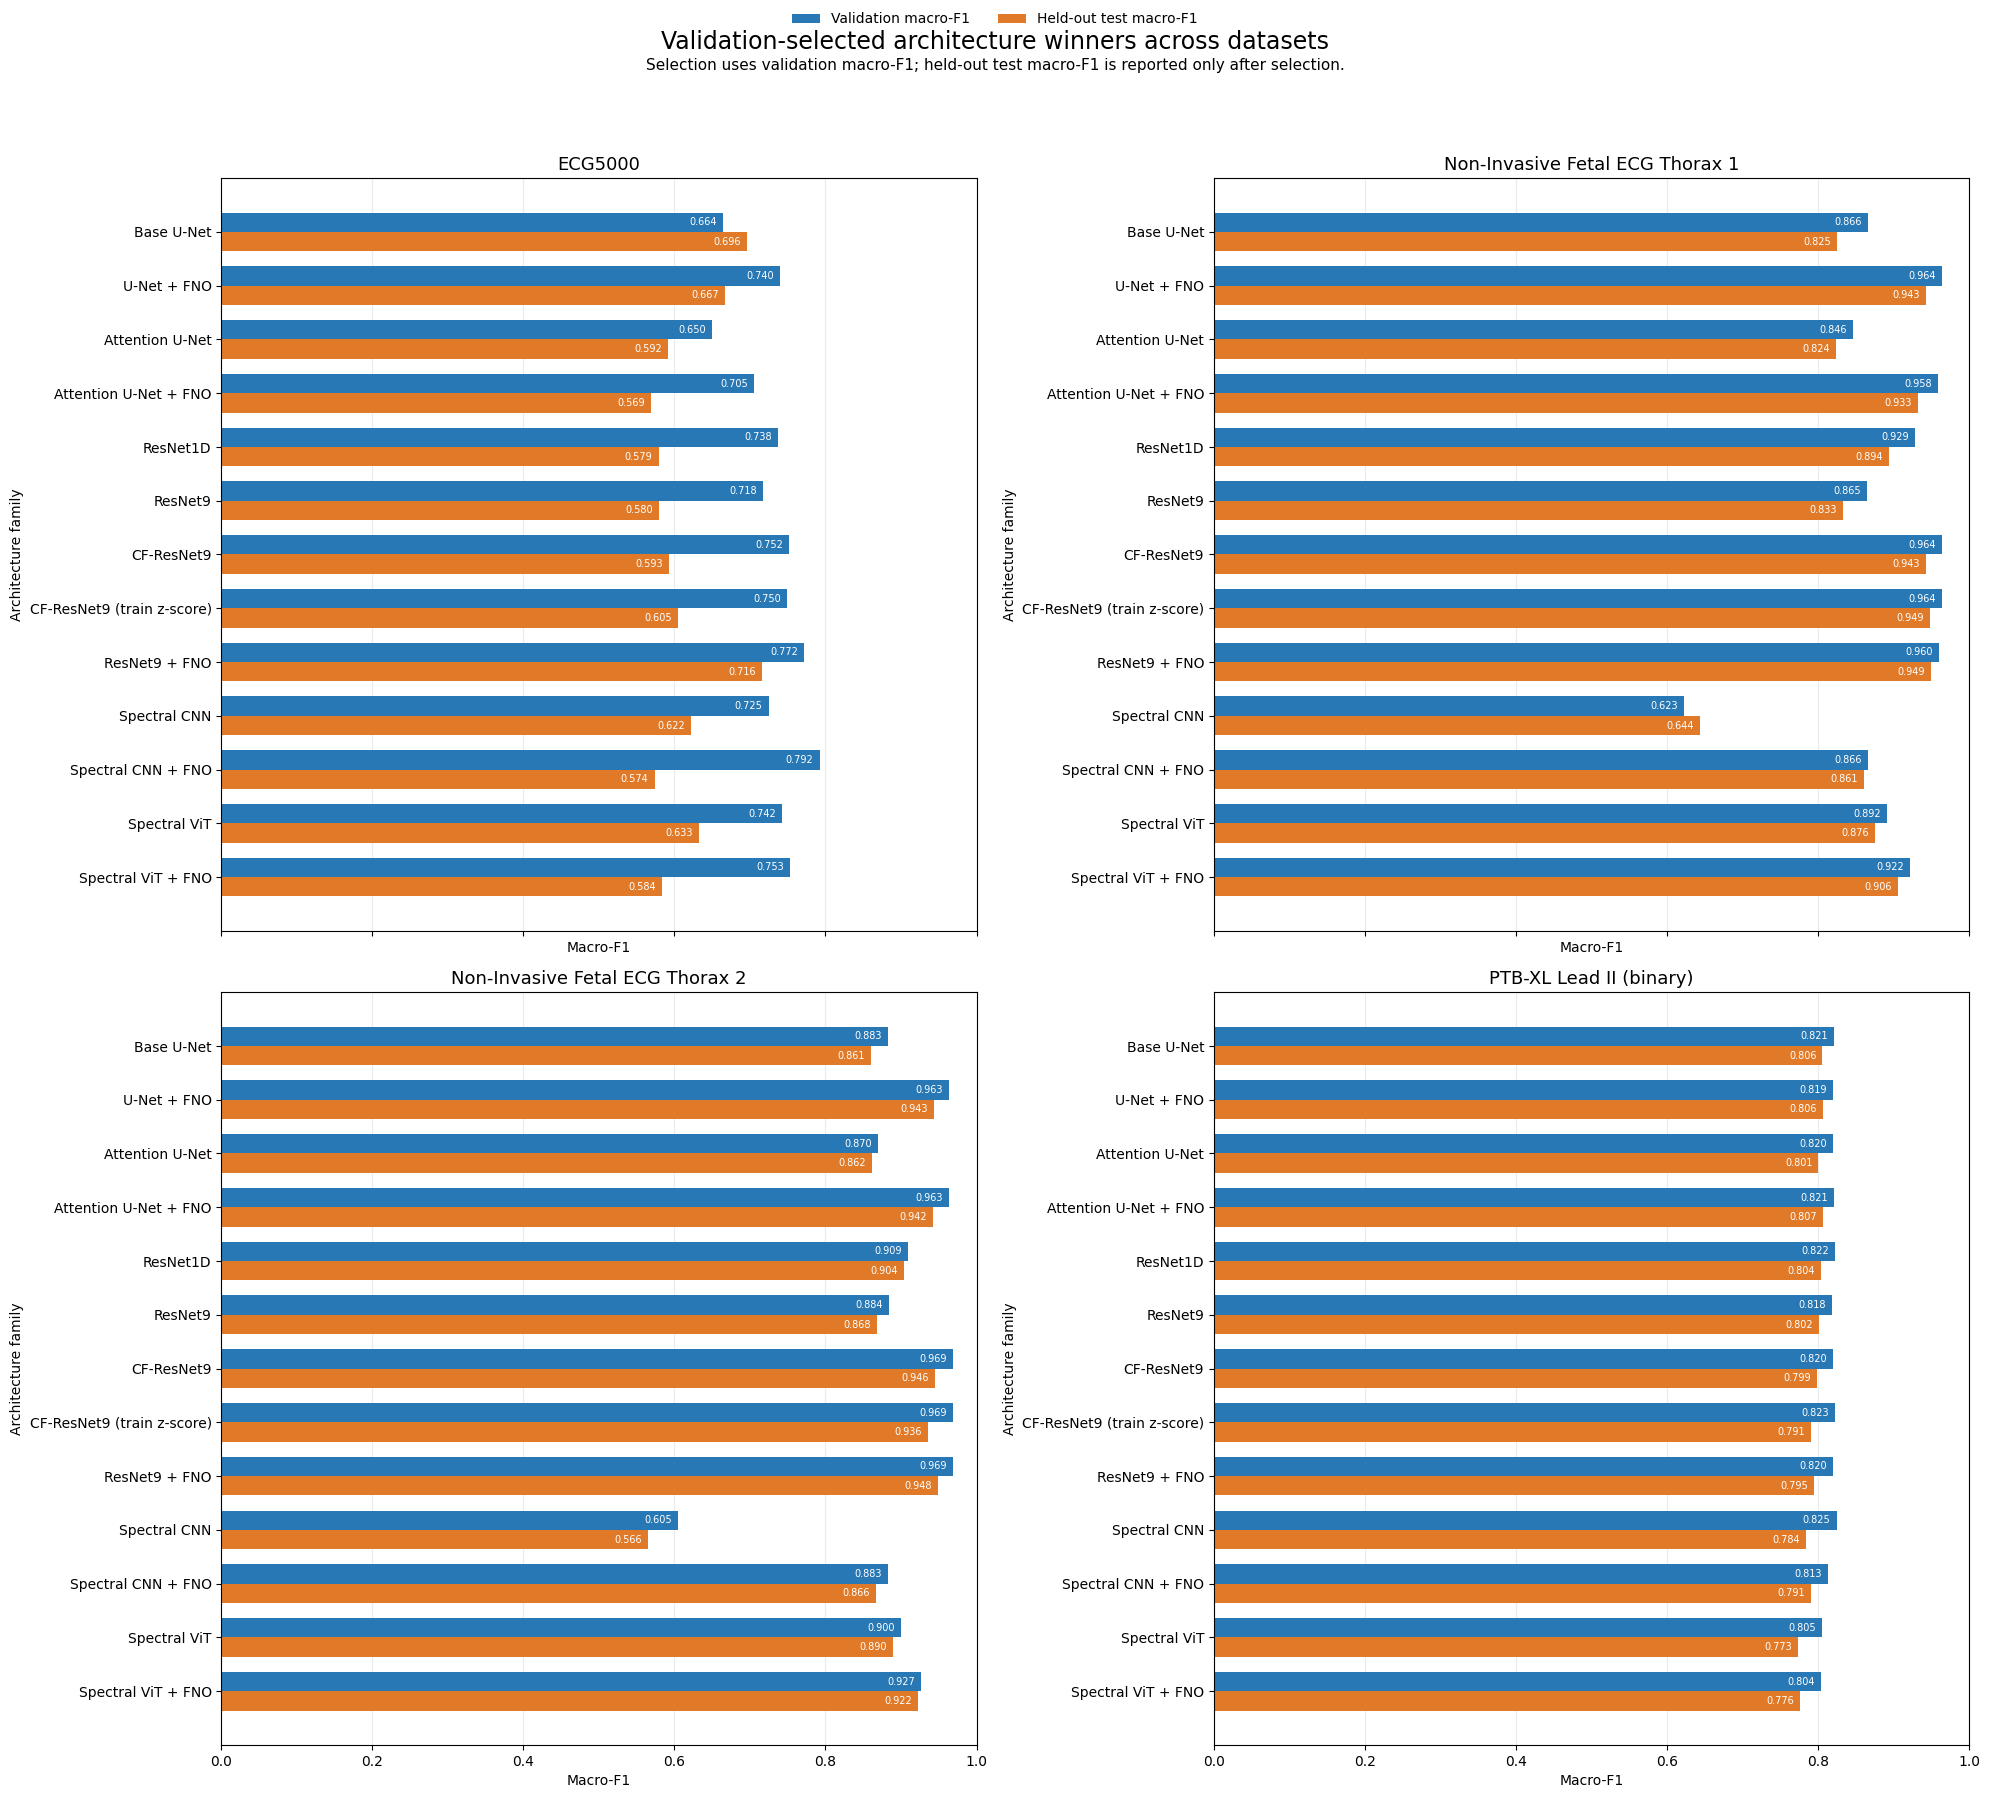

Saved: figs\results_best_overall_macro_f1_all_datasets.png
Plot audit: {'datasets': 4, 'rows': 52, 'families_per_dataset': {'ECG5000': 13, 'NonInvasiveFetalECGThorax1': 13, 'NonInvasiveFetalECGThorax2': 13, 'PTBXL_LEADII_BINARY': 13}, 'selection_metrics': ['val_macro_f1']}


,dataset_name,family,train_regime,selection_metric,val_macro_f1,test_macro_f1,val_balanced_acc,balanced_acc,test_acc,model_seed,params_million,run_dir
0,ECG5000,base_unet,e50,val_macro_f1,0.664415,0.696452,0.630535,0.666542,0.943000,42,0.368501,F:/Models/Unet/ECG5000/base_unet/e50/run_093
1,ECG5000,unet_fno,e50,val_macro_f1,0.739583,0.666681,0.706373,0.621530,0.953000,0,0.984485,F:/Models/Unet/ECG5000/unet_fno/e50/run_286
2,ECG5000,att_unet,e50,val_macro_f1,0.650116,0.591905,0.648980,0.596469,0.944000,7,0.380531,F:/Models/Unet/ECG5000/att_unet/e50/run_268
3,ECG5000,att_unet_fno,e50,val_macro_f1,0.705469,0.568580,0.661963,0.563487,0.940000,42,0.448891,F:/Models/Unet/ECG5000/att_unet_fno/e50/run_1206
4,ECG5000,resnet1d,e50,val_macro_f1,0.737655,0.578865,0.710160,0.564890,0.941000,7,0.250709,F:/Models/Unet/ECG5000/resnet1d/e50/run_005
5,ECG5000,resnet9,e50,val_macro_f1,0.717608,0.579756,0.701338,0.586746,0.929000,7,0.165845,F:/Models/Unet/ECG5000/resnet9/e50/run_316
6,ECG5000,cf_resnet9,e50,val_macro_f1,0.751668,0.592674,0.688080,0.577294,0.946000,0,0.051029,F:/Models/Unet/ECG5000/cf_resnet9/e50/run_088
7,ECG5000,cf_resnet9_train_zscore,e50,val_macro_f1,0.749662,0.605043,0.695386,0.584735,0.950000,7,0.269813,F:/Models/Unet/ECG5000/cf_resnet9_train_zscore...
8,ECG5000,fno_resnet9,e50,val_macro_f1,0.771756,0.715866,0.707944,0.667541,0.954000,0,0.171397,F:/Models/Unet/ECG5000/fno_resnet9/e50/run_409
9,ECG5000,spec_cnn,e50,val_macro_f1,0.724570,0.622450,0.668134,0.582260,0.943000,7,0.227813,F:/Models/Unet/ECG5000/spec_cnn/e50/run_518


In [129]:
# ===========================================================
# Plot: Validation-selected winners, validation vs test Macro-F1
#   One panel per dataset; held-out test scores are outcomes only.
#   -> figs/results_best_overall_macro_f1_all_datasets.png
# ===========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

required_results_globals = [
    "RESULTS_DATASET_SPECS", "EXPECTED_FAMILY_ORDER", "KNOWN_FAMILIES"
]
missing_results_globals = [
    name for name in required_results_globals if name not in globals()
]
if missing_results_globals:
    raise RuntimeError(
        "Run Results blocks 1-4 before this plot. "
        f"Missing definitions: {missing_results_globals}"
    )

DATASET_PLOT_LABELS = {
    "ECG5000": "ECG5000",
    "NonInvasiveFetalECGThorax1": "Non-Invasive Fetal ECG Thorax 1",
    "NonInvasiveFetalECGThorax2": "Non-Invasive Fetal ECG Thorax 2",
    "PTBXL_LEADII_BINARY": "PTB-XL Lead II (binary)",
}
FAMILY_PLOT_LABELS = {
    "base_unet": "Base U-Net",
    "unet_fno": "U-Net + FNO",
    "att_unet": "Attention U-Net",
    "att_unet_fno": "Attention U-Net + FNO",
    "resnet1d": "ResNet1D",
    "resnet9": "ResNet9",
    "cf_resnet9": "CF-ResNet9",
    "cf_resnet9_train_zscore": "CF-ResNet9 (train z-score)",
    "fno_resnet9": "ResNet9 + FNO",
    "spec_cnn": "Spectral CNN",
    "spec_cnn_fno": "Spectral CNN + FNO",
    "spec_vit": "Spectral ViT",
    "spec_vit_fno": "Spectral ViT + FNO",
}


def load_and_validate_best_overall(dataset_name, models_dir):
    if (
        "df_best_overall_by_dataset" in globals()
        and dataset_name in df_best_overall_by_dataset
    ):
        table = df_best_overall_by_dataset[dataset_name].copy()
    else:
        input_path = Path(models_dir) / "eval_best_overall_per_family.csv"
        if not input_path.exists():
            raise FileNotFoundError(
                f"Missing: {input_path}. Run Results block 4 first."
            )
        table = pd.read_csv(input_path)

    required = {
        "dataset_name", "family", "train_regime", "selection_metric",
        "val_macro_f1", "macro_f1", "val_balanced_acc", "balanced_acc",
        "test_acc", "params_million", "model_seed", "run_dir",
    }
    missing = required - set(table.columns)
    if missing:
        raise RuntimeError(
            f"{dataset_name}: best-overall results are missing columns: {missing}"
        )

    table = table.copy()
    for column in [
        "dataset_name", "family", "train_regime", "selection_metric", "run_dir"
    ]:
        table[column] = table[column].astype(str).str.strip()

    datasets_in_table = set(table["dataset_name"].unique())
    if datasets_in_table != {dataset_name}:
        raise RuntimeError(
            f"{dataset_name}: file contains dataset values {sorted(datasets_in_table)}"
        )
    if set(table["selection_metric"].unique()) != {"val_macro_f1"}:
        raise RuntimeError(
            f"{dataset_name}: winners were not selected exclusively by val_macro_f1"
        )

    numeric_columns = [
        "val_macro_f1", "macro_f1", "val_balanced_acc", "balanced_acc",
        "test_acc", "params_million", "model_seed",
    ]
    for column in numeric_columns:
        table[column] = pd.to_numeric(table[column], errors="coerce")
    if table[numeric_columns].isna().any().any():
        raise RuntimeError(f"{dataset_name}: non-numeric or missing plot values found")

    expected_families = [
        family for family in EXPECTED_FAMILY_ORDER if family in KNOWN_FAMILIES
    ]
    actual_families = set(table["family"])
    if actual_families != set(expected_families):
        missing_families = sorted(set(expected_families) - actual_families)
        extra_families = sorted(actual_families - set(expected_families))
        raise RuntimeError(
            f"{dataset_name}: unexpected family coverage. "
            f"Missing={missing_families}, extra={extra_families}"
        )
    if len(table) != len(expected_families) or table["family"].duplicated().any():
        raise RuntimeError(
            f"{dataset_name}: expected one winner for each of "
            f"{len(expected_families)} families, found {len(table)} rows"
        )

    table["family"] = pd.Categorical(
        table["family"], categories=expected_families, ordered=True
    )
    return table.sort_values("family").reset_index(drop=True)


best_overall_plot_by_dataset = {}
for dataset_spec in RESULTS_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    best_overall_plot_by_dataset[dataset_name] = load_and_validate_best_overall(
        dataset_name=dataset_name,
        models_dir=dataset_spec["models_dir"],
    )

dataset_order = [spec["dataset_name"] for spec in RESULTS_DATASET_SPECS]
if len(dataset_order) != 4:
    raise RuntimeError(
        f"This 2x2 plot expects four datasets, found {len(dataset_order)}"
    )

fig, axes = plt.subplots(2, 2, figsize=(20, 18), sharex=True)
bar_height = 0.36
validation_color = "#2878B5"
test_color = "#E07A28"

for axis, dataset_name in zip(axes.flat, dataset_order):
    table = best_overall_plot_by_dataset[dataset_name]
    y_positions = np.arange(len(table))
    family_labels = [FAMILY_PLOT_LABELS.get(str(value), str(value)) for value in table["family"]]

    validation_bars = axis.barh(
        y_positions - bar_height / 2,
        table["val_macro_f1"],
        height=bar_height,
        color=validation_color,
        label="Validation macro-F1",
    )
    test_bars = axis.barh(
        y_positions + bar_height / 2,
        table["macro_f1"],
        height=bar_height,
        color=test_color,
        label="Held-out test macro-F1",
    )

    axis.set_yticks(y_positions, labels=family_labels)
    axis.invert_yaxis()
    axis.set_xlim(0.0, 1.0)
    axis.set_xlabel("Macro-F1")
    axis.set_ylabel("Architecture family")
    axis.set_title(DATASET_PLOT_LABELS.get(dataset_name, dataset_name), fontsize=13)
    axis.grid(axis="x", alpha=0.25)
    axis.set_axisbelow(True)

    for bars in [validation_bars, test_bars]:
        for bar in bars:
            value = float(bar.get_width())
            axis.text(
                max(value - 0.008, 0.02),
                bar.get_y() + bar.get_height() / 2,
                f"{value:.3f}",
                va="center",
                ha="right",
                color="white",
                fontsize=7,
            )

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.suptitle(
    "Validation-selected architecture winners across datasets",
    fontsize=17,
    y=0.985,
)
fig.text(
    0.5,
    0.963,
    "Selection uses validation macro-F1; held-out test macro-F1 is reported only after selection.",
    ha="center",
    fontsize=11,
)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.945))

FIGURES_DIR = Path("figs")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
BEST_OVERALL_FIGURE_PATH = (
    FIGURES_DIR / "results_best_overall_macro_f1_all_datasets.png"
)
fig.savefig(BEST_OVERALL_FIGURE_PATH, dpi=220, bbox_inches="tight")
plt.show()

best_overall_plot_data = pd.concat(
    [best_overall_plot_by_dataset[name] for name in dataset_order],
    ignore_index=True,
)
best_overall_plot_table = best_overall_plot_data[
    [
        "dataset_name", "family", "train_regime", "selection_metric",
        "val_macro_f1", "macro_f1", "val_balanced_acc", "balanced_acc",
        "test_acc", "model_seed", "params_million", "run_dir",
    ]
].rename(columns={"macro_f1": "test_macro_f1"})

print(f"Saved: {BEST_OVERALL_FIGURE_PATH}")
print(
    "Plot audit:",
    {
        "datasets": best_overall_plot_table["dataset_name"].nunique(),
        "rows": len(best_overall_plot_table),
        "families_per_dataset": best_overall_plot_table.groupby("dataset_name")["family"].nunique().to_dict(),
        "selection_metrics": sorted(best_overall_plot_table["selection_metric"].unique()),
    },
)
best_overall_plot_table


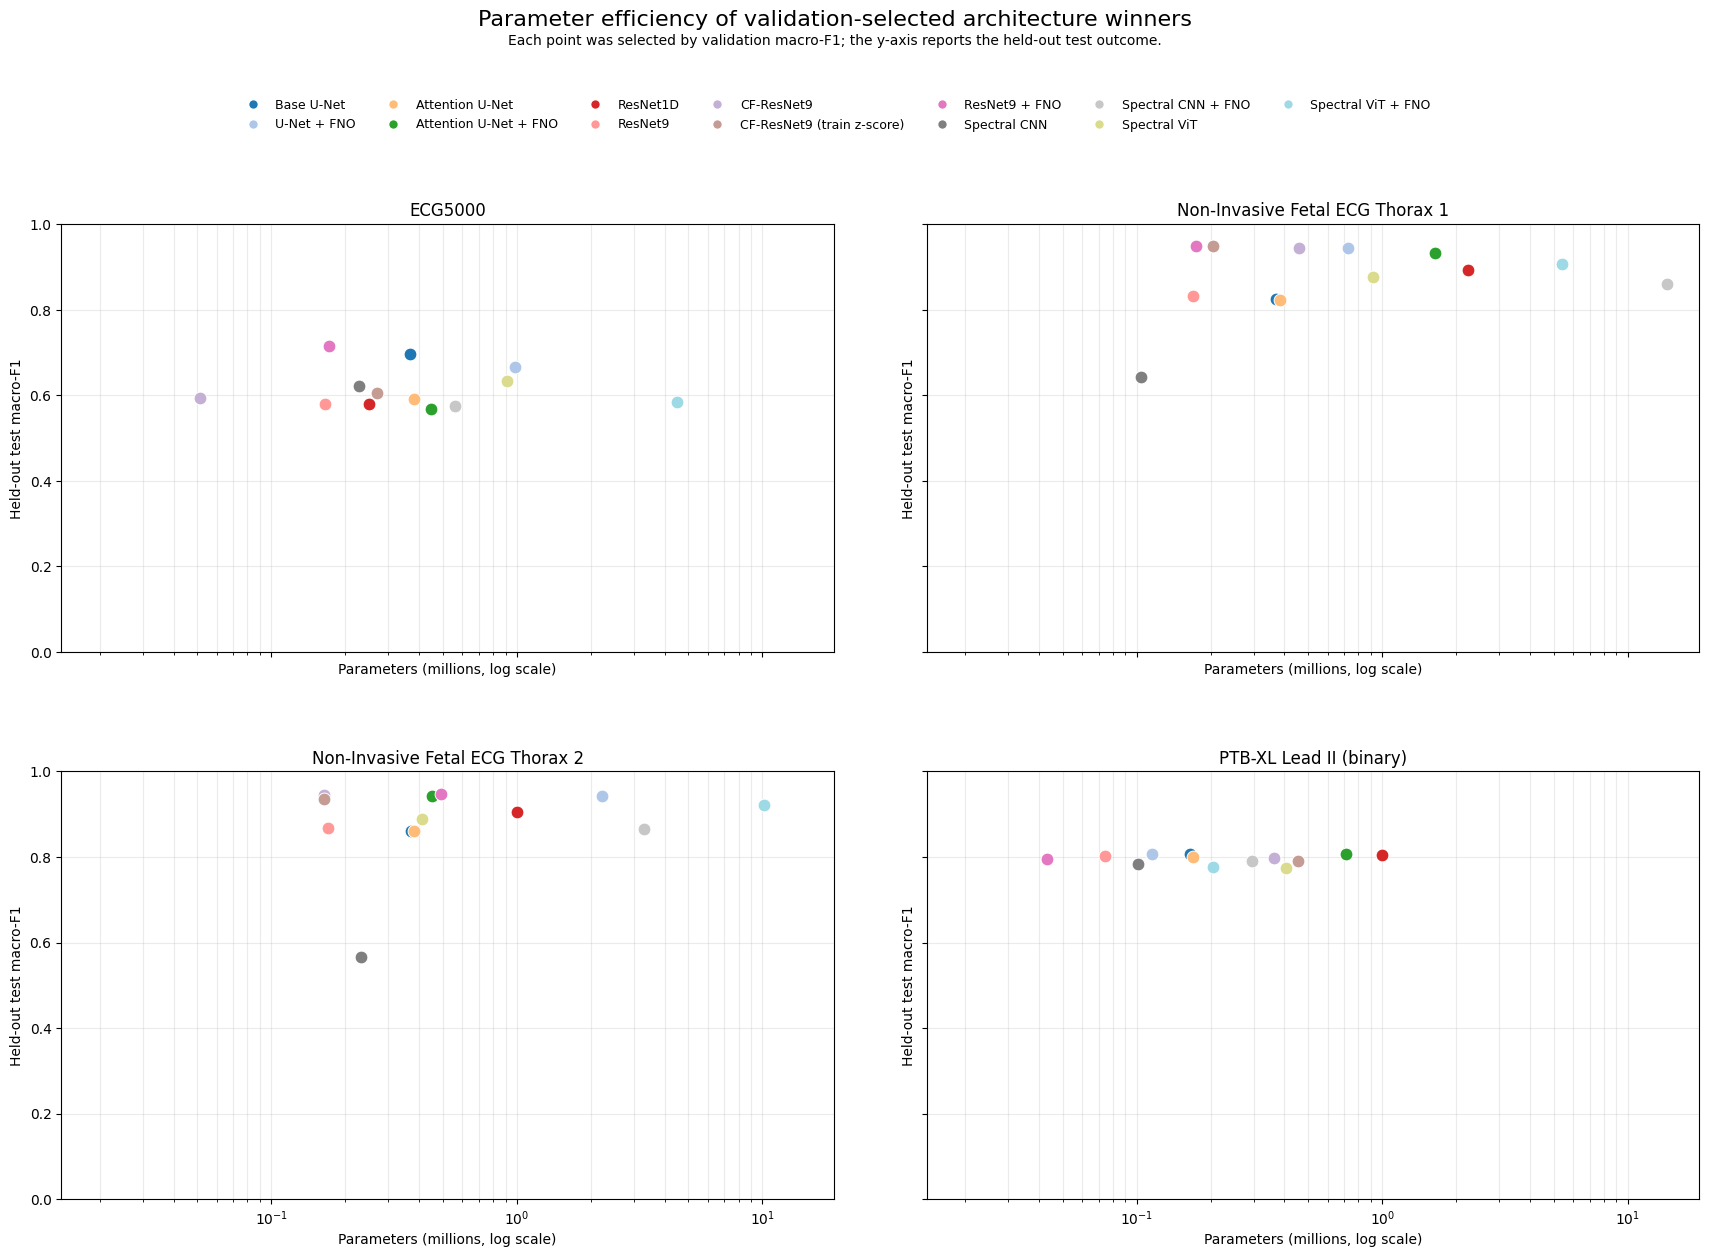

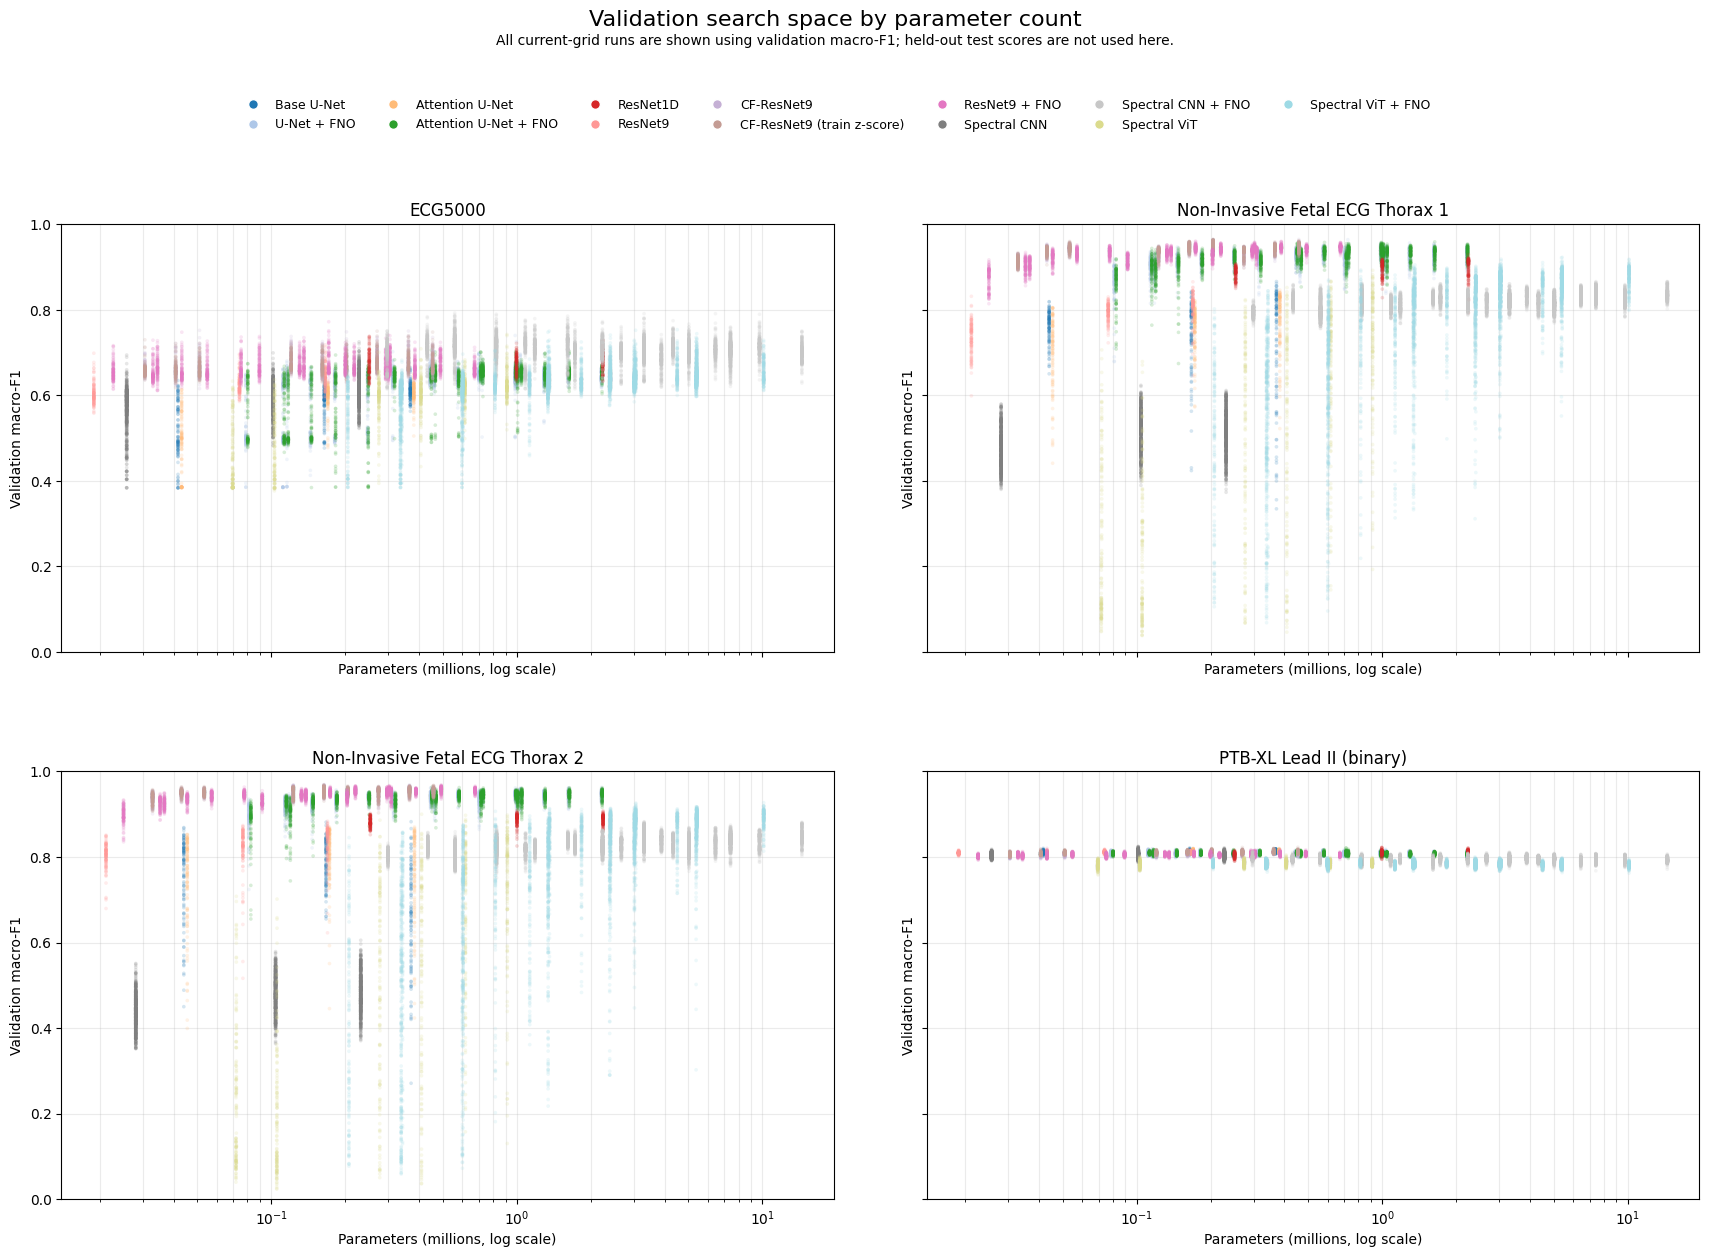

Saved: figs\results_params_vs_test_macro_f1_winners_all_datasets.png
Saved: figs\results_params_vs_validation_macro_f1_all_runs.png
Parameter-plot audit: {'winner_rows': 52, 'all_run_rows': 82080, 'all_runs_per_dataset': {'ECG5000': 20520, 'NonInvasiveFetalECGThorax1': 20520, 'NonInvasiveFetalECGThorax2': 20520, 'PTBXL_LEADII_BINARY': 20520}, 'families_per_dataset': {'ECG5000': 13, 'NonInvasiveFetalECGThorax1': 13, 'NonInvasiveFetalECGThorax2': 13, 'PTBXL_LEADII_BINARY': 13}, 'selection_metrics': ['val_macro_f1']}


,dataset_name,family,train_regime,selection_metric,val_macro_f1,test_macro_f1,params_million,model_seed,config_key,run_dir
0,ECG5000,base_unet,e50,val_macro_f1,0.664415,0.696452,0.368501,42,e795e560f074ff00b8fd1ec3d53a7333,F:/Models/Unet/ECG5000/base_unet/e50/run_093
1,ECG5000,unet_fno,e50,val_macro_f1,0.739583,0.666681,0.984485,0,8c58c3845cd2b8bb4843440355cc50cd,F:/Models/Unet/ECG5000/unet_fno/e50/run_286
2,ECG5000,att_unet,e50,val_macro_f1,0.650116,0.591905,0.380531,7,6a1fbdc46635164692819024318e3d6a,F:/Models/Unet/ECG5000/att_unet/e50/run_268
3,ECG5000,att_unet_fno,e50,val_macro_f1,0.705469,0.568580,0.448891,42,2a7436a9be54e00394967956a3b03c76,F:/Models/Unet/ECG5000/att_unet_fno/e50/run_1206
4,ECG5000,resnet1d,e50,val_macro_f1,0.737655,0.578865,0.250709,7,fd786b2569727ece094206b651acd869,F:/Models/Unet/ECG5000/resnet1d/e50/run_005
5,ECG5000,resnet9,e50,val_macro_f1,0.717608,0.579756,0.165845,7,427a06b4c95ede8738bd66a981c92884,F:/Models/Unet/ECG5000/resnet9/e50/run_316
6,ECG5000,cf_resnet9,e50,val_macro_f1,0.751668,0.592674,0.051029,0,8ae239da1f97c60a39a5bd2f9f3b66ca,F:/Models/Unet/ECG5000/cf_resnet9/e50/run_088
7,ECG5000,cf_resnet9_train_zscore,e50,val_macro_f1,0.749662,0.605043,0.269813,7,def7e83405255b80ebadba73b7274f13,F:/Models/Unet/ECG5000/cf_resnet9_train_zscore...
8,ECG5000,fno_resnet9,e50,val_macro_f1,0.771756,0.715866,0.171397,0,f15e2dc12c9e6a50c55114731a370525,F:/Models/Unet/ECG5000/fno_resnet9/e50/run_409
9,ECG5000,spec_cnn,e50,val_macro_f1,0.724570,0.622450,0.227813,7,daa4ba8a434a54d1d561fd68f1ac899f,F:/Models/Unet/ECG5000/spec_cnn/e50/run_518


In [130]:
# ===========================================================
# Parameter count vs Macro-F1 across all datasets
#   A) Validation-selected winners -> held-out test Macro-F1
#   B) Full search space -> validation Macro-F1
#   -> figs/results_params_vs_test_macro_f1_winners_all_datasets.png
#   -> figs/results_params_vs_validation_macro_f1_all_runs.png
# ===========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

required_results_globals = [
    "RESULTS_DATASET_SPECS", "EXPECTED_FAMILY_ORDER", "KNOWN_FAMILIES"
]
missing_results_globals = [
    name for name in required_results_globals if name not in globals()
]
if missing_results_globals:
    raise RuntimeError(
        "Run Results blocks 1-4 before this plot. "
        f"Missing definitions: {missing_results_globals}"
    )

PARAM_DATASET_LABELS = {
    "ECG5000": "ECG5000",
    "NonInvasiveFetalECGThorax1": "Non-Invasive Fetal ECG Thorax 1",
    "NonInvasiveFetalECGThorax2": "Non-Invasive Fetal ECG Thorax 2",
    "PTBXL_LEADII_BINARY": "PTB-XL Lead II (binary)",
}
PARAM_FAMILY_LABELS = {
    "base_unet": "Base U-Net",
    "unet_fno": "U-Net + FNO",
    "att_unet": "Attention U-Net",
    "att_unet_fno": "Attention U-Net + FNO",
    "resnet1d": "ResNet1D",
    "resnet9": "ResNet9",
    "cf_resnet9": "CF-ResNet9",
    "cf_resnet9_train_zscore": "CF-ResNet9 (train z-score)",
    "fno_resnet9": "ResNet9 + FNO",
    "spec_cnn": "Spectral CNN",
    "spec_cnn_fno": "Spectral CNN + FNO",
    "spec_vit": "Spectral ViT",
    "spec_vit_fno": "Spectral ViT + FNO",
}

PARAM_FAMILIES = [
    family for family in EXPECTED_FAMILY_ORDER if family in KNOWN_FAMILIES
]
family_color_values = plt.get_cmap("tab20")(
    np.linspace(0.0, 0.95, len(PARAM_FAMILIES))
)
PARAM_FAMILY_COLORS = dict(zip(PARAM_FAMILIES, family_color_values))


def _load_parameter_table(dataset_name, models_dir, kind):
    if kind == "best":
        memory_name = "df_best_overall_by_dataset"
        filename = "eval_best_overall_per_family.csv"
        required = {
            "dataset_name", "family", "train_regime", "selection_metric",
            "config_key", "params_million", "val_macro_f1", "macro_f1",
            "model_seed", "run_dir",
        }
    elif kind == "all":
        memory_name = "df_eval_all_by_dataset"
        filename = "eval_stats_all.csv"
        required = {
            "dataset_name", "family", "train_regime", "config_key",
            "params_million", "val_macro_f1", "macro_f1", "model_seed",
            "run_dir",
        }
    else:
        raise ValueError(f"Unknown parameter-table kind: {kind}")

    memory_tables = globals().get(memory_name)
    if isinstance(memory_tables, dict) and dataset_name in memory_tables:
        table = memory_tables[dataset_name].copy()
    else:
        input_path = Path(models_dir) / filename
        if not input_path.exists():
            raise FileNotFoundError(
                f"Missing: {input_path}. Run the earlier Results blocks first."
            )
        table = pd.read_csv(input_path)

    missing = required - set(table.columns)
    if missing:
        raise RuntimeError(f"{dataset_name}/{filename} missing columns: {missing}")

    table = table.copy()
    text_columns = [
        "dataset_name", "family", "train_regime", "config_key", "run_dir"
    ]
    if kind == "best":
        text_columns.append("selection_metric")
    for column in text_columns:
        table[column] = table[column].astype(str).str.strip()

    datasets_in_table = set(table["dataset_name"].unique())
    if datasets_in_table != {dataset_name}:
        raise RuntimeError(
            f"{dataset_name}/{filename} contains dataset values "
            f"{sorted(datasets_in_table)}"
        )

    numeric_columns = [
        "params_million", "val_macro_f1", "macro_f1", "model_seed"
    ]
    for column in numeric_columns:
        table[column] = pd.to_numeric(table[column], errors="coerce")
    if table[numeric_columns].isna().any().any():
        raise RuntimeError(
            f"{dataset_name}/{filename} contains missing or non-numeric plot values"
        )
    if (table["params_million"] <= 0).any():
        raise RuntimeError(
            f"{dataset_name}/{filename} contains non-positive parameter counts"
        )

    actual_families = set(table["family"])
    if actual_families != set(PARAM_FAMILIES):
        missing_families = sorted(set(PARAM_FAMILIES) - actual_families)
        extra_families = sorted(actual_families - set(PARAM_FAMILIES))
        raise RuntimeError(
            f"{dataset_name}/{filename} has unexpected family coverage. "
            f"Missing={missing_families}, extra={extra_families}"
        )
    if table["config_key"].duplicated().any():
        duplicate_count = int(table["config_key"].duplicated(keep=False).sum())
        raise RuntimeError(
            f"{dataset_name}/{filename} contains {duplicate_count} rows with "
            "duplicate configuration keys"
        )

    if kind == "best":
        if set(table["selection_metric"].unique()) != {"val_macro_f1"}:
            raise RuntimeError(
                f"{dataset_name}: winners were not selected exclusively by val_macro_f1"
            )
        if len(table) != len(PARAM_FAMILIES) or table["family"].duplicated().any():
            raise RuntimeError(
                f"{dataset_name}: expected one winner for each of "
                f"{len(PARAM_FAMILIES)} families, found {len(table)} rows"
            )

    table["family"] = pd.Categorical(
        table["family"], categories=PARAM_FAMILIES, ordered=True
    )
    return table.sort_values(["family", "config_key"]).reset_index(drop=True)


params_best_by_dataset = {}
params_all_by_dataset = {}
for dataset_spec in RESULTS_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    models_dir = dataset_spec["models_dir"]
    params_best_by_dataset[dataset_name] = _load_parameter_table(
        dataset_name, models_dir, "best"
    )
    params_all_by_dataset[dataset_name] = _load_parameter_table(
        dataset_name, models_dir, "all"
    )

    best_keys = set(params_best_by_dataset[dataset_name]["config_key"].astype(str))
    all_keys = set(params_all_by_dataset[dataset_name]["config_key"].astype(str))
    if not best_keys.issubset(all_keys):
        raise RuntimeError(
            f"{dataset_name}: one or more selected winners are absent from eval_stats_all.csv"
        )

dataset_order = [spec["dataset_name"] for spec in RESULTS_DATASET_SPECS]
if len(dataset_order) != 4:
    raise RuntimeError(
        f"These 2x2 parameter plots expect four datasets, found {len(dataset_order)}"
    )

all_parameter_values = pd.concat(
    [table["params_million"] for table in params_all_by_dataset.values()],
    ignore_index=True,
)
x_min = float(all_parameter_values.min()) / 1.35
x_max = float(all_parameter_values.max()) * 1.35

def _parameter_legend_handles():
    return [
        Line2D(
            [0], [0], marker="o", linestyle="none", markersize=7,
            markerfacecolor=PARAM_FAMILY_COLORS[family], markeredgecolor="white",
            label=PARAM_FAMILY_LABELS.get(family, family),
        )
        for family in PARAM_FAMILIES
    ]


def _format_parameter_axis(axis, dataset_name, y_label):
    axis.set_xscale("log")
    axis.set_xlim(x_min, x_max)
    axis.set_ylim(0.0, 1.0)
    axis.set_xlabel("Parameters (millions, log scale)")
    axis.set_ylabel(y_label)
    axis.set_title(PARAM_DATASET_LABELS.get(dataset_name, dataset_name), fontsize=12)
    axis.grid(alpha=0.25, which="both")
    axis.set_axisbelow(True)


# A) The canonical validation-selected winners, reporting test outcomes.
fig_winners, winner_axes = plt.subplots(2, 2, figsize=(18, 13), sharex=True, sharey=True)
for axis, dataset_name in zip(winner_axes.flat, dataset_order):
    table = params_best_by_dataset[dataset_name]
    for family in PARAM_FAMILIES:
        row = table[table["family"] == family]
        axis.scatter(
            row["params_million"],
            row["macro_f1"],
            s=85,
            color=PARAM_FAMILY_COLORS[family],
            edgecolor="white",
            linewidth=0.7,
            zorder=3,
        )
    _format_parameter_axis(axis, dataset_name, "Held-out test macro-F1")

fig_winners.legend(
    handles=_parameter_legend_handles(),
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=7,
    frameon=False,
    fontsize=9,
)
fig_winners.suptitle(
    "Parameter efficiency of validation-selected architecture winners",
    fontsize=16,
    y=0.985,
)
fig_winners.text(
    0.5,
    0.958,
    "Each point was selected by validation macro-F1; the y-axis reports the held-out test outcome.",
    ha="center",
    fontsize=10,
)
fig_winners.subplots_adjust(
    left=0.07, right=0.98, bottom=0.07, top=0.82, hspace=0.28, wspace=0.12
)

FIGURES_DIR = Path("figs")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PARAM_WINNERS_FIGURE_PATH = (
    FIGURES_DIR / "results_params_vs_test_macro_f1_winners_all_datasets.png"
)
fig_winners.savefig(PARAM_WINNERS_FIGURE_PATH, dpi=220, bbox_inches="tight")
plt.show()


# B) The full hyperparameter search, using validation scores only.
fig_search, search_axes = plt.subplots(2, 2, figsize=(18, 13), sharex=True, sharey=True)
for axis, dataset_name in zip(search_axes.flat, dataset_order):
    table = params_all_by_dataset[dataset_name]
    for family in PARAM_FAMILIES:
        subset = table[table["family"] == family]
        axis.scatter(
            subset["params_million"],
            subset["val_macro_f1"],
            s=7,
            alpha=0.18,
            color=PARAM_FAMILY_COLORS[family],
            edgecolors="none",
            rasterized=True,
        )
    _format_parameter_axis(axis, dataset_name, "Validation macro-F1")

fig_search.legend(
    handles=_parameter_legend_handles(),
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=7,
    frameon=False,
    fontsize=9,
)
fig_search.suptitle(
    "Validation search space by parameter count",
    fontsize=16,
    y=0.985,
)
fig_search.text(
    0.5,
    0.958,
    "All current-grid runs are shown using validation macro-F1; held-out test scores are not used here.",
    ha="center",
    fontsize=10,
)
fig_search.subplots_adjust(
    left=0.07, right=0.98, bottom=0.07, top=0.82, hspace=0.28, wspace=0.12
)

PARAM_SEARCH_FIGURE_PATH = (
    FIGURES_DIR / "results_params_vs_validation_macro_f1_all_runs.png"
)
fig_search.savefig(PARAM_SEARCH_FIGURE_PATH, dpi=220, bbox_inches="tight")
plt.show()

params_best_all_datasets = pd.concat(
    [params_best_by_dataset[name] for name in dataset_order],
    ignore_index=True,
)
params_best_plot_table = params_best_all_datasets[
    [
        "dataset_name", "family", "train_regime", "selection_metric",
        "val_macro_f1", "macro_f1", "params_million", "model_seed",
        "config_key", "run_dir",
    ]
].rename(columns={"macro_f1": "test_macro_f1"})

print(f"Saved: {PARAM_WINNERS_FIGURE_PATH}")
print(f"Saved: {PARAM_SEARCH_FIGURE_PATH}")
print(
    "Parameter-plot audit:",
    {
        "winner_rows": len(params_best_plot_table),
        "all_run_rows": int(sum(len(table) for table in params_all_by_dataset.values())),
        "all_runs_per_dataset": {
            name: len(table) for name, table in params_all_by_dataset.items()
        },
        "families_per_dataset": params_best_plot_table.groupby("dataset_name")["family"].nunique().to_dict(),
        "selection_metrics": sorted(params_best_plot_table["selection_metric"].unique()),
    },
)
params_best_plot_table


C:\Users\markh\AppData\Local\Temp\ipykernel_16452\909727288.py:214: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = axis.boxplot(
C:\Users\markh\AppData\Local\Temp\ipykernel_16452\909727288.py:214: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = axis.boxplot(
C:\Users\markh\AppData\Local\Temp\ipykernel_16452\909727288.py:214: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = axis.boxplot(
C:\Users\markh\AppData\Local\Temp\ipykernel_16452\909727288.py:214: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name

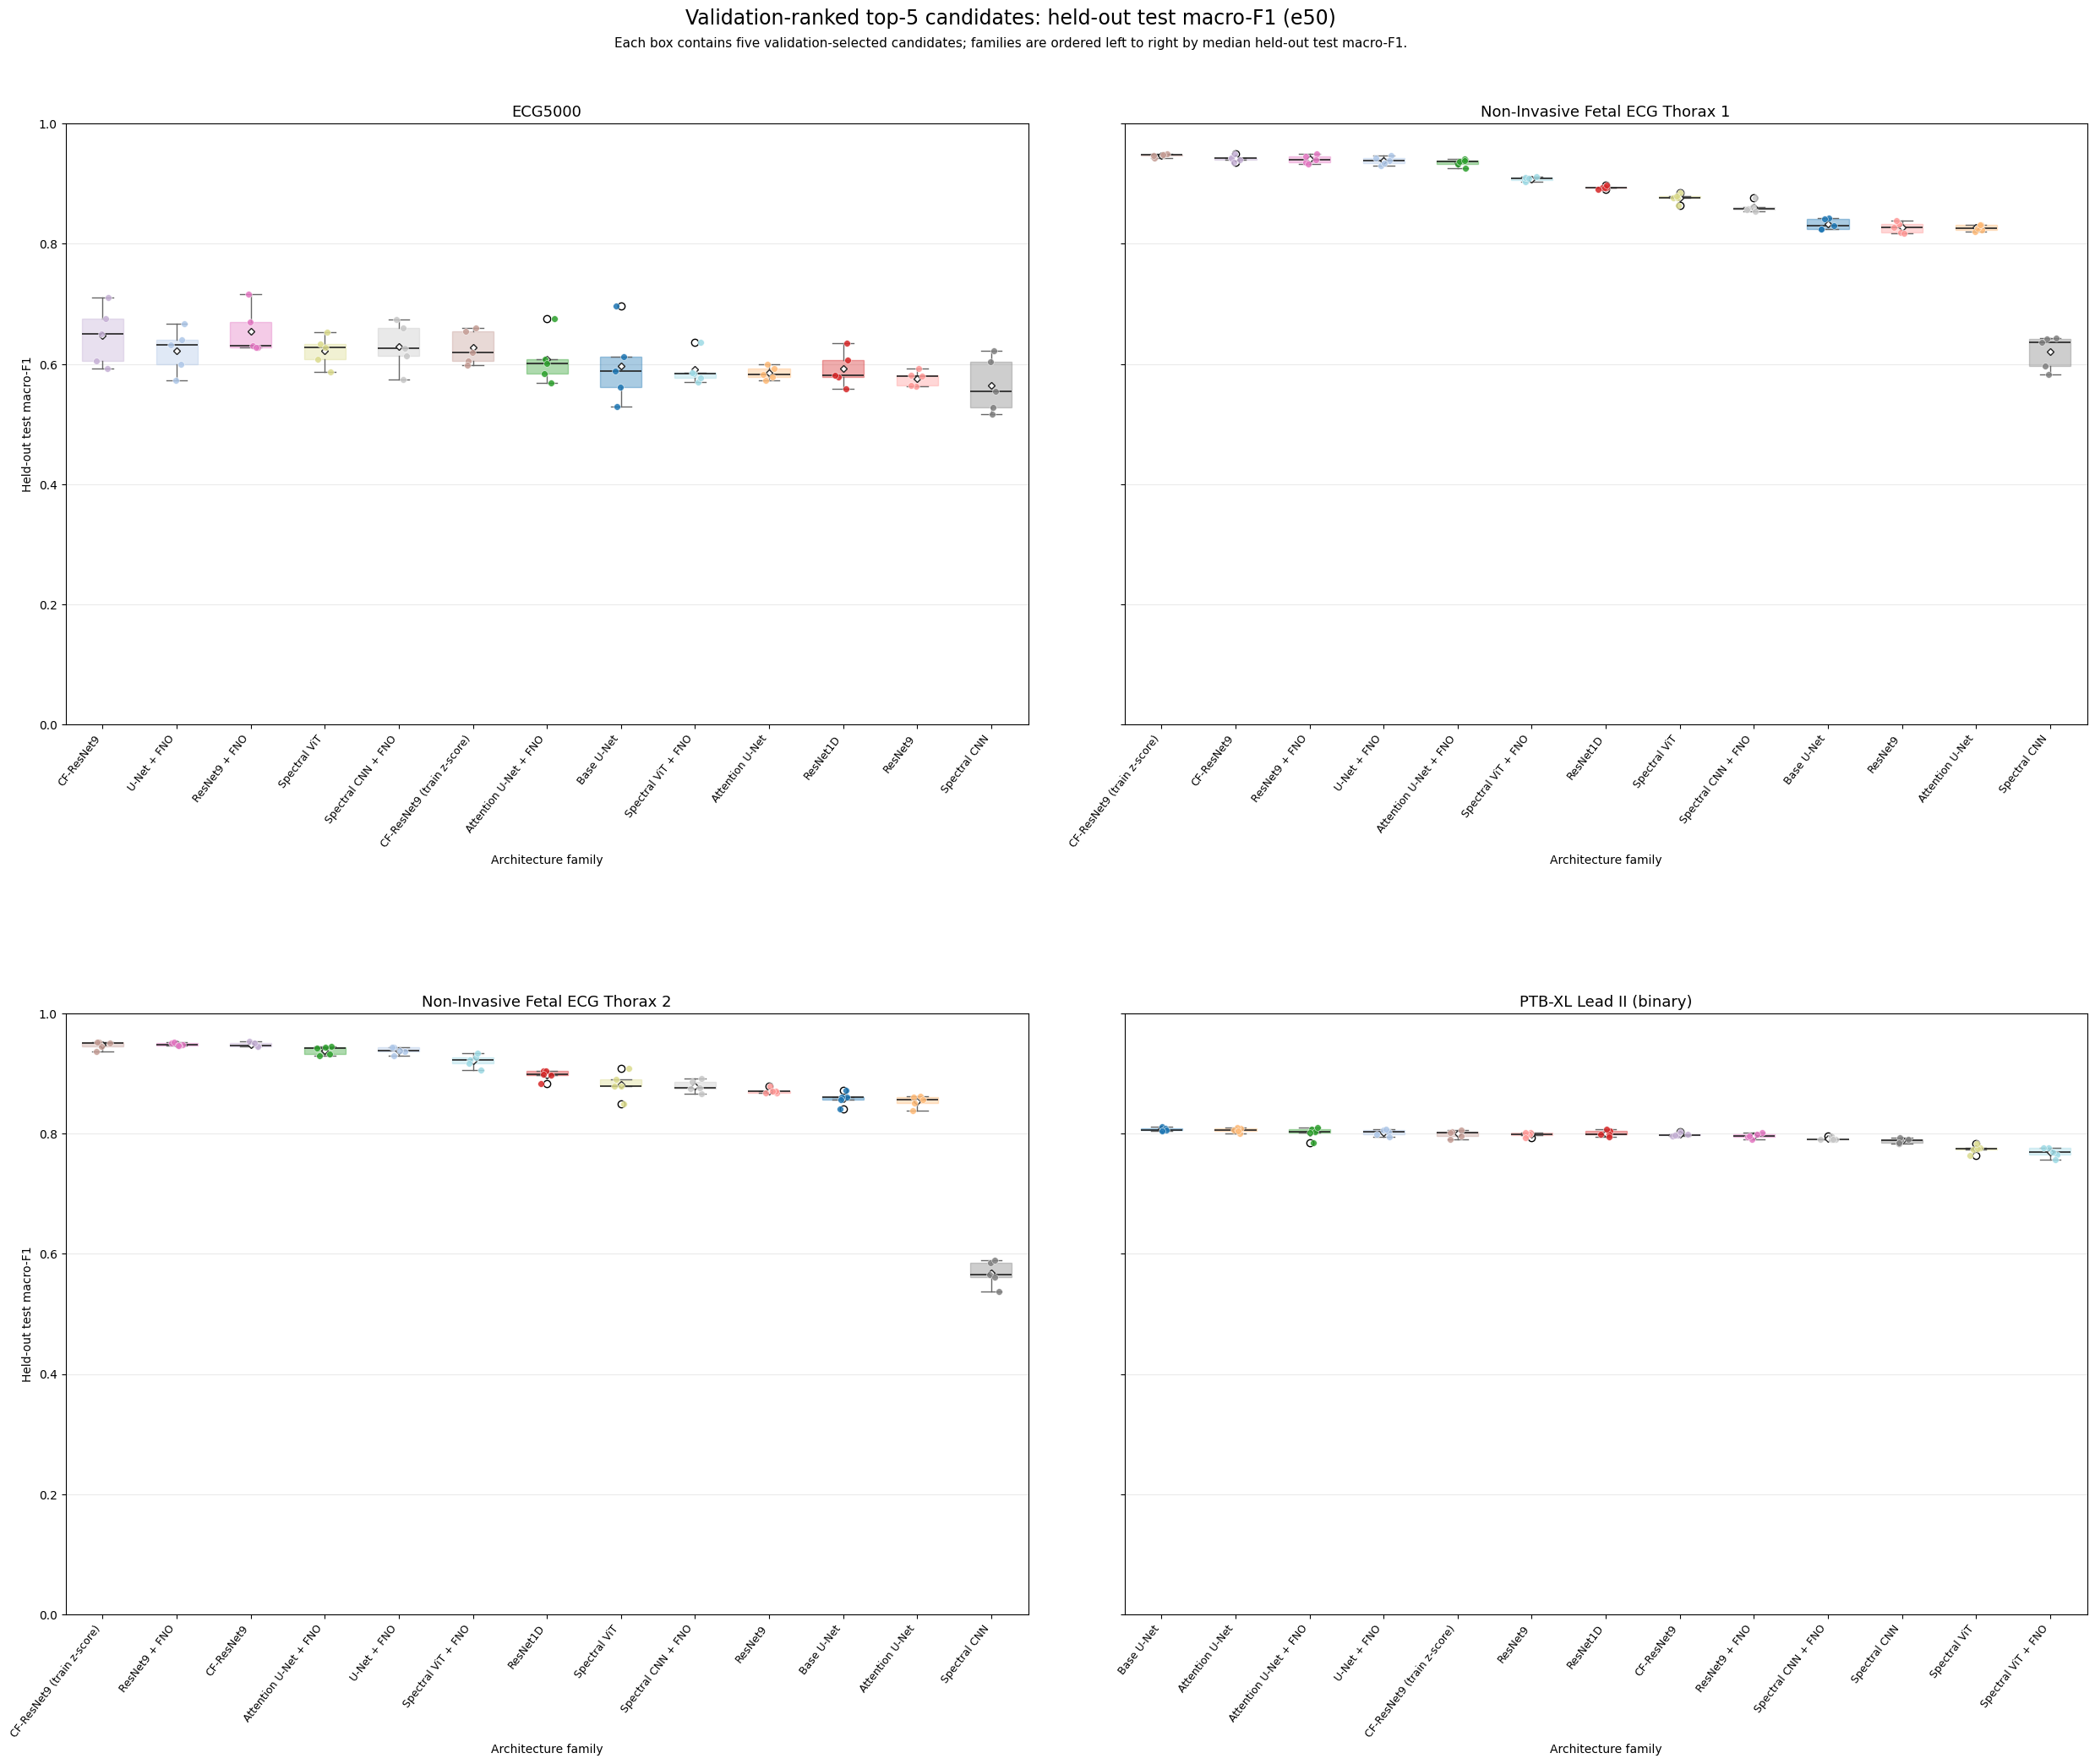

C:\Users\markh\AppData\Local\Temp\ipykernel_16452\909727288.py:214: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = axis.boxplot(


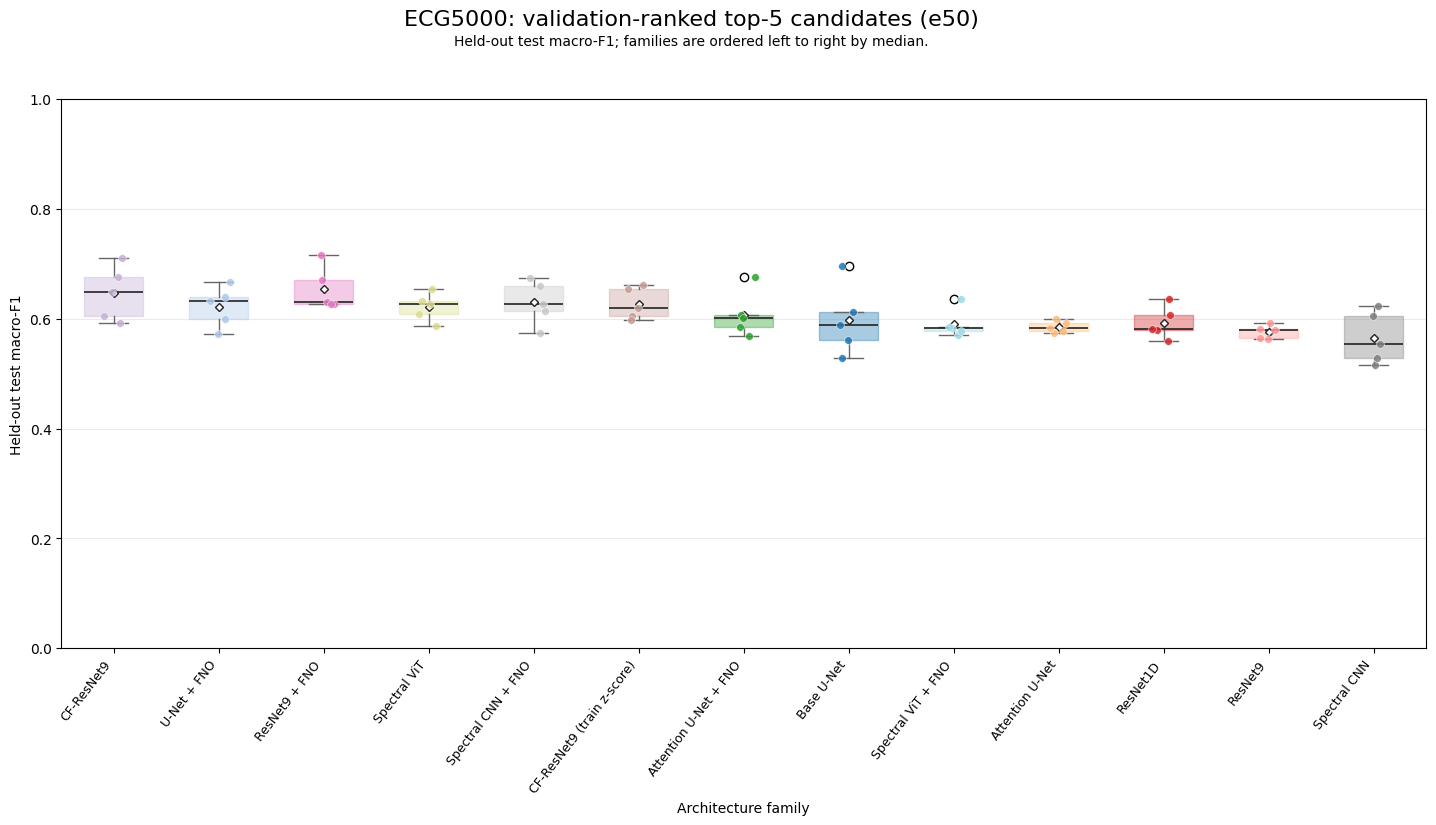

C:\Users\markh\AppData\Local\Temp\ipykernel_16452\909727288.py:214: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = axis.boxplot(


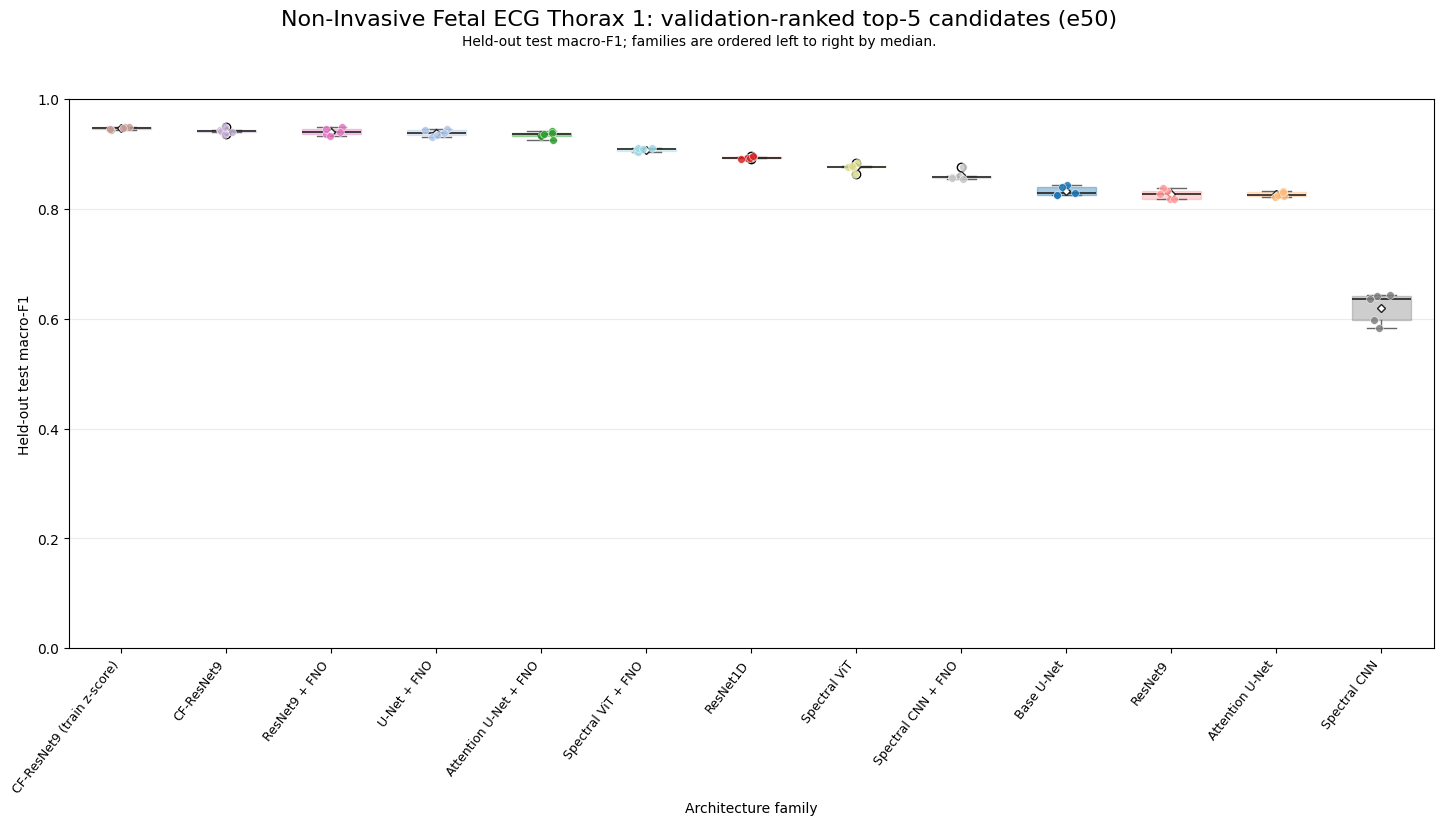

C:\Users\markh\AppData\Local\Temp\ipykernel_16452\909727288.py:214: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = axis.boxplot(


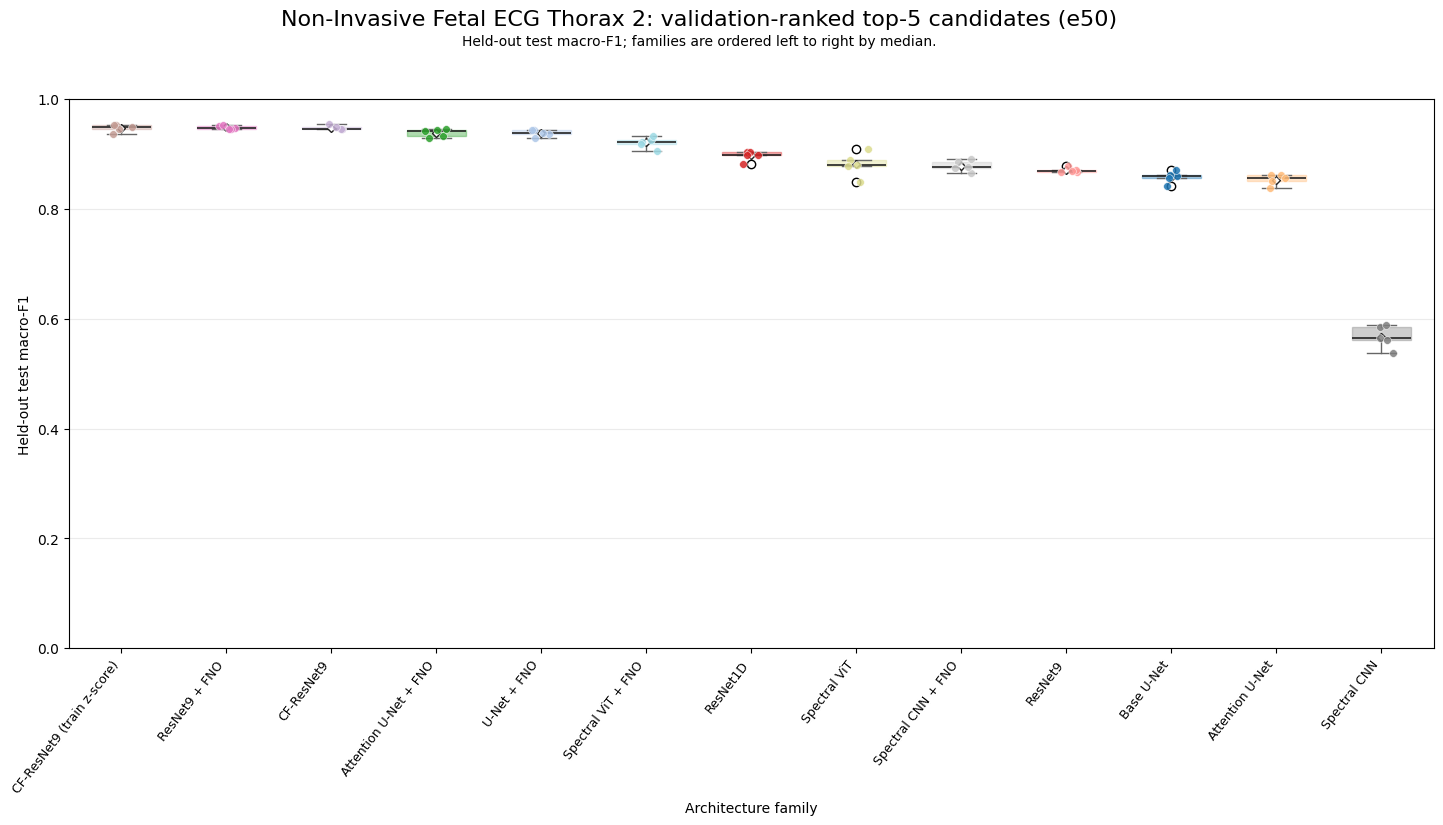

C:\Users\markh\AppData\Local\Temp\ipykernel_16452\909727288.py:214: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = axis.boxplot(


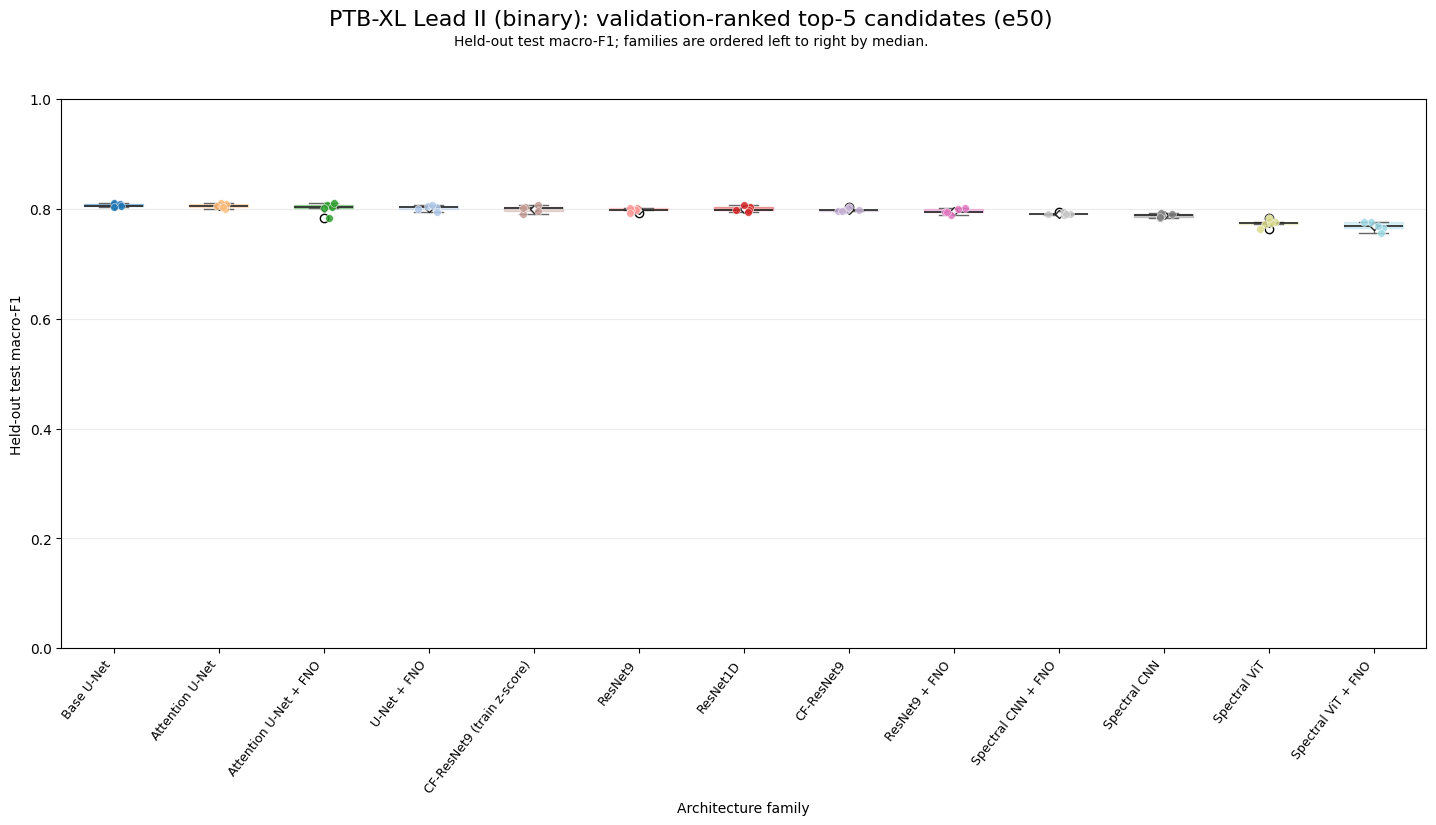

Saved combined (e50): figs\results_top5_test_macro_f1_e50_all_datasets.png
Saved ECG5000 (e50): figs\ECG5000\top5_test_macro_f1_e50.png
Saved NonInvasiveFetalECGThorax1 (e50): figs\NonInvasiveFetalECGThorax1\top5_test_macro_f1_e50.png
Saved NonInvasiveFetalECGThorax2 (e50): figs\NonInvasiveFetalECGThorax2\top5_test_macro_f1_e50.png
Saved PTBXL_LEADII_BINARY (e50): figs\PTBXL_LEADII_BINARY\top5_test_macro_f1_e50.png
Top-5 plot audit: {'rows': 260, 'datasets': 4, 'regimes': ['e50'], 'groups': 52, 'group_sizes': [5], 'ranking_metrics': ['val_macro_f1'], 'top_family_by_dataset': {'ECG5000': 'cf_resnet9', 'NonInvasiveFetalECGThorax1': 'cf_resnet9_train_zscore', 'NonInvasiveFetalECGThorax2': 'cf_resnet9_train_zscore', 'PTBXL_LEADII_BINARY': 'base_unet'}, 'standalone_figures': 4}


,dataset_name,family,train_regime,rank_in_group,ranking_metric,validation_macro_f1,test_macro_f1,model_seed,params_million,config_key,run_dir
0,ECG5000,base_unet,e50,1,val_macro_f1,0.664415,0.696452,42,0.368501,e795e560f074ff00b8fd1ec3d53a7333,F:/Models/Unet/ECG5000/base_unet/e50/run_093
1,ECG5000,base_unet,e50,2,val_macro_f1,0.660983,0.587906,42,0.368501,8783f65932824d9cc6291c056b9c93ec,F:/Models/Unet/ECG5000/base_unet/e50/run_312
2,ECG5000,base_unet,e50,3,val_macro_f1,0.658591,0.561331,7,0.368501,1591eb4503be4af44d4b75461232265d,F:/Models/Unet/ECG5000/base_unet/e50/run_086
3,ECG5000,base_unet,e50,4,val_macro_f1,0.657493,0.528877,42,0.368501,55ab8c2f9c0005c8282dcea422f900be,F:/Models/Unet/ECG5000/base_unet/e50/run_078
4,ECG5000,base_unet,e50,5,val_macro_f1,0.653322,0.612308,42,0.368501,b4754d7aa0298021fec65cb998b047c9,F:/Models/Unet/ECG5000/base_unet/e50/run_294
...,...,...,...,...,...,...,...,...,...,...,...
255,PTBXL_LEADII_BINARY,spec_vit_fno,e50,1,val_macro_f1,0.803564,0.776054,7,0.204770,864357ab8ceafb4c468a651d05a8ab6b,F:/Models/Unet/PTBXL_LEADII_BINARY/spec_vit_fn...
256,PTBXL_LEADII_BINARY,spec_vit_fno,e50,2,val_macro_f1,0.800737,0.764944,7,1.339330,9a04dec22bb22a9ddfc134e7b6bb4f58,F:/Models/Unet/PTBXL_LEADII_BINARY/spec_vit_fn...
257,PTBXL_LEADII_BINARY,spec_vit_fno,e50,3,val_macro_f1,0.800349,0.776201,0,2.388418,30912453ac1ce226e18e0d78cbe951d3,F:/Models/Unet/PTBXL_LEADII_BINARY/spec_vit_fn...
258,PTBXL_LEADII_BINARY,spec_vit_fno,e50,4,val_macro_f1,0.799151,0.756503,7,0.815554,6fcc265a678d0c26d1cdce318e20515e,F:/Models/Unet/PTBXL_LEADII_BINARY/spec_vit_fn...


In [131]:
# ===========================================================
# Validation-ranked top-5 candidates: held-out test Macro-F1
#   One independent panel per dataset and one figure per regime.
#   -> figs/results_top5_test_macro_f1_<regime>_all_datasets.png
# ===========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

required_results_globals = [
    "RESULTS_DATASET_SPECS", "EXPECTED_FAMILY_ORDER", "KNOWN_FAMILIES", "REGIMES"
]
missing_results_globals = [
    name for name in required_results_globals if name not in globals()
]
if missing_results_globals:
    raise RuntimeError(
        "Run Results blocks 1-2 before this plot. "
        f"Missing definitions: {missing_results_globals}"
    )

TOP5_DATASET_LABELS = {
    "ECG5000": "ECG5000",
    "NonInvasiveFetalECGThorax1": "Non-Invasive Fetal ECG Thorax 1",
    "NonInvasiveFetalECGThorax2": "Non-Invasive Fetal ECG Thorax 2",
    "PTBXL_LEADII_BINARY": "PTB-XL Lead II (binary)",
}
TOP5_FAMILY_LABELS = {
    "base_unet": "Base U-Net",
    "unet_fno": "U-Net + FNO",
    "att_unet": "Attention U-Net",
    "att_unet_fno": "Attention U-Net + FNO",
    "resnet1d": "ResNet1D",
    "resnet9": "ResNet9",
    "cf_resnet9": "CF-ResNet9",
    "cf_resnet9_train_zscore": "CF-ResNet9 (train z-score)",
    "fno_resnet9": "ResNet9 + FNO",
    "spec_cnn": "Spectral CNN",
    "spec_cnn_fno": "Spectral CNN + FNO",
    "spec_vit": "Spectral ViT",
    "spec_vit_fno": "Spectral ViT + FNO",
}

TOP5_FAMILIES = [
    family for family in EXPECTED_FAMILY_ORDER if family in KNOWN_FAMILIES
]
TOP5_EXPECTED_RANKS = set(range(1, 6))
TOP5_REGIMES = [str(regime) for regime in REGIMES]
top5_color_values = plt.get_cmap("tab20")(
    np.linspace(0.0, 0.95, len(TOP5_FAMILIES))
)
TOP5_FAMILY_COLORS = dict(zip(TOP5_FAMILIES, top5_color_values))


def _load_and_validate_top5(dataset_name, models_dir):
    memory_tables = globals().get("df_top5_regime_by_dataset")
    if isinstance(memory_tables, dict) and dataset_name in memory_tables:
        table = memory_tables[dataset_name].copy()
    else:
        input_path = Path(models_dir) / "top5_per_family_per_regime.csv"
        if not input_path.exists():
            raise FileNotFoundError(
                f"Missing: {input_path}. Run Results block 2 first."
            )
        table = pd.read_csv(input_path)

    required = {
        "dataset_name", "family", "train_regime", "rank_in_group",
        "ranking_metric", "ranking_value", "val_macro_f1", "macro_f1",
        "config_key", "model_seed", "params_million", "run_dir",
    }
    missing = required - set(table.columns)
    if missing:
        raise RuntimeError(f"{dataset_name}: top-5 table missing columns: {missing}")

    table = table.copy()
    for column in [
        "dataset_name", "family", "train_regime", "ranking_metric",
        "config_key", "run_dir",
    ]:
        table[column] = table[column].astype(str).str.strip()

    datasets_in_table = set(table["dataset_name"].unique())
    if datasets_in_table != {dataset_name}:
        raise RuntimeError(
            f"{dataset_name}: top-5 table contains dataset values "
            f"{sorted(datasets_in_table)}"
        )
    if set(table["ranking_metric"].unique()) != {"val_macro_f1"}:
        raise RuntimeError(
            f"{dataset_name}: top-5 candidates were not ranked exclusively by val_macro_f1"
        )

    numeric_columns = [
        "rank_in_group", "ranking_value", "val_macro_f1", "macro_f1",
        "model_seed", "params_million",
    ]
    for column in numeric_columns:
        table[column] = pd.to_numeric(table[column], errors="coerce")
    if table[numeric_columns].isna().any().any():
        raise RuntimeError(f"{dataset_name}: top-5 table contains invalid numeric values")
    if not np.allclose(table["ranking_value"], table["val_macro_f1"]):
        raise RuntimeError(
            f"{dataset_name}: ranking_value does not match val_macro_f1"
        )
    if (table["rank_in_group"] % 1 != 0).any():
        raise RuntimeError(f"{dataset_name}: non-integer top-5 ranks found")
    table["rank_in_group"] = table["rank_in_group"].astype(int)

    actual_regimes = set(table["train_regime"].unique())
    if actual_regimes != set(TOP5_REGIMES):
        raise RuntimeError(
            f"{dataset_name}: expected regimes {TOP5_REGIMES}, "
            f"found {sorted(actual_regimes)}"
        )

    expected_groups = {
        (regime, family)
        for regime in TOP5_REGIMES
        for family in TOP5_FAMILIES
    }
    actual_groups = set(zip(table["train_regime"], table["family"]))
    if actual_groups != expected_groups:
        missing_groups = sorted(expected_groups - actual_groups)
        extra_groups = sorted(actual_groups - expected_groups)
        raise RuntimeError(
            f"{dataset_name}: unexpected top-5 groups. "
            f"Missing={missing_groups}, extra={extra_groups}"
        )

    grouped = table.groupby(["train_regime", "family"], observed=True)
    group_sizes = grouped.size()
    wrong_sizes = group_sizes[group_sizes != 5]
    if not wrong_sizes.empty:
        raise RuntimeError(
            f"{dataset_name}: top-5 groups with incorrect sizes: "
            f"{wrong_sizes.to_dict()}"
        )
    invalid_rank_groups = {
        group: sorted(values.astype(int).tolist())
        for group, values in grouped["rank_in_group"]
        if set(values.astype(int)) != TOP5_EXPECTED_RANKS
    }
    if invalid_rank_groups:
        raise RuntimeError(
            f"{dataset_name}: groups without ranks 1-5: {invalid_rank_groups}"
        )
    if table["config_key"].duplicated().any():
        raise RuntimeError(f"{dataset_name}: duplicate configuration keys in top-5 table")

    table["family"] = pd.Categorical(
        table["family"], categories=TOP5_FAMILIES, ordered=True
    )
    return table.sort_values(
        ["train_regime", "family", "rank_in_group"]
    ).reset_index(drop=True)


top5_plot_by_dataset = {}
for dataset_spec in RESULTS_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    top5_plot_by_dataset[dataset_name] = _load_and_validate_top5(
        dataset_name=dataset_name,
        models_dir=dataset_spec["models_dir"],
    )

dataset_order = [spec["dataset_name"] for spec in RESULTS_DATASET_SPECS]
if len(dataset_order) != 4:
    raise RuntimeError(
        f"These 2x2 top-5 plots expect four datasets, found {len(dataset_order)}"
    )

FIGURES_DIR = Path("figs")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TOP5_FIGURE_PATHS = {}
TOP5_DATASET_FIGURE_PATHS = {}
TOP5_DISPLAY_ORDER_ROWS = []


def _draw_top5_axis(axis, dataset_name, regime, dataset_index, show_title=True):
    table = top5_plot_by_dataset[dataset_name]
    table = table[table["train_regime"] == regime]
    family_medians = (
        table.groupby("family", observed=True)["macro_f1"]
        .median()
        .reindex(TOP5_FAMILIES)
    )
    if family_medians.isna().any():
        missing_medians = family_medians[family_medians.isna()].index.tolist()
        raise RuntimeError(
            f"{dataset_name}/{regime}: missing test medians for {missing_medians}"
        )

    canonical_order = {
        family: index for index, family in enumerate(TOP5_FAMILIES)
    }
    ordered_families = sorted(
        TOP5_FAMILIES,
        key=lambda family: (
            -float(family_medians.loc[family]), canonical_order[family]
        ),
    )
    positions = np.arange(1, len(ordered_families) + 1)
    family_labels = [
        TOP5_FAMILY_LABELS.get(family, family) for family in ordered_families
    ]
    test_values = [
        table.loc[table["family"] == family, "macro_f1"].to_numpy()
        for family in ordered_families
    ]

    boxplot = axis.boxplot(
        test_values,
        positions=positions,
        vert=True,
        labels=family_labels,
        widths=0.56,
        patch_artist=True,
        showmeans=True,
        meanprops={
            "marker": "D", "markerfacecolor": "white",
            "markeredgecolor": "#222222", "markersize": 4,
        },
        medianprops={"color": "#222222", "linewidth": 1.2},
        whiskerprops={"color": "#666666"},
        capprops={"color": "#666666"},
    )
    for patch, family in zip(boxplot["boxes"], ordered_families):
        patch.set_facecolor(TOP5_FAMILY_COLORS[family])
        patch.set_alpha(0.38)
        patch.set_edgecolor(TOP5_FAMILY_COLORS[family])

    rng = np.random.default_rng(42 + dataset_index)
    for position, family, values in zip(
        positions, ordered_families, test_values
    ):
        x_jitter = rng.uniform(-0.11, 0.11, size=len(values))
        axis.scatter(
            np.full(len(values), position) + x_jitter,
            values,
            s=31,
            alpha=0.86,
            color=TOP5_FAMILY_COLORS[family],
            edgecolor="white",
            linewidth=0.4,
            zorder=3,
        )

    axis.set_ylim(0.0, 1.0)
    axis.set_xlabel("Architecture family")
    axis.set_ylabel("Held-out test macro-F1")
    axis.tick_params(axis="x", labelrotation=52, labelsize=9)
    for tick_label in axis.get_xticklabels():
        tick_label.set_horizontalalignment("right")
    if show_title:
        axis.set_title(
            TOP5_DATASET_LABELS.get(dataset_name, dataset_name), fontsize=13
        )
    axis.grid(axis="y", alpha=0.25)
    axis.set_axisbelow(True)
    return ordered_families, family_medians


for regime in TOP5_REGIMES:
    fig, axes = plt.subplots(2, 2, figsize=(26, 21), sharex=False, sharey=True)

    for dataset_index, (axis, dataset_name) in enumerate(
        zip(axes.flat, dataset_order)
    ):
        ordered_families, family_medians = _draw_top5_axis(
            axis,
            dataset_name=dataset_name,
            regime=regime,
            dataset_index=dataset_index,
        )
        if dataset_index % 2 == 1:
            axis.set_ylabel("")
        TOP5_DISPLAY_ORDER_ROWS.extend(
            {
                "dataset_name": dataset_name,
                "train_regime": regime,
                "display_rank": display_rank,
                "family": family,
                "median_test_macro_f1": float(family_medians.loc[family]),
            }
            for display_rank, family in enumerate(ordered_families, start=1)
        )

    fig.suptitle(
        f"Validation-ranked top-5 candidates: held-out test macro-F1 ({regime})",
        fontsize=17,
        y=0.985,
    )
    fig.text(
        0.5,
        0.963,
        "Each box contains five validation-selected candidates; families are ordered left to right by median held-out test macro-F1.",
        ha="center",
        fontsize=11,
    )
    fig.subplots_adjust(
        left=0.07, right=0.99, bottom=0.08, top=0.92, hspace=0.48, wspace=0.10
    )

    safe_regime = "".join(
        character if character.isalnum() or character in "-_" else "_"
        for character in regime
    )
    figure_path = (
        FIGURES_DIR
        / f"results_top5_test_macro_f1_{safe_regime}_all_datasets.png"
    )
    fig.savefig(figure_path, dpi=220, bbox_inches="tight")
    plt.show()
    TOP5_FIGURE_PATHS[regime] = figure_path

    for dataset_index, dataset_name in enumerate(dataset_order):
        dataset_figure, dataset_axis = plt.subplots(figsize=(15, 9))
        _draw_top5_axis(
            dataset_axis,
            dataset_name=dataset_name,
            regime=regime,
            dataset_index=dataset_index,
            show_title=False,
        )
        dataset_figure.suptitle(
            f"{TOP5_DATASET_LABELS.get(dataset_name, dataset_name)}: "
            f"validation-ranked top-5 candidates ({regime})",
            fontsize=16,
            y=0.98,
        )
        dataset_figure.text(
            0.5,
            0.94,
            "Held-out test macro-F1; families are ordered left to right by median.",
            ha="center",
            fontsize=10,
        )
        dataset_figure.subplots_adjust(
            left=0.08, right=0.99, bottom=0.27, top=0.88
        )
        dataset_figure_dir = FIGURES_DIR / dataset_name
        dataset_figure_dir.mkdir(parents=True, exist_ok=True)
        dataset_figure_path = (
            dataset_figure_dir
            / f"top5_test_macro_f1_{safe_regime}.png"
        )
        dataset_figure.savefig(
            dataset_figure_path, dpi=220, bbox_inches="tight"
        )
        plt.show()
        TOP5_DATASET_FIGURE_PATHS[(dataset_name, regime)] = dataset_figure_path

top5_display_order_table = pd.DataFrame(TOP5_DISPLAY_ORDER_ROWS)

top5_plot_all_datasets = pd.concat(
    [top5_plot_by_dataset[name] for name in dataset_order],
    ignore_index=True,
)
top5_plot_audit_table = top5_plot_all_datasets[
    [
        "dataset_name", "family", "train_regime", "rank_in_group",
        "ranking_metric", "ranking_value", "macro_f1", "model_seed",
        "params_million", "config_key", "run_dir",
    ]
].rename(
    columns={
        "ranking_value": "validation_macro_f1",
        "macro_f1": "test_macro_f1",
    }
)

for regime, figure_path in TOP5_FIGURE_PATHS.items():
    print(f"Saved combined ({regime}): {figure_path}")
for (dataset_name, regime), figure_path in TOP5_DATASET_FIGURE_PATHS.items():
    print(f"Saved {dataset_name} ({regime}): {figure_path}")
print(
    "Top-5 plot audit:",
    {
        "rows": len(top5_plot_audit_table),
        "datasets": top5_plot_audit_table["dataset_name"].nunique(),
        "regimes": sorted(top5_plot_audit_table["train_regime"].unique()),
        "groups": top5_plot_audit_table.groupby(
            ["dataset_name", "train_regime", "family"], observed=True
        ).ngroups,
        "group_sizes": sorted(
            top5_plot_audit_table.groupby(
                ["dataset_name", "train_regime", "family"], observed=True
            ).size().unique().tolist()
        ),
        "ranking_metrics": sorted(top5_plot_audit_table["ranking_metric"].unique()),
        "top_family_by_dataset": top5_display_order_table[
            top5_display_order_table["display_rank"] == 1
        ].set_index("dataset_name")["family"].to_dict(),
        "standalone_figures": len(TOP5_DATASET_FIGURE_PATHS),
    },
)
top5_plot_audit_table


In [132]:
# ===========================================================
# Detailed inference exports for validation-selected winners
#   - Processes every dataset independently.
#   - Runs each selected checkpoint once and reuses its predictions.
#   - Exports confusion matrices and per-class metrics per dataset.
#   - Runs normal-vs-abnormal analysis only for ECG5000 and PTB-XL.
# ===========================================================

import gc
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
    roc_auc_score,
)
from tqdm.auto import tqdm

RUN_DETAILED_INFERENCE_EXPORTS = True
DETAILED_METRIC_TOLERANCE = 1e-6

required_export_globals = [
    "RESULTS_DATASET_SPECS", "EXPECTED_FAMILY_ORDER", "KNOWN_FAMILIES",
    "load_dataset_into_globals", "refresh_normalized_splits", "build_model",
    "get_loaders_for_job",
]
missing_export_globals = [
    name for name in required_export_globals if name not in globals()
]
if missing_export_globals:
    raise RuntimeError(
        "Run the data-loading, model, grid-backend, and Results blocks before "
        f"this export. Missing definitions: {missing_export_globals}"
    )

DETAIL_FAMILIES = [
    family for family in EXPECTED_FAMILY_ORDER if family in KNOWN_FAMILIES
]
DETAIL_FAMILY_LABELS = {
    "base_unet": "Base U-Net",
    "unet_fno": "U-Net + FNO",
    "att_unet": "Attention U-Net",
    "att_unet_fno": "Attention U-Net + FNO",
    "resnet1d": "ResNet1D",
    "resnet9": "ResNet9",
    "cf_resnet9": "CF-ResNet9",
    "cf_resnet9_train_zscore": "CF-ResNet9 (train z-score)",
    "fno_resnet9": "FNO-ResNet9",
    "spec_cnn": "Spectral CNN",
    "spec_cnn_fno": "Spectral CNN + FNO",
    "spec_vit": "Spectral ViT",
    "spec_vit_fno": "Spectral ViT + FNO",
}
DETAIL_DATASET_LABELS = {
    "ECG5000": "ECG5000",
    "NonInvasiveFetalECGThorax1": "Non-Invasive Fetal ECG Thorax 1",
    "NonInvasiveFetalECGThorax2": "Non-Invasive Fetal ECG Thorax 2",
    "PTBXL_LEADII_BINARY": "PTB-XL Lead II (binary)",
}

detail_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Detailed export device:", detail_device)


def _load_best_overall_for_export(dataset_name, models_dir):
    memory_tables = globals().get("df_best_overall_by_dataset")
    if isinstance(memory_tables, dict) and dataset_name in memory_tables:
        table = memory_tables[dataset_name].copy()
    else:
        input_path = Path(models_dir) / "eval_best_overall_per_family.csv"
        if not input_path.exists():
            raise FileNotFoundError(
                f"Missing: {input_path}. Run Results block 4 first."
            )
        table = pd.read_csv(input_path)

    required = {
        "dataset_name", "family", "train_regime", "selection_metric",
        "config_key", "macro_f1", "balanced_acc", "test_acc",
        "test_macro_recall", "model_seed", "run_dir",
    }
    missing = required - set(table.columns)
    if missing:
        raise RuntimeError(
            f"{dataset_name}: best-overall table missing columns: {missing}"
        )

    table = table.copy()
    for column in [
        "dataset_name", "family", "train_regime", "selection_metric",
        "config_key", "run_dir",
    ]:
        table[column] = table[column].astype(str).str.strip()
    for column in [
        "macro_f1", "balanced_acc", "test_acc", "test_macro_recall", "model_seed"
    ]:
        table[column] = pd.to_numeric(table[column], errors="coerce")
    if table[[
        "macro_f1", "balanced_acc", "test_acc", "test_macro_recall", "model_seed"
    ]].isna().any().any():
        raise RuntimeError(f"{dataset_name}: invalid numeric winner metrics")

    if set(table["dataset_name"].unique()) != {dataset_name}:
        raise RuntimeError(f"{dataset_name}: best-overall table contains another dataset")
    if set(table["selection_metric"].unique()) != {"val_macro_f1"}:
        raise RuntimeError(
            f"{dataset_name}: winners were not selected exclusively by val_macro_f1"
        )
    if set(table["family"]) != set(DETAIL_FAMILIES):
        raise RuntimeError(f"{dataset_name}: winner family coverage is incomplete")
    if len(table) != len(DETAIL_FAMILIES) or table["family"].duplicated().any():
        raise RuntimeError(
            f"{dataset_name}: expected one winner for each of "
            f"{len(DETAIL_FAMILIES)} families, found {len(table)} rows"
        )
    if table["config_key"].duplicated().any():
        raise RuntimeError(f"{dataset_name}: duplicate winner configuration keys")

    table["family"] = pd.Categorical(
        table["family"], categories=DETAIL_FAMILIES, ordered=True
    )
    return table.sort_values("family").reset_index(drop=True)


def _detail_torch_load_state_dict(weights_path):
    try:
        return torch.load(
            weights_path, map_location=detail_device, weights_only=True
        )
    except TypeError:
        return torch.load(weights_path, map_location=detail_device)


@torch.no_grad()
def _predict_selected_checkpoint(family, row):
    run_dir = Path(str(row["run_dir"]))
    config_path = run_dir / "config.json"
    weights_path = run_dir / "model.pt"
    if not config_path.exists():
        raise FileNotFoundError(f"Missing config.json: {config_path}")
    if not weights_path.exists():
        raise FileNotFoundError(f"Missing model.pt: {weights_path}")

    config = json.loads(config_path.read_text(encoding="utf-8"))
    config["train_regime"] = str(
        config.get("train_regime", row["train_regime"])
    )
    model = build_model(family, config)
    model.load_state_dict(_detail_torch_load_state_dict(weights_path))
    model.to(detail_device).eval()
    _, _, test_loader = get_loaders_for_job(family, config)

    y_true_parts = []
    y_pred_parts = []
    probability_parts = []
    for features, targets in test_loader:
        logits = model(features.to(detail_device))
        probabilities = torch.softmax(logits, dim=1)
        y_true_parts.append(targets.cpu().numpy())
        y_pred_parts.append(probabilities.argmax(dim=1).cpu().numpy())
        probability_parts.append(probabilities.cpu().numpy())

    y_true_values = np.concatenate(y_true_parts)
    y_pred_values = np.concatenate(y_pred_parts)
    probability_values = np.concatenate(probability_parts).astype(np.float32)

    del model, test_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "y_true": y_true_values,
        "y_pred": y_pred_values,
        "probabilities": probability_values,
        "config": config,
        "weights_path": weights_path,
    }


def _save_confusion_exports(
    dataset_name, family, y_true_values, y_pred_values,
    class_names, figure_dir
):
    class_ids = np.arange(len(class_names))
    counts = confusion_matrix(
        y_true_values, y_pred_values, labels=class_ids
    )
    row_totals = counts.sum(axis=1, keepdims=True)
    normalized = np.divide(
        counts,
        row_totals,
        out=np.zeros_like(counts, dtype=float),
        where=row_totals != 0,
    )

    counts_path = figure_dir / f"confusion_counts_{family}.csv"
    counts_table = pd.DataFrame(
        counts,
        index=[f"true_{label}" for label in class_names],
        columns=[f"pred_{label}" for label in class_names],
    )
    counts_table.to_csv(counts_path, index=True)

    class_count = len(class_names)
    side = max(7.0, min(16.0, 0.34 * class_count + 3.0))
    fig, axis = plt.subplots(figsize=(side, side))
    image = axis.imshow(
        normalized, interpolation="nearest", cmap="Blues", vmin=0.0, vmax=1.0
    )
    colorbar = fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
    colorbar.set_label("Recall within true class")
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("True class")
    axis.set_title(
        f"{DETAIL_DATASET_LABELS.get(dataset_name, dataset_name)} - "
        f"{DETAIL_FAMILY_LABELS.get(family, family)}\n"
        "Row-normalized held-out test confusion matrix"
    )
    axis.set_xticks(class_ids)
    axis.set_yticks(class_ids)
    tick_size = 8 if class_count <= 12 else 5
    axis.set_xticklabels(class_names, rotation=90, fontsize=tick_size)
    axis.set_yticklabels(class_names, fontsize=tick_size)

    if class_count <= 12:
        for row_index in range(class_count):
            for column_index in range(class_count):
                value = normalized[row_index, column_index]
                axis.text(
                    column_index,
                    row_index,
                    f"{value:.2f}\n({counts[row_index, column_index]})",
                    ha="center",
                    va="center",
                    color="white" if value > 0.5 else "black",
                    fontsize=8,
                )

    figure_path = figure_dir / f"confusion_{family}.jpg"
    fig.tight_layout()
    fig.savefig(figure_path, dpi=350, bbox_inches="tight")
    plt.close(fig)
    return figure_path, counts_path


def _save_metric_heatmap(
    metric_table, metric_column, title, output_path, class_names
):
    matrix = (
        metric_table.pivot(index="family", columns="class_id", values=metric_column)
        .reindex(index=DETAIL_FAMILIES, columns=np.arange(len(class_names)))
    )
    family_labels = [
        DETAIL_FAMILY_LABELS.get(family, family) for family in DETAIL_FAMILIES
    ]
    figure_width = max(11.0, min(20.0, 0.38 * len(class_names) + 5.0))
    fig, axis = plt.subplots(figsize=(figure_width, 8.0))
    image = axis.imshow(
        matrix.to_numpy(), aspect="auto", cmap="viridis", vmin=0.0, vmax=1.0
    )
    colorbar = fig.colorbar(image, ax=axis, fraction=0.025, pad=0.02)
    colorbar.set_label(metric_column.replace("_", " ").title())
    axis.set_xticks(np.arange(len(class_names)))
    axis.set_xticklabels(
        class_names,
        rotation=90 if len(class_names) > 12 else 45,
        ha="center" if len(class_names) > 12 else "right",
        fontsize=7 if len(class_names) > 12 else 9,
    )
    axis.set_yticks(np.arange(len(DETAIL_FAMILIES)))
    axis.set_yticklabels(family_labels, fontsize=9)
    axis.set_xlabel("True class")
    axis.set_ylabel("Architecture family")
    axis.set_title(title)

    if len(class_names) <= 12:
        values = matrix.to_numpy()
        for row_index in range(values.shape[0]):
            for column_index in range(values.shape[1]):
                value = values[row_index, column_index]
                if np.isfinite(value):
                    axis.text(
                        column_index,
                        row_index,
                        f"{value:.2f}",
                        ha="center",
                        va="center",
                        color="white" if value < 0.55 else "black",
                        fontsize=7,
                    )

    fig.tight_layout()
    fig.savefig(output_path, dpi=350, bbox_inches="tight")
    plt.close(fig)


def _wide_per_class_table(metric_table, metric_column, suffix):
    identifiers = (
        metric_table[["class_id", "class_label", "support"]]
        .drop_duplicates()
        .sort_values("class_id")
        .reset_index(drop=True)
    )
    pivot = metric_table.pivot(
        index="class_id", columns="family", values=metric_column
    ).reindex(columns=DETAIL_FAMILIES)
    pivot.columns = [f"{family}_{suffix}" for family in pivot.columns]
    return identifiers.merge(pivot.reset_index(), on="class_id", how="left")


def _binary_normal_abnormal_rows(
    dataset_name, winners, predictions, class_names
):
    normalized_labels = [str(label).strip().upper() for label in class_names]
    if dataset_name == "ECG5000":
        if "1" not in [str(label) for label in class_names]:
            raise RuntimeError("ECG5000 normal class label '1' was not found")
        normal_index = [str(label) for label in class_names].index("1")
        positive_label = "abnormal (ECG5000 classes 2-5)"

        def encode_binary(labels):
            return (labels != normal_index).astype(int)

        def abnormal_score(probabilities):
            return 1.0 - probabilities[:, normal_index]

    elif dataset_name == "PTBXL_LEADII_BINARY":
        if "NORM" not in normalized_labels or "ABNORMAL" not in normalized_labels:
            raise RuntimeError(
                "PTB-XL binary labels must contain NORM and ABNORMAL"
            )
        normal_index = normalized_labels.index("NORM")
        abnormal_index = normalized_labels.index("ABNORMAL")
        positive_label = "ABNORMAL"

        def encode_binary(labels):
            return (labels == abnormal_index).astype(int)

        def abnormal_score(probabilities):
            return probabilities[:, abnormal_index]

    else:
        return []

    rows = []
    for _, winner in winners.iterrows():
        family = str(winner["family"])
        prediction = predictions[family]
        y_true_binary = encode_binary(prediction["y_true"])
        y_pred_binary = encode_binary(prediction["y_pred"])
        score_positive = abnormal_score(prediction["probabilities"])
        tn, fp, fn, tp = confusion_matrix(
            y_true_binary, y_pred_binary, labels=[0, 1]
        ).ravel()
        both_classes = len(np.unique(y_true_binary)) == 2

        rows.append({
            "dataset_name": dataset_name,
            "family": family,
            "train_regime": winner["train_regime"],
            "model_seed": int(winner["model_seed"]),
            "selection_metric": winner["selection_metric"],
            "normal_class_label": class_names[normal_index],
            "positive_class_label": positive_label,
            "binary_acc": float((y_true_binary == y_pred_binary).mean()),
            "binary_f1": float(f1_score(
                y_true_binary, y_pred_binary, zero_division=0
            )),
            "binary_balanced_acc": float(balanced_accuracy_score(
                y_true_binary, y_pred_binary
            )),
            "abnormal_recall_sensitivity": float(recall_score(
                y_true_binary, y_pred_binary, pos_label=1, zero_division=0
            )),
            "normal_specificity": float(tn / max(tn + fp, 1)),
            "abnormal_precision": float(precision_score(
                y_true_binary, y_pred_binary, pos_label=1, zero_division=0
            )),
            "binary_auroc": float(roc_auc_score(
                y_true_binary, score_positive
            )) if both_classes else np.nan,
            "binary_auprc": float(average_precision_score(
                y_true_binary, score_positive
            )) if both_classes else np.nan,
            "tp": int(tp),
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "config_key": winner["config_key"],
            "run_dir": winner["run_dir"],
        })
    return rows


def _export_one_dataset(dataset_spec):
    dataset_name = dataset_spec["dataset_name"]
    models_dir = Path(dataset_spec["models_dir"])
    figure_dir = Path("figs") / dataset_name
    figure_dir.mkdir(parents=True, exist_ok=True)

    print(f"\n=== Detailed exports: {dataset_name} ===")
    load_dataset_into_globals(dataset_name)
    refresh_normalized_splits()

    dataset_class_names = [str(label) for label in classes]
    dataset_class_count = int(num_classes)
    expected_test_targets = np.asarray(y_test)
    winners = _load_best_overall_for_export(dataset_name, models_dir)

    predictions = {}
    audit_rows = []
    confusion_paths = {}
    per_class_rows = []

    progress = tqdm(
        winners.iterrows(),
        total=len(winners),
        desc=f"Selected-model inference ({dataset_name})",
    )
    for _, winner in progress:
        family = str(winner["family"])
        progress.set_postfix_str(family)
        prediction = _predict_selected_checkpoint(family, winner)
        if not np.array_equal(prediction["y_true"], expected_test_targets):
            raise RuntimeError(
                f"{dataset_name}/{family}: test targets do not match the active dataset"
            )
        if prediction["probabilities"].shape != (
            len(expected_test_targets), dataset_class_count
        ):
            raise RuntimeError(
                f"{dataset_name}/{family}: probability shape "
                f"{prediction['probabilities'].shape} does not match "
                f"({len(expected_test_targets)}, {dataset_class_count})"
            )

        class_ids = np.arange(dataset_class_count)
        recomputed_macro_f1 = float(f1_score(
            prediction["y_true"],
            prediction["y_pred"],
            labels=class_ids,
            average="macro",
            zero_division=0,
        ))
        saved_macro_f1 = float(winner["macro_f1"])
        absolute_difference = abs(recomputed_macro_f1 - saved_macro_f1)
        if absolute_difference > DETAILED_METRIC_TOLERANCE:
            raise RuntimeError(
                f"{dataset_name}/{family}: recomputed macro-F1 "
                f"{recomputed_macro_f1:.10f} differs from saved value "
                f"{saved_macro_f1:.10f} by {absolute_difference:.3g}"
            )

        precision_values, recall_values, f1_values, support_values = (
            precision_recall_fscore_support(
                prediction["y_true"],
                prediction["y_pred"],
                labels=class_ids,
                zero_division=0,
            )
        )
        for class_id, class_label, precision_value, recall_value, f1_value, support_value in zip(
            class_ids,
            dataset_class_names,
            precision_values,
            recall_values,
            f1_values,
            support_values,
        ):
            per_class_rows.append({
                "dataset_name": dataset_name,
                "family": family,
                "class_id": int(class_id),
                "class_label": class_label,
                "precision": float(precision_value),
                "recall": float(recall_value),
                "f1": float(f1_value),
                "support": int(support_value),
                "config_key": winner["config_key"],
            })

        confusion_figure, confusion_counts = _save_confusion_exports(
            dataset_name=dataset_name,
            family=family,
            y_true_values=prediction["y_true"],
            y_pred_values=prediction["y_pred"],
            class_names=dataset_class_names,
            figure_dir=figure_dir,
        )
        confusion_paths[family] = confusion_figure
        predictions[family] = prediction
        audit_rows.append({
            "dataset_name": dataset_name,
            "family": family,
            "train_regime": winner["train_regime"],
            "model_seed": int(winner["model_seed"]),
            "selection_metric": winner["selection_metric"],
            "config_key": winner["config_key"],
            "num_classes": dataset_class_count,
            "test_samples": len(expected_test_targets),
            "saved_test_macro_f1": saved_macro_f1,
            "recomputed_test_macro_f1": recomputed_macro_f1,
            "absolute_difference": absolute_difference,
            "confusion_figure": str(confusion_figure),
            "confusion_counts_csv": str(confusion_counts),
            "run_dir": winner["run_dir"],
        })

    per_class_table = pd.DataFrame(per_class_rows)
    per_class_path = models_dir / "per_class_metrics_best_overall.csv"
    per_class_table.to_csv(per_class_path, index=False)

    recall_wide = _wide_per_class_table(per_class_table, "recall", "recall")
    recall_path = models_dir / "per_class_recall_best_overall.csv"
    recall_wide.to_csv(recall_path, index=False)

    f1_wide = _wide_per_class_table(per_class_table, "f1", "f1")
    f1_path = models_dir / "per_class_f1_best_overall.csv"
    f1_wide.to_csv(f1_path, index=False)

    _save_metric_heatmap(
        per_class_table,
        "recall",
        f"{DETAIL_DATASET_LABELS.get(dataset_name, dataset_name)} - per-class recall",
        figure_dir / "per_class_recall.jpg",
        dataset_class_names,
    )
    _save_metric_heatmap(
        per_class_table,
        "f1",
        f"{DETAIL_DATASET_LABELS.get(dataset_name, dataset_name)} - per-class F1",
        figure_dir / "per_class_f1.jpg",
        dataset_class_names,
    )

    binary_rows = _binary_normal_abnormal_rows(
        dataset_name, winners, predictions, dataset_class_names
    )
    binary_path = None
    if binary_rows:
        binary_path = models_dir / "binary_normal_vs_abnormal_best_overall.csv"
        pd.DataFrame(binary_rows).to_csv(binary_path, index=False)
        print("Saved binary clinical evaluation:", binary_path)
    else:
        print(
            "Binary normal-vs-abnormal evaluation skipped: the Thorax labels "
            "represent 42 classes, not clinical normal/abnormal status."
        )

    audit_table = pd.DataFrame(audit_rows)
    audit_path = models_dir / "detailed_inference_best_overall.csv"
    audit_table.to_csv(audit_path, index=False)
    print("Saved detailed inference audit:", audit_path)
    print("Saved per-class metrics:", per_class_path)
    print("Saved figures:", figure_dir.resolve())

    return {
        "audit": audit_table,
        "per_class": per_class_table,
        "binary": pd.DataFrame(binary_rows),
        "predictions": predictions,
        "figure_dir": figure_dir,
        "binary_path": binary_path,
    }


if RUN_DETAILED_INFERENCE_EXPORTS:
    original_dataset_name = globals().get("DATASET_NAME")
    detailed_exports_by_dataset = {}
    try:
        for dataset_spec in RESULTS_DATASET_SPECS:
            detailed_exports_by_dataset[dataset_spec["dataset_name"]] = (
                _export_one_dataset(dataset_spec)
            )
    finally:
        if original_dataset_name is not None:
            load_dataset_into_globals(original_dataset_name)
            refresh_normalized_splits()
            print("Restored active dataset:", original_dataset_name)

    detailed_inference_export_audit = pd.concat(
        [result["audit"] for result in detailed_exports_by_dataset.values()],
        ignore_index=True,
    )
    detailed_per_class_metrics = pd.concat(
        [result["per_class"] for result in detailed_exports_by_dataset.values()],
        ignore_index=True,
    )
    detailed_binary_results = pd.concat(
        [
            result["binary"]
            for result in detailed_exports_by_dataset.values()
            if not result["binary"].empty
        ],
        ignore_index=True,
    )

    TABLES_DIR = Path("tables")
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    DETAILED_AUDIT_PATH = TABLES_DIR / "detailed_inference_export_audit.csv"
    detailed_inference_export_audit.to_csv(DETAILED_AUDIT_PATH, index=False)

    print("Saved combined audit:", DETAILED_AUDIT_PATH)
    print(
        "Detailed export audit:",
        {
            "rows": len(detailed_inference_export_audit),
            "datasets": detailed_inference_export_audit["dataset_name"].nunique(),
            "families_per_dataset": detailed_inference_export_audit.groupby(
                "dataset_name"
            )["family"].nunique().to_dict(),
            "max_metric_difference": float(
                detailed_inference_export_audit["absolute_difference"].max()
            ),
            "per_class_rows": len(detailed_per_class_metrics),
            "binary_datasets": sorted(
                detailed_binary_results["dataset_name"].unique().tolist()
            ),
        },
    )
    detailed_inference_export_audit
else:
    print(
        "RUN_DETAILED_INFERENCE_EXPORTS=False; set it to True to regenerate "
        "confusion matrices and per-class exports for all datasets."
    )


Detailed export device: cuda

=== Detailed exports: ECG5000 ===
Using dataset: ECG5000
Train file: C:\Repos\U-net_cikk\Data\ECG5000\ECG5000_TRAIN.ts
Test file : C:\Repos\U-net_cikk\Data\ECG5000\ECG5000_TEST.ts
Original train shape: (500, 140) Original test shape: (4500, 140)
Classes: ['1', '2', '3', '4', '5'] | num_classes: 5 | seq_len: 140
Split protocol: experimental_60_20_20_seed42
Split sizes: train 3000 val 1000 test 1000
Split index file: C:\Repos\U-net_cikk\splits\ECG5000\experimental_60_20_20_seed42_indices.csv


Selected-model inference (ECG5000):   0%|          | 0/13 [00:00<?, ?it/s]

Saved binary clinical evaluation: F:\Models\Unet\ECG5000\binary_normal_vs_abnormal_best_overall.csv
Saved detailed inference audit: F:\Models\Unet\ECG5000\detailed_inference_best_overall.csv
Saved per-class metrics: F:\Models\Unet\ECG5000\per_class_metrics_best_overall.csv
Saved figures: C:\Repos\U-net_cikk\figs\ECG5000

=== Detailed exports: NonInvasiveFetalECGThorax1 ===
Using dataset: NonInvasiveFetalECGThorax1
Train file: C:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax1\NonInvasiveFetalECGThorax1_TRAIN.ts
Test file : C:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax1\NonInvasiveFetalECGThorax1_TEST.ts
Original train shape: (1800, 750) Original test shape: (1965, 750)
Classes: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42'] | num_classes: 42 | seq_len: 750
Split protocol: experimental_6

Selected-model inference (NonInvasiveFetalECGThorax1):   0%|          | 0/13 [00:00<?, ?it/s]

Binary normal-vs-abnormal evaluation skipped: the Thorax labels represent 42 classes, not clinical normal/abnormal status.
Saved detailed inference audit: models\NonInvasiveFetalECGThorax1\detailed_inference_best_overall.csv
Saved per-class metrics: models\NonInvasiveFetalECGThorax1\per_class_metrics_best_overall.csv
Saved figures: C:\Repos\U-net_cikk\figs\NonInvasiveFetalECGThorax1

=== Detailed exports: NonInvasiveFetalECGThorax2 ===
Using dataset: NonInvasiveFetalECGThorax2
Train file: C:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax2\NonInvasiveFetalECGThorax2_TRAIN.ts
Test file : C:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax2\NonInvasiveFetalECGThorax2_TEST.ts
Original train shape: (1800, 750) Original test shape: (1965, 750)
Classes: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42']

Selected-model inference (NonInvasiveFetalECGThorax2):   0%|          | 0/13 [00:00<?, ?it/s]

Binary normal-vs-abnormal evaluation skipped: the Thorax labels represent 42 classes, not clinical normal/abnormal status.
Saved detailed inference audit: models\NonInvasiveFetalECGThorax2\detailed_inference_best_overall.csv
Saved per-class metrics: models\NonInvasiveFetalECGThorax2\per_class_metrics_best_overall.csv
Saved figures: C:\Repos\U-net_cikk\figs\NonInvasiveFetalECGThorax2

=== Detailed exports: PTBXL_LEADII_BINARY ===
Using dataset: PTBXL_LEADII_BINARY
Processed file: C:\Repos\U-net_cikk\Data\PTBXL_processed\PTBXL_LEADII_binary_norm_abnormal.npz
Split protocol: ptbxl_strat_fold_1_8_train_9_val_10_test
Shapes: train (17084, 1000) val (2146, 1000) test (2158, 1000)
Classes: ['NORM', 'ABNORMAL'] | num_classes: 2 | seq_len: 1000
Split index file: C:\Repos\U-net_cikk\Data\PTBXL_processed\PTBXL_LEADII_binary_norm_abnormal_splits.csv


Selected-model inference (PTBXL_LEADII_BINARY):   0%|          | 0/13 [00:00<?, ?it/s]

Saved binary clinical evaluation: F:\Models\Unet\PTBXL_LEADII_BINARY\binary_normal_vs_abnormal_best_overall.csv
Saved detailed inference audit: F:\Models\Unet\PTBXL_LEADII_BINARY\detailed_inference_best_overall.csv
Saved per-class metrics: F:\Models\Unet\PTBXL_LEADII_BINARY\per_class_metrics_best_overall.csv
Saved figures: C:\Repos\U-net_cikk\figs\PTBXL_LEADII_BINARY
Using dataset: NonInvasiveFetalECGThorax2
Train file: C:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax2\NonInvasiveFetalECGThorax2_TRAIN.ts
Test file : C:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax2\NonInvasiveFetalECGThorax2_TEST.ts
Original train shape: (1800, 750) Original test shape: (1965, 750)
Classes: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42'] | num_classes: 42 | seq_len: 750
Split protocol: experimental_60_20_2

In [133]:
# ===========================================================
# Manuscript tables for validation-selected family winners
#   - One performance table and one configuration table per dataset.
#   - Combined 52-row appendix tables.
#   - CSV and escaped LaTeX outputs under tables/.
# ===========================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd

required_table_globals = [
    "RESULTS_DATASET_SPECS", "EXPECTED_FAMILY_ORDER", "KNOWN_FAMILIES",
    "normalize_cfg", "make_config_key",
]
missing_table_globals = [
    name for name in required_table_globals if name not in globals()
]
if missing_table_globals:
    raise RuntimeError(
        "Run the grid backend and Results blocks 1-4 before generating tables. "
        f"Missing definitions: {missing_table_globals}"
    )

TABLE_FAMILIES = [
    family for family in EXPECTED_FAMILY_ORDER if family in KNOWN_FAMILIES
]
TABLE_FAMILY_LABELS = {
    "base_unet": "Base U-Net",
    "unet_fno": "U-Net + FNO",
    "att_unet": "Attention U-Net",
    "att_unet_fno": "Attention U-Net + FNO",
    "resnet1d": "ResNet1D",
    "resnet9": "ResNet9",
    "cf_resnet9": "CF-ResNet9",
    "cf_resnet9_train_zscore": "CF-ResNet9 (train z-score)",
    "fno_resnet9": "FNO-ResNet9",
    "spec_cnn": "Spectral CNN",
    "spec_cnn_fno": "Spectral CNN + FNO",
    "spec_vit": "Spectral ViT",
    "spec_vit_fno": "Spectral ViT + FNO",
}
TABLE_DATASET_LABELS = {
    "ECG5000": "ECG5000",
    "NonInvasiveFetalECGThorax1": "Non-Invasive Fetal ECG Thorax 1",
    "NonInvasiveFetalECGThorax2": "Non-Invasive Fetal ECG Thorax 2",
    "PTBXL_LEADII_BINARY": "PTB-XL Lead II (binary)",
}
FAMILY_SPECIFIC_CONFIG_COLUMNS = {
    "base_unet": [],
    "unet_fno": ["modes", "fno_layers"],
    "att_unet": [],
    "att_unet_fno": ["modes", "fno_layers"],
    "resnet1d": [],
    "resnet9": [],
    "cf_resnet9": ["modes"],
    "cf_resnet9_train_zscore": ["modes"],
    "fno_resnet9": ["modes", "fno_layers"],
    "spec_cnn": ["n_fft", "hop_length"],
    "spec_cnn_fno": [
        "n_fft", "hop_length", "modes_h", "modes_w", "fno_layers_2d"
    ],
    "spec_vit": [
        "n_fft", "hop_length", "patch_size", "vit_depth",
        "num_heads", "mlp_ratio",
    ],
    "spec_vit_fno": [
        "n_fft", "hop_length", "patch_size", "vit_depth", "num_heads",
        "mlp_ratio", "modes_h", "modes_w", "fno_layers_2d",
    ],
}


def _load_winners_for_tables(dataset_name, models_dir):
    memory_tables = globals().get("df_best_overall_by_dataset")
    if isinstance(memory_tables, dict) and dataset_name in memory_tables:
        table = memory_tables[dataset_name].copy()
    else:
        input_path = Path(models_dir) / "eval_best_overall_per_family.csv"
        if not input_path.exists():
            raise FileNotFoundError(
                f"Missing: {input_path}. Run Results block 4 first."
            )
        table = pd.read_csv(input_path)

    required = {
        "dataset_name", "family", "train_regime", "run_id", "run_dir",
        "config_key", "selection_metric", "val_macro_f1", "macro_f1",
        "balanced_acc", "test_acc", "params_million", "model_seed",
    }
    missing = required - set(table.columns)
    if missing:
        raise RuntimeError(
            f"{dataset_name}: best-overall table missing columns: {missing}"
        )

    table = table.copy()
    for column in [
        "dataset_name", "family", "train_regime", "run_id", "run_dir",
        "config_key", "selection_metric",
    ]:
        table[column] = table[column].astype(str).str.strip()
    for column in [
        "val_macro_f1", "macro_f1", "balanced_acc", "test_acc",
        "params_million", "model_seed",
    ]:
        table[column] = pd.to_numeric(table[column], errors="coerce")
    if table[[
        "val_macro_f1", "macro_f1", "balanced_acc", "test_acc",
        "params_million", "model_seed",
    ]].isna().any().any():
        raise RuntimeError(f"{dataset_name}: invalid numeric winner values")

    if set(table["dataset_name"].unique()) != {dataset_name}:
        raise RuntimeError(f"{dataset_name}: winner table contains another dataset")
    if set(table["selection_metric"].unique()) != {"val_macro_f1"}:
        raise RuntimeError(
            f"{dataset_name}: winners were not selected exclusively by val_macro_f1"
        )
    if set(table["family"]) != set(TABLE_FAMILIES):
        raise RuntimeError(f"{dataset_name}: winner family coverage is incomplete")
    if len(table) != len(TABLE_FAMILIES) or table["family"].duplicated().any():
        raise RuntimeError(
            f"{dataset_name}: expected one winner for each of "
            f"{len(TABLE_FAMILIES)} families, found {len(table)} rows"
        )

    table["family"] = pd.Categorical(
        table["family"], categories=TABLE_FAMILIES, ordered=True
    )
    return table.sort_values("family").reset_index(drop=True)


def _plain_scalar(value):
    if value is None:
        return "-"
    if isinstance(value, float) and np.isnan(value):
        return "-"
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and value.is_integer():
        return str(int(value))
    if isinstance(value, (list, tuple)):
        return "[" + ", ".join(_plain_scalar(item) for item in value) + "]"
    return str(value)


def _architecture_specific_config(family, config):
    parts = []
    for column in FAMILY_SPECIFIC_CONFIG_COLUMNS.get(family, []):
        if column in config and config[column] is not None:
            parts.append(f"{column}={_plain_scalar(config[column])}")
    return "; ".join(parts) if parts else "-"


def _normalized_saved_config(family, winner):
    run_dir = Path(str(winner["run_dir"]))
    config_path = run_dir / "config.json"
    if not config_path.exists():
        raise FileNotFoundError(f"Missing configuration: {config_path}")
    raw_config = json.loads(config_path.read_text(encoding="utf-8"))
    raw_config["train_regime"] = str(
        raw_config.get("train_regime", winner["train_regime"])
    )
    normalized = normalize_cfg(raw_config, model_type=family)
    reproduced_key = make_config_key(family, normalized)
    if reproduced_key != str(winner["config_key"]):
        raise RuntimeError(
            f"{winner['dataset_name']}/{family}: saved config key "
            f"{winner['config_key']} does not reproduce ({reproduced_key})"
        )
    return normalized


def _format_performance_for_latex(table):
    latex_table = table.copy()
    for column in [
        "Validation macro-F1", "Test macro-F1", "Test balanced accuracy",
        "Test accuracy", "Parameters (M)",
    ]:
        latex_table[column] = latex_table[column].map(lambda value: f"{value:.3f}")
    latex_table["Model seed"] = latex_table["Model seed"].astype(int).astype(str)
    return latex_table


def _format_config_for_latex(table):
    latex_table = table.copy()
    for column in ["Base width", "Warmup epochs", "Model seed"]:
        latex_table[column] = latex_table[column].map(_plain_scalar)
    latex_table["Learning rate"] = latex_table["Learning rate"].map(
        lambda value: f"{float(value):.4g}"
    )
    latex_table["Weight decay"] = latex_table["Weight decay"].map(
        lambda value: f"{float(value):.4g}"
    )
    latex_table["Dropout"] = latex_table["Dropout"].map(
        lambda value: f"{float(value):.2f}"
    )
    return latex_table


def _write_table_pair(
    table,
    csv_path,
    tex_path,
    caption,
    label,
    longtable=False,
    latex_table=None,
):
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(csv_path, index=False)
    if latex_table is None:
        latex_table = table
    latex_table.to_latex(
        tex_path,
        index=False,
        escape=True,
        caption=caption,
        label=label,
        longtable=longtable,
    )
    return csv_path, tex_path


best_model_performance_by_dataset = {}
best_model_configurations_by_dataset = {}
generated_best_model_table_paths = []
TABLES_DIR = Path("tables")

for dataset_spec in RESULTS_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    winners = _load_winners_for_tables(
        dataset_name, dataset_spec["models_dir"]
    )
    performance_rows = []
    configuration_rows = []

    for _, winner in winners.iterrows():
        family = str(winner["family"])
        config = _normalized_saved_config(family, winner)
        architecture_name = TABLE_FAMILY_LABELS.get(family, family)

        performance_rows.append({
            "Dataset": dataset_name,
            "Architecture name": architecture_name,
            "Family key": family,
            "Selection metric": winner["selection_metric"],
            "Validation macro-F1": float(winner["val_macro_f1"]),
            "Test macro-F1": float(winner["macro_f1"]),
            "Test balanced accuracy": float(winner["balanced_acc"]),
            "Test accuracy": float(winner["test_acc"]),
            "Parameters (M)": float(winner["params_million"]),
            "Training regime": str(winner["train_regime"]),
            "Model seed": int(config["model_seed"]),
            "Run ID": str(winner["run_id"]),
            "Config key": str(winner["config_key"]),
        })
        configuration_rows.append({
            "Dataset": dataset_name,
            "Architecture name": architecture_name,
            "Family key": family,
            "Base width": config.get("base"),
            "Learning rate": config.get("lr"),
            "Weight decay": config.get("weight_decay"),
            "Dropout": config.get("dropout"),
            "Normalization": config.get("normalization_mode"),
            "LR scheduler": config.get("lr_scheduler"),
            "Warmup epochs": config.get("warmup_epochs"),
            "Training regime": config.get("train_regime"),
            "Model seed": config.get("model_seed"),
            "Split seed": _plain_scalar(config.get("split_seed")),
            "Architecture-specific configuration": (
                _architecture_specific_config(family, config)
            ),
            "Run ID": str(winner["run_id"]),
            "Config key": str(winner["config_key"]),
        })

    performance_table = pd.DataFrame(performance_rows)
    configuration_table = pd.DataFrame(configuration_rows)
    best_model_performance_by_dataset[dataset_name] = performance_table
    best_model_configurations_by_dataset[dataset_name] = configuration_table

    dataset_table_dir = TABLES_DIR / dataset_name
    performance_csv = dataset_table_dir / "best_model_performance.csv"
    performance_tex = dataset_table_dir / "best_model_performance.tex"
    configuration_csv = dataset_table_dir / "best_model_configurations.csv"
    configuration_tex = dataset_table_dir / "best_model_configurations.tex"
    safe_label = "".join(
        character.lower() if character.isalnum() else "_"
        for character in dataset_name
    ).strip("_")

    generated_best_model_table_paths.extend(_write_table_pair(
        performance_table,
        performance_csv,
        performance_tex,
        caption=(
            f"Validation-selected family winners for "
            f"{TABLE_DATASET_LABELS.get(dataset_name, dataset_name)}."
        ),
        label=f"tab:{safe_label}_best_model_performance",
        latex_table=_format_performance_for_latex(performance_table),
    ))
    generated_best_model_table_paths.extend(_write_table_pair(
        configuration_table,
        configuration_csv,
        configuration_tex,
        caption=(
            f"Configurations of validation-selected family winners for "
            f"{TABLE_DATASET_LABELS.get(dataset_name, dataset_name)}."
        ),
        label=f"tab:{safe_label}_best_model_configurations",
        latex_table=_format_config_for_latex(configuration_table),
    ))

best_model_performance_all_datasets = pd.concat(
    [
        best_model_performance_by_dataset[spec["dataset_name"]]
        for spec in RESULTS_DATASET_SPECS
    ],
    ignore_index=True,
)
best_model_configurations_all_datasets = pd.concat(
    [
        best_model_configurations_by_dataset[spec["dataset_name"]]
        for spec in RESULTS_DATASET_SPECS
    ],
    ignore_index=True,
)

combined_performance_csv = TABLES_DIR / "best_model_performance_all_datasets.csv"
combined_performance_tex = TABLES_DIR / "best_model_performance_all_datasets.tex"
combined_configuration_csv = TABLES_DIR / "best_model_configurations_all_datasets.csv"
combined_configuration_tex = TABLES_DIR / "best_model_configurations_all_datasets.tex"

generated_best_model_table_paths.extend(_write_table_pair(
    best_model_performance_all_datasets,
    combined_performance_csv,
    combined_performance_tex,
    caption="Validation-selected family winners for all four datasets.",
    label="tab:all_datasets_best_model_performance",
    longtable=True,
    latex_table=_format_performance_for_latex(
        best_model_performance_all_datasets
    ),
))
generated_best_model_table_paths.extend(_write_table_pair(
    best_model_configurations_all_datasets,
    combined_configuration_csv,
    combined_configuration_tex,
    caption="Configurations of validation-selected family winners for all four datasets.",
    label="tab:all_datasets_best_model_configurations",
    longtable=True,
    latex_table=_format_config_for_latex(
        best_model_configurations_all_datasets
    ),
))

print("Generated best-model tables:")
for output_path in generated_best_model_table_paths:
    print(" -", output_path)
print(
    "Best-model table audit:",
    {
        "performance_rows": len(best_model_performance_all_datasets),
        "configuration_rows": len(best_model_configurations_all_datasets),
        "datasets": best_model_performance_all_datasets["Dataset"].nunique(),
        "families_per_dataset": best_model_performance_all_datasets.groupby(
            "Dataset"
        )["Family key"].nunique().to_dict(),
        "selection_metrics": sorted(
            best_model_performance_all_datasets["Selection metric"].unique()
        ),
    },
)
best_model_performance_all_datasets


Generated best-model tables:
 - tables\ECG5000\best_model_performance.csv
 - tables\ECG5000\best_model_performance.tex
 - tables\ECG5000\best_model_configurations.csv
 - tables\ECG5000\best_model_configurations.tex
 - tables\NonInvasiveFetalECGThorax1\best_model_performance.csv
 - tables\NonInvasiveFetalECGThorax1\best_model_performance.tex
 - tables\NonInvasiveFetalECGThorax1\best_model_configurations.csv
 - tables\NonInvasiveFetalECGThorax1\best_model_configurations.tex
 - tables\NonInvasiveFetalECGThorax2\best_model_performance.csv
 - tables\NonInvasiveFetalECGThorax2\best_model_performance.tex
 - tables\NonInvasiveFetalECGThorax2\best_model_configurations.csv
 - tables\NonInvasiveFetalECGThorax2\best_model_configurations.tex
 - tables\PTBXL_LEADII_BINARY\best_model_performance.csv
 - tables\PTBXL_LEADII_BINARY\best_model_performance.tex
 - tables\PTBXL_LEADII_BINARY\best_model_configurations.csv
 - tables\PTBXL_LEADII_BINARY\best_model_configurations.tex
 - tables\best_model_perfor

,Dataset,Architecture name,Family key,Selection metric,Validation macro-F1,Test macro-F1,Test balanced accuracy,Test accuracy,Parameters (M),Training regime,Model seed,Run ID,Config key
0,ECG5000,Base U-Net,base_unet,val_macro_f1,0.664415,0.696452,0.666542,0.943000,0.368501,e50,42,run_093,e795e560f074ff00b8fd1ec3d53a7333
1,ECG5000,U-Net + FNO,unet_fno,val_macro_f1,0.739583,0.666681,0.621530,0.953000,0.984485,e50,0,run_286,8c58c3845cd2b8bb4843440355cc50cd
2,ECG5000,Attention U-Net,att_unet,val_macro_f1,0.650116,0.591905,0.596469,0.944000,0.380531,e50,7,run_268,6a1fbdc46635164692819024318e3d6a
3,ECG5000,Attention U-Net + FNO,att_unet_fno,val_macro_f1,0.705469,0.568580,0.563487,0.940000,0.448891,e50,42,run_1206,2a7436a9be54e00394967956a3b03c76
4,ECG5000,ResNet1D,resnet1d,val_macro_f1,0.737655,0.578865,0.564890,0.941000,0.250709,e50,7,run_005,fd786b2569727ece094206b651acd869
5,ECG5000,ResNet9,resnet9,val_macro_f1,0.717608,0.579756,0.586746,0.929000,0.165845,e50,7,run_316,427a06b4c95ede8738bd66a981c92884
6,ECG5000,CF-ResNet9,cf_resnet9,val_macro_f1,0.751668,0.592674,0.577294,0.946000,0.051029,e50,0,run_088,8ae239da1f97c60a39a5bd2f9f3b66ca
7,ECG5000,CF-ResNet9 (train z-score),cf_resnet9_train_zscore,val_macro_f1,0.749662,0.605043,0.584735,0.950000,0.269813,e50,7,run_950,def7e83405255b80ebadba73b7274f13
8,ECG5000,FNO-ResNet9,fno_resnet9,val_macro_f1,0.771756,0.715866,0.667541,0.954000,0.171397,e50,0,run_409,f15e2dc12c9e6a50c55114731a370525
9,ECG5000,Spectral CNN,spec_cnn,val_macro_f1,0.724570,0.622450,0.582260,0.943000,0.227813,e50,7,run_518,daa4ba8a434a54d1d561fd68f1ac899f


### Tables

In [134]:
# ===========================================================
# Dataset class-distribution and imbalance tables
#   - UCR datasets: archive TRAIN/TEST plus exact saved 60/20/20 splits.
#   - PTB-XL: exact official folds (1-8 train, 9 validation, 10 test).
#   - Every dataset remains independent; combined files are labeled concatenations.
# ===========================================================

from pathlib import Path

import numpy as np
import pandas as pd


BALANCE_DATASET_SPECS = [
    {
        "dataset_name": "ECG5000",
        "dataset_label": "ECG5000",
        "kind": "ucr",
        "split_protocol": "experimental_60_20_20_seed42",
    },
    {
        "dataset_name": "NonInvasiveFetalECGThorax1",
        "dataset_label": "Fetal ECG Thorax 1",
        "kind": "ucr",
        "split_protocol": "experimental_60_20_20_seed42",
    },
    {
        "dataset_name": "NonInvasiveFetalECGThorax2",
        "dataset_label": "Fetal ECG Thorax 2",
        "kind": "ucr",
        "split_protocol": "experimental_60_20_20_seed42",
    },
    {
        "dataset_name": "PTBXL_LEADII_BINARY",
        "dataset_label": "PTB-XL (Lead II, binary)",
        "kind": "ptbxl",
        "split_protocol": "ptbxl_strat_fold_1_8_train_9_val_10_test",
    },
]


def _resolve_balance_data_root():
    here = Path().resolve()
    data_root = here / "Data"
    if not data_root.exists() and (here.parent / "Data").exists():
        data_root = here.parent / "Data"
    if not data_root.exists():
        raise FileNotFoundError(f"Data root not found: {data_root}")
    return data_root


def _sort_label_values(labels):
    labels = [str(label) for label in labels]
    try:
        return sorted(labels, key=float)
    except (TypeError, ValueError):
        return sorted(labels)


def _load_ucr_labels(ts_path):
    if not ts_path.is_file():
        raise FileNotFoundError(f"Missing UCR/UEA file: {ts_path}")

    labels = []
    in_data = False
    with ts_path.open("r", encoding="utf-8", errors="ignore") as handle:
        for raw_line in handle:
            line = raw_line.strip()
            if not line:
                continue
            if line.lower().startswith("@data"):
                in_data = True
                continue
            if in_data and ":" in line:
                labels.append(line.rsplit(":", 1)[1].strip())

    if not labels:
        raise ValueError(f"No labels found in {ts_path}")
    return np.asarray(labels, dtype=str)


def _require_columns(frame, required, source_name):
    missing = sorted(set(required) - set(frame.columns))
    if missing:
        raise ValueError(f"{source_name} is missing columns: {missing}")


def _distribution_table(
    class_ids,
    class_names,
    dataset_name,
    dataset_label,
    split_scope,
    split_protocol,
    split_name,
):
    class_ids = np.asarray(class_ids, dtype=np.int64)
    expected_ids = np.arange(len(class_names), dtype=np.int64)
    if len(class_ids) == 0:
        raise ValueError(f"Empty split: {dataset_name}/{split_protocol}/{split_name}")
    if np.any(class_ids < 0) or np.any(class_ids >= len(class_names)):
        raise ValueError(
            f"Out-of-range class ID in {dataset_name}/{split_protocol}/{split_name}"
        )

    counts = np.bincount(class_ids, minlength=len(class_names))
    missing_classes = expected_ids[counts == 0].tolist()
    if missing_classes:
        raise ValueError(
            f"Missing classes in {dataset_name}/{split_protocol}/{split_name}: "
            f"{missing_classes}"
        )

    total = int(counts.sum())
    return pd.DataFrame({
        "dataset": dataset_name,
        "dataset_label": dataset_label,
        "split_scope": split_scope,
        "split_protocol": split_protocol,
        "split": split_name,
        "class_id": expected_ids,
        "class_label": [str(name) for name in class_names],
        "count": counts.astype(np.int64),
        "percentage": counts.astype(float) / total * 100.0,
    })


def _imbalance_summary(distribution):
    counts = distribution["count"].to_numpy(dtype=float)
    total = int(counts.sum())
    num_classes = int(len(counts))
    probabilities = counts / total
    entropy = float(
        -(probabilities[probabilities > 0] * np.log(probabilities[probabilities > 0])).sum()
    )
    normalized_entropy = (
        float(entropy / np.log(num_classes)) if num_classes > 1 else np.nan
    )

    return {
        "dataset": distribution["dataset"].iat[0],
        "dataset_label": distribution["dataset_label"].iat[0],
        "split_scope": distribution["split_scope"].iat[0],
        "split_protocol": distribution["split_protocol"].iat[0],
        "split": distribution["split"].iat[0],
        "sample_count": total,
        "class_count": num_classes,
        "majority_count": int(counts.max()),
        "minority_count": int(counts.min()),
        "majority_percentage": float(counts.max() / total * 100.0),
        "minority_percentage": float(counts.min() / total * 100.0),
        "imbalance_ratio": float(counts.max() / counts.min()),
        "entropy": entropy,
        "normalized_entropy": normalized_entropy,
        "gini_impurity": float(1.0 - np.square(probabilities).sum()),
    }


def _validate_ucr_manifest(manifest, dataset_name, split_protocol, class_names, total):
    required = {
        "dataset", "split_protocol", "split_seed", "split", "pool_index",
        "source_split", "source_index", "class_id", "class_label",
    }
    _require_columns(manifest, required, f"{dataset_name} split manifest")
    if set(manifest["dataset"].astype(str)) != {dataset_name}:
        raise ValueError(f"Unexpected dataset value in {dataset_name} split manifest")
    if set(manifest["split_protocol"].astype(str)) != {split_protocol}:
        raise ValueError(f"Unexpected protocol in {dataset_name} split manifest")
    if set(manifest["split"].astype(str)) != {"train", "val", "test"}:
        raise ValueError(f"Incomplete split set in {dataset_name} split manifest")
    if len(manifest) != total or manifest["pool_index"].duplicated().any():
        raise ValueError(
            f"{dataset_name} split manifest must assign each of {total} samples once"
        )
    if set(manifest["pool_index"].astype(int)) != set(range(total)):
        raise ValueError(f"{dataset_name} split manifest has invalid pool indices")

    manifest["class_id"] = manifest["class_id"].astype(int)
    manifest["class_label"] = manifest["class_label"].astype(str)
    expected_mapping = {index: str(label) for index, label in enumerate(class_names)}
    observed_pairs = manifest[["class_id", "class_label"]].drop_duplicates()
    if observed_pairs["class_id"].duplicated().any():
        raise ValueError(f"Conflicting class labels in {dataset_name} split manifest")
    observed_mapping = dict(zip(observed_pairs["class_id"], observed_pairs["class_label"]))
    if observed_mapping != expected_mapping:
        raise ValueError(
            f"Class mapping mismatch in {dataset_name}: "
            f"expected {expected_mapping}, found {observed_mapping}"
        )


def _validate_ptbxl_manifest(manifest, processed, class_names):
    required = {
        "ecg_id", "patient_id", "strat_fold", "split", "target", "target_label",
    }
    _require_columns(manifest, required, "PTB-XL split manifest")
    if manifest["ecg_id"].duplicated().any():
        raise ValueError("PTB-XL split manifest contains duplicate ECG IDs")
    if set(manifest["split"].astype(str)) != {"train", "val", "test"}:
        raise ValueError("PTB-XL split manifest does not contain train/val/test")

    expected_folds = {
        "train": set(range(1, 9)),
        "val": {9},
        "test": {10},
    }
    for split_name, folds in expected_folds.items():
        actual_folds = set(
            manifest.loc[manifest["split"] == split_name, "strat_fold"].astype(int)
        )
        if actual_folds != folds:
            raise ValueError(
                f"PTB-XL {split_name} uses folds {sorted(actual_folds)}, "
                f"expected {sorted(folds)}"
            )

    manifest["target"] = manifest["target"].astype(int)
    manifest["target_label"] = manifest["target_label"].astype(str)
    expected_mapping = {index: str(label) for index, label in enumerate(class_names)}
    observed_pairs = manifest[["target", "target_label"]].drop_duplicates()
    if observed_pairs["target"].duplicated().any():
        raise ValueError("PTB-XL targets have conflicting labels")
    observed_mapping = dict(zip(observed_pairs["target"], observed_pairs["target_label"]))
    if observed_mapping != expected_mapping:
        raise ValueError(
            f"PTB-XL class mapping mismatch: expected {expected_mapping}, "
            f"found {observed_mapping}"
        )

    array_keys = {"train": "y_train", "val": "y_val", "test": "y_test"}
    for split_name, array_key in array_keys.items():
        manifest_targets = manifest.loc[
            manifest["split"] == split_name, "target"
        ].to_numpy(dtype=np.int64)
        saved_targets = processed[array_key].astype(np.int64)
        manifest_counts = np.bincount(manifest_targets, minlength=len(class_names))
        saved_counts = np.bincount(saved_targets, minlength=len(class_names))
        if not np.array_equal(manifest_counts, saved_counts):
            raise ValueError(
                f"PTB-XL {split_name} manifest counts do not match {array_key}"
            )


BALANCE_DATA_ROOT = _resolve_balance_data_root()
BALANCE_TABLES_ROOT = Path("tables")
distribution_frames = []
summary_rows = []

for dataset_spec in BALANCE_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    dataset_label = dataset_spec["dataset_label"]
    split_protocol = dataset_spec["split_protocol"]
    print(f"Building imbalance tables for {dataset_name}...")

    if dataset_spec["kind"] == "ucr":
        dataset_dir = BALANCE_DATA_ROOT / dataset_name
        train_labels = _load_ucr_labels(dataset_dir / f"{dataset_name}_TRAIN.ts")
        test_labels = _load_ucr_labels(dataset_dir / f"{dataset_name}_TEST.ts")
        class_names = _sort_label_values(np.unique(train_labels))
        unknown_test_labels = sorted(set(test_labels) - set(class_names))
        if unknown_test_labels:
            raise ValueError(
                f"{dataset_name} test labels absent from train: {unknown_test_labels}"
            )
        label_to_id = {label: index for index, label in enumerate(class_names)}
        original_ids = {
            "train": np.asarray([label_to_id[label] for label in train_labels]),
            "test": np.asarray([label_to_id[label] for label in test_labels]),
        }

        for split_name in ["train", "test"]:
            distribution = _distribution_table(
                original_ids[split_name],
                class_names,
                dataset_name,
                dataset_label,
                "archive_provided",
                "ucr_archive_train_test",
                split_name,
            )
            distribution_frames.append(distribution)
            summary_rows.append(_imbalance_summary(distribution))

        manifest_path = (
            Path("splits") / dataset_name / f"{split_protocol}_indices.csv"
        )
        if not manifest_path.is_file():
            raise FileNotFoundError(f"Missing saved split manifest: {manifest_path}")
        manifest = pd.read_csv(manifest_path)
        _validate_ucr_manifest(
            manifest,
            dataset_name,
            split_protocol,
            class_names,
            len(train_labels) + len(test_labels),
        )
        for split_name in ["train", "val", "test"]:
            split_ids = manifest.loc[
                manifest["split"] == split_name, "class_id"
            ].to_numpy(dtype=np.int64)
            distribution = _distribution_table(
                split_ids,
                class_names,
                dataset_name,
                dataset_label,
                "model_evaluation",
                split_protocol,
                split_name,
            )
            distribution_frames.append(distribution)
            summary_rows.append(_imbalance_summary(distribution))

    elif dataset_spec["kind"] == "ptbxl":
        processed_dir = BALANCE_DATA_ROOT / "PTBXL_processed"
        processed_path = processed_dir / "PTBXL_LEADII_binary_norm_abnormal.npz"
        manifest_path = processed_dir / "PTBXL_LEADII_binary_norm_abnormal_splits.csv"
        if not processed_path.is_file():
            raise FileNotFoundError(f"Missing processed PTB-XL data: {processed_path}")
        if not manifest_path.is_file():
            raise FileNotFoundError(f"Missing PTB-XL split manifest: {manifest_path}")

        with np.load(processed_path, allow_pickle=True) as processed:
            class_names = [str(label) for label in processed["classes"].tolist()]
            manifest = pd.read_csv(manifest_path)
            _validate_ptbxl_manifest(manifest, processed, class_names)

        for split_name in ["train", "val", "test"]:
            split_ids = manifest.loc[
                manifest["split"] == split_name, "target"
            ].to_numpy(dtype=np.int64)
            distribution = _distribution_table(
                split_ids,
                class_names,
                dataset_name,
                dataset_label,
                "model_evaluation",
                split_protocol,
                split_name,
            )
            distribution_frames.append(distribution)
            summary_rows.append(_imbalance_summary(distribution))

    else:
        raise ValueError(f"Unsupported dataset kind: {dataset_spec['kind']}")


dataset_class_distribution = pd.concat(distribution_frames, ignore_index=True)
dataset_imbalance_summary = pd.DataFrame(summary_rows)

dataset_order = {
    spec["dataset_name"]: index for index, spec in enumerate(BALANCE_DATASET_SPECS)
}
scope_order = {"archive_provided": 0, "model_evaluation": 1}
split_order = {"train": 0, "val": 1, "test": 2}

for frame in [dataset_class_distribution, dataset_imbalance_summary]:
    frame["_dataset_order"] = frame["dataset"].map(dataset_order)
    frame["_scope_order"] = frame["split_scope"].map(scope_order)
    frame["_split_order"] = frame["split"].map(split_order)
    sort_columns = ["_dataset_order", "_scope_order", "_split_order"]
    if "class_id" in frame.columns:
        sort_columns.append("class_id")
    frame.sort_values(sort_columns, inplace=True, kind="stable")
    frame.drop(
        columns=["_dataset_order", "_scope_order", "_split_order"],
        inplace=True,
    )
    frame.reset_index(drop=True, inplace=True)


dataset_balance_output_paths = []
for dataset_spec in BALANCE_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    dataset_table_dir = BALANCE_TABLES_ROOT / dataset_name
    dataset_table_dir.mkdir(parents=True, exist_ok=True)

    distribution_path = dataset_table_dir / "dataset_class_distribution.csv"
    summary_path = dataset_table_dir / "dataset_imbalance_summary.csv"
    dataset_class_distribution[
        dataset_class_distribution["dataset"] == dataset_name
    ].to_csv(distribution_path, index=False)
    dataset_imbalance_summary[
        dataset_imbalance_summary["dataset"] == dataset_name
    ].to_csv(summary_path, index=False)
    dataset_balance_output_paths.extend([distribution_path, summary_path])

combined_distribution_path = (
    BALANCE_TABLES_ROOT / "dataset_class_distribution_all_datasets.csv"
)
combined_summary_path = (
    BALANCE_TABLES_ROOT / "dataset_imbalance_summary_all_datasets.csv"
)
dataset_class_distribution.to_csv(combined_distribution_path, index=False)
dataset_imbalance_summary.to_csv(combined_summary_path, index=False)
dataset_balance_output_paths.extend(
    [combined_distribution_path, combined_summary_path]
)

# These files were produced by the superseded three-dataset implementation.
legacy_balance_dir = Path("dataset_balance_tables")
removed_legacy_balance_files = []
if legacy_balance_dir.is_dir():
    for legacy_path in sorted(legacy_balance_dir.glob("*.csv")):
        legacy_path.unlink()
        removed_legacy_balance_files.append(legacy_path)
    if not any(legacy_balance_dir.iterdir()):
        legacy_balance_dir.rmdir()

print("Generated dataset-balance tables:")
for output_path in dataset_balance_output_paths:
    print(" -", output_path)
print(
    "Dataset-balance audit:",
    {
        "datasets": dataset_imbalance_summary["dataset"].nunique(),
        "summary_rows": len(dataset_imbalance_summary),
        "distribution_rows": len(dataset_class_distribution),
        "model_split_sample_totals": dataset_imbalance_summary[
            dataset_imbalance_summary["split_scope"] == "model_evaluation"
        ].groupby("dataset")["sample_count"].sum().to_dict(),
        "removed_legacy_files": len(removed_legacy_balance_files),
    },
)

display(dataset_imbalance_summary)


Building imbalance tables for ECG5000...
Building imbalance tables for NonInvasiveFetalECGThorax1...
Building imbalance tables for NonInvasiveFetalECGThorax2...
Building imbalance tables for PTBXL_LEADII_BINARY...
Generated dataset-balance tables:
 - tables\ECG5000\dataset_class_distribution.csv
 - tables\ECG5000\dataset_imbalance_summary.csv
 - tables\NonInvasiveFetalECGThorax1\dataset_class_distribution.csv
 - tables\NonInvasiveFetalECGThorax1\dataset_imbalance_summary.csv
 - tables\NonInvasiveFetalECGThorax2\dataset_class_distribution.csv
 - tables\NonInvasiveFetalECGThorax2\dataset_imbalance_summary.csv
 - tables\PTBXL_LEADII_BINARY\dataset_class_distribution.csv
 - tables\PTBXL_LEADII_BINARY\dataset_imbalance_summary.csv
 - tables\dataset_class_distribution_all_datasets.csv
 - tables\dataset_imbalance_summary_all_datasets.csv
Dataset-balance audit: {'datasets': 4, 'summary_rows': 18, 'distribution_rows': 451, 'model_split_sample_totals': {'ECG5000': 5000, 'NonInvasiveFetalECGThora

,dataset,dataset_label,split_scope,split_protocol,split,sample_count,class_count,majority_count,minority_count,majority_percentage,minority_percentage,imbalance_ratio,entropy,normalized_entropy,gini_impurity
0,ECG5000,ECG5000,archive_provided,ucr_archive_train_test,train,500,5,292,2,58.400000,0.400000,146.000000,0.906314,0.563124,0.531768
1,ECG5000,ECG5000,archive_provided,ucr_archive_train_test,test,4500,5,2627,22,58.377778,0.488889,119.409091,0.909716,0.565239,0.532458
2,ECG5000,ECG5000,model_evaluation,experimental_60_20_20_seed42,train,3000,5,1751,14,58.366667,0.466667,125.071429,0.908972,0.564776,0.532362
3,ECG5000,ECG5000,model_evaluation,experimental_60_20_20_seed42,val,1000,5,584,5,58.400000,0.500000,116.800000,0.909999,0.565414,0.532428
4,ECG5000,ECG5000,model_evaluation,experimental_60_20_20_seed42,test,1000,5,584,5,58.400000,0.500000,116.800000,0.909999,0.565414,0.532428
5,NonInvasiveFetalECGThorax1,Fetal ECG Thorax 1,archive_provided,ucr_archive_train_test,train,1800,42,56,35,3.111111,1.944444,1.600000,3.731054,0.998230,0.975870
6,NonInvasiveFetalECGThorax1,Fetal ECG Thorax 1,archive_provided,ucr_archive_train_test,test,1965,42,58,33,2.951654,1.679389,1.757576,3.731290,0.998293,0.975892
7,NonInvasiveFetalECGThorax1,Fetal ECG Thorax 1,model_evaluation,experimental_60_20_20_seed42,train,2259,42,59,45,2.611775,1.992032,1.311111,3.736320,0.999639,0.976127
8,NonInvasiveFetalECGThorax1,Fetal ECG Thorax 1,model_evaluation,experimental_60_20_20_seed42,val,753,42,20,15,2.656042,1.992032,1.333333,3.736130,0.999588,0.976119
9,NonInvasiveFetalECGThorax1,Fetal ECG Thorax 1,model_evaluation,experimental_60_20_20_seed42,test,753,42,20,15,2.656042,1.992032,1.333333,3.736218,0.999612,0.976122


In [135]:
# ===========================================================
# Manuscript-ready parameter-matched and auxiliary result tables
#   - Four datasets processed independently from their saved result CSVs.
#   - Model/configuration selection remains validation-only.
#   - Combined LaTeX files are labeled concatenations, not pooled analyses.
# ===========================================================

from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd


required_export_globals = ["RESULTS_DATASET_SPECS", "EXPECTED_FAMILY_ORDER"]
missing_export_globals = [
    name for name in required_export_globals if name not in globals()
]
if missing_export_globals:
    raise RuntimeError(
        "Run the earlier Results blocks before exporting comparison tables. "
        f"Missing definitions: {missing_export_globals}"
    )

EXPORT_FAMILIES = list(EXPECTED_FAMILY_ORDER)
EXPORT_FAMILY_LABELS = {
    "base_unet": "Base U-Net",
    "unet_fno": "U-Net + FNO",
    "att_unet": "Attention U-Net",
    "att_unet_fno": "Attention U-Net + FNO",
    "resnet1d": "ResNet1D",
    "resnet9": "ResNet9",
    "cf_resnet9": "CF-ResNet9",
    "cf_resnet9_train_zscore": "CF-ResNet9 (train z-score)",
    "fno_resnet9": "FNO-ResNet9",
    "spec_cnn": "Spectral CNN",
    "spec_cnn_fno": "Spectral CNN + FNO",
    "spec_vit": "Spectral ViT",
    "spec_vit_fno": "Spectral ViT + FNO",
}
EXPORT_DATASET_LABELS = {
    "ECG5000": "ECG5000",
    "NonInvasiveFetalECGThorax1": "Fetal ECG Thorax 1",
    "NonInvasiveFetalECGThorax2": "Fetal ECG Thorax 2",
    "PTBXL_LEADII_BINARY": "PTB-XL (Lead II, binary)",
}
EXPECTED_CLASS_COUNTS = {
    "ECG5000": 5,
    "NonInvasiveFetalECGThorax1": 42,
    "NonInvasiveFetalECGThorax2": 42,
    "PTBXL_LEADII_BINARY": 2,
}
BINARY_DATASETS = {"ECG5000", "PTBXL_LEADII_BINARY"}
TABLES_ROOT = Path("tables")
TABLES_ROOT.mkdir(parents=True, exist_ok=True)


def _require_export_columns(frame, required, source_path):
    missing = sorted(set(required) - set(frame.columns))
    if missing:
        raise ValueError(f"{source_path} is missing columns: {missing}")


def _load_export_csv(models_dir, filename, dataset_name):
    source_path = Path(models_dir) / filename
    if not source_path.is_file():
        raise FileNotFoundError(
            f"Missing {source_path}. Run the corresponding Results block first."
        )
    frame = pd.read_csv(source_path)
    if frame.empty:
        raise ValueError(f"Empty result file: {source_path}")
    if "dataset_name" in frame.columns:
        observed = set(frame["dataset_name"].astype(str))
        if observed != {dataset_name}:
            raise ValueError(
                f"Dataset mismatch in {source_path}: expected {dataset_name}, "
                f"found {sorted(observed)}"
            )
    return frame, source_path


def _require_validation_selection(frame, source_path, expected="val_macro_f1"):
    _require_export_columns(frame, ["selection_metric"], source_path)
    observed = set(frame["selection_metric"].dropna().astype(str))
    if observed != {expected}:
        raise ValueError(
            f"Unexpected selection metric in {source_path}: "
            f"expected {expected}, found {sorted(observed)}"
        )


def _as_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    normalized = str(value).strip().lower()
    if normalized in {"true", "1", "yes"}:
        return True
    if normalized in {"false", "0", "no"}:
        return False
    raise ValueError(f"Cannot interpret as boolean: {value!r}")


def _latex_ready(
    frame,
    three_decimal=(),
    two_decimal=(),
    one_decimal=(),
    integer=(),
    boolean=(),
):
    formatted = frame.copy()

    def format_number(value, decimals):
        if pd.isna(value):
            return "-"
        return f"{float(value):.{decimals}f}"

    for column in three_decimal:
        if column in formatted.columns:
            formatted[column] = formatted[column].map(
                lambda value: format_number(value, 3)
            )
    for column in two_decimal:
        if column in formatted.columns:
            formatted[column] = formatted[column].map(
                lambda value: format_number(value, 2)
            )
    for column in one_decimal:
        if column in formatted.columns:
            formatted[column] = formatted[column].map(
                lambda value: format_number(value, 1)
            )
    for column in integer:
        if column in formatted.columns:
            formatted[column] = formatted[column].map(
                lambda value: "-" if pd.isna(value) else str(int(value))
            )
    for column in boolean:
        if column in formatted.columns:
            formatted[column] = formatted[column].map(
                lambda value: "Yes" if _as_bool(value) else "No"
            )
    return formatted


def _write_latex_table(frame, output_path, caption, label, longtable=True):
    output_path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_latex(
        output_path,
        index=False,
        escape=True,
        na_rep="-",
        caption=caption,
        label=label,
        longtable=longtable,
    )
    return output_path


def _safe_label(dataset_name):
    return "".join(
        character.lower() if character.isalnum() else "_"
        for character in dataset_name
    ).strip("_")


def _clean_param_table(frame, source_path, dataset_name):
    required = [
        "dataset_name", "selection_metric", "tolerance_pct",
        "reference_family", "target_family", "matched",
        "ref_params_million", "target_params_million", "param_delta_pct",
        "ref_val_macro_f1", "target_val_macro_f1", "delta_val_macro_f1",
        "ref_macro_f1", "target_macro_f1", "delta_macro_f1",
        "ref_balanced_acc", "target_balanced_acc", "delta_balanced_acc",
    ]
    _require_export_columns(frame, required, source_path)
    _require_validation_selection(frame, source_path)
    if len(frame) != len(EXPORT_FAMILIES) ** 2:
        raise ValueError(
            f"Expected {len(EXPORT_FAMILIES) ** 2} rows in {source_path}, "
            f"found {len(frame)}"
        )
    expected_pairs = set(product(EXPORT_FAMILIES, repeat=2))
    observed_pairs = set(zip(frame["reference_family"], frame["target_family"]))
    if observed_pairs != expected_pairs:
        raise ValueError(f"Incomplete family-pair matrix in {source_path}")
    if set(frame["tolerance_pct"].astype(int)) != {10}:
        raise ValueError(f"Broad comparison tolerance must be 10 percent: {source_path}")

    family_order = {family: index for index, family in enumerate(EXPORT_FAMILIES)}
    clean = frame.copy()
    clean["_reference_order"] = clean["reference_family"].map(family_order)
    clean["_target_order"] = clean["target_family"].map(family_order)
    clean.sort_values(["_reference_order", "_target_order"], inplace=True)

    return pd.DataFrame({
        "Dataset": EXPORT_DATASET_LABELS.get(dataset_name, dataset_name),
        "Reference architecture": clean["reference_family"].map(EXPORT_FAMILY_LABELS),
        "Target architecture": clean["target_family"].map(EXPORT_FAMILY_LABELS),
        "Tolerance (%)": clean["tolerance_pct"],
        "Matched": clean["matched"].map(_as_bool),
        "Reference parameters (M)": clean["ref_params_million"],
        "Target parameters (M)": clean["target_params_million"],
        "Parameter difference (%)": clean["param_delta_pct"],
        "Reference validation macro-F1": clean["ref_val_macro_f1"],
        "Target validation macro-F1": clean["target_val_macro_f1"],
        "Validation macro-F1 difference": clean["delta_val_macro_f1"],
        "Reference test macro-F1": clean["ref_macro_f1"],
        "Target test macro-F1": clean["target_macro_f1"],
        "Test macro-F1 difference": clean["delta_macro_f1"],
        "Reference test balanced accuracy": clean["ref_balanced_acc"],
        "Target test balanced accuracy": clean["target_balanced_acc"],
        "Test balanced-accuracy difference": clean["delta_balanced_acc"],
    }).reset_index(drop=True)


def _clean_paired_table(frame, source_path, dataset_name):
    required = [
        "dataset_name", "comparison", "comparison_order", "selection_metric",
        "tolerance_pct", "matched", "baseline_params_million",
        "target_params_million", "param_delta_pct", "baseline_val_macro_f1",
        "target_val_macro_f1", "delta_val_macro_f1", "baseline_macro_f1",
        "target_macro_f1", "delta_macro_f1", "baseline_balanced_acc",
        "target_balanced_acc", "delta_balanced_acc",
    ]
    _require_export_columns(frame, required, source_path)
    _require_validation_selection(frame, source_path)
    if len(frame) != 21:
        raise ValueError(f"Expected 21 focused comparisons in {source_path}, found {len(frame)}")
    if set(frame["tolerance_pct"].astype(int)) != {10, 15, 20}:
        raise ValueError(f"Focused comparison tolerances are incomplete: {source_path}")
    comparison_counts = frame.groupby("comparison")["tolerance_pct"].nunique()
    if len(comparison_counts) != 7 or not comparison_counts.eq(3).all():
        raise ValueError(f"Expected seven comparisons at three tolerances: {source_path}")

    clean = frame.sort_values(
        ["comparison_order", "tolerance_pct"], kind="stable"
    ).copy()
    return pd.DataFrame({
        "Dataset": EXPORT_DATASET_LABELS.get(dataset_name, dataset_name),
        "Comparison": clean["comparison"],
        "Tolerance (%)": clean["tolerance_pct"],
        "Matched": clean["matched"].map(_as_bool),
        "Baseline parameters (M)": clean["baseline_params_million"],
        "Target parameters (M)": clean["target_params_million"],
        "Parameter difference (%)": clean["param_delta_pct"],
        "Baseline validation macro-F1": clean["baseline_val_macro_f1"],
        "Target validation macro-F1": clean["target_val_macro_f1"],
        "Validation macro-F1 difference": clean["delta_val_macro_f1"],
        "Baseline test macro-F1": clean["baseline_macro_f1"],
        "Target test macro-F1": clean["target_macro_f1"],
        "Test macro-F1 difference": clean["delta_macro_f1"],
        "Baseline test balanced accuracy": clean["baseline_balanced_acc"],
        "Target test balanced accuracy": clean["target_balanced_acc"],
        "Test balanced-accuracy difference": clean["delta_balanced_acc"],
    }).reset_index(drop=True)


def _clean_seed_table(frame, source_path, dataset_name):
    required = [
        "dataset_name", "family", "n_seeds", "model_seeds", "selection_metric",
        "selection_score", "train_regime", "params_million",
        "val_macro_f1_mean", "val_macro_f1_std", "macro_f1_mean", "macro_f1_std",
        "balanced_acc_mean", "balanced_acc_std", "test_acc_mean", "test_acc_std",
    ]
    _require_export_columns(frame, required, source_path)
    _require_validation_selection(
        frame, source_path, expected="mean_val_macro_f1_across_seeds"
    )
    if len(frame) != len(EXPORT_FAMILIES) or set(frame["family"]) != set(EXPORT_FAMILIES):
        raise ValueError(f"Seed summary must contain 13 families: {source_path}")
    if set(frame["n_seeds"].astype(int)) != {3}:
        raise ValueError(f"Seed summary is not based on three seeds: {source_path}")
    parsed_seed_sets = {
        tuple(sorted(int(seed) for seed in str(value).split(",")))
        for value in frame["model_seeds"]
    }
    if parsed_seed_sets != {(0, 7, 42)}:
        raise ValueError(f"Unexpected model seeds in {source_path}: {parsed_seed_sets}")
    if not np.allclose(
        frame["selection_score"].to_numpy(dtype=float),
        frame["val_macro_f1_mean"].to_numpy(dtype=float),
        rtol=0.0,
        atol=1e-12,
    ):
        raise ValueError(f"Seed selection score is not mean validation macro-F1: {source_path}")

    family_order = {family: index for index, family in enumerate(EXPORT_FAMILIES)}
    clean = frame.assign(_order=frame["family"].map(family_order)).sort_values("_order")
    return pd.DataFrame({
        "Dataset": EXPORT_DATASET_LABELS.get(dataset_name, dataset_name),
        "Architecture name": clean["family"].map(EXPORT_FAMILY_LABELS),
        "Seeds": clean["model_seeds"].astype(str),
        "Training regime": clean["train_regime"].astype(str),
        "Parameters (M)": clean["params_million"],
        "Validation macro-F1 mean": clean["val_macro_f1_mean"],
        "Validation macro-F1 SD": clean["val_macro_f1_std"],
        "Test macro-F1 mean": clean["macro_f1_mean"],
        "Test macro-F1 SD": clean["macro_f1_std"],
        "Test balanced accuracy mean": clean["balanced_acc_mean"],
        "Test balanced accuracy SD": clean["balanced_acc_std"],
        "Test accuracy mean": clean["test_acc_mean"],
        "Test accuracy SD": clean["test_acc_std"],
    }).reset_index(drop=True)


def _validate_detailed_winner_audit(models_dir, dataset_name):
    audit, source_path = _load_export_csv(
        models_dir, "detailed_inference_best_overall.csv", dataset_name
    )
    _require_export_columns(
        audit,
        ["family", "selection_metric", "num_classes", "absolute_difference"],
        source_path,
    )
    _require_validation_selection(audit, source_path)
    if len(audit) != len(EXPORT_FAMILIES) or set(audit["family"]) != set(EXPORT_FAMILIES):
        raise ValueError(f"Detailed inference audit must contain 13 families: {source_path}")
    if set(audit["num_classes"].astype(int)) != {EXPECTED_CLASS_COUNTS[dataset_name]}:
        raise ValueError(f"Unexpected class count in {source_path}")
    if audit["absolute_difference"].max() > 1e-10:
        raise ValueError(f"Saved/recomputed metric mismatch in {source_path}")


def _clean_per_class_table(frame, source_path, dataset_name, metric_suffix):
    required_base = ["class_id", "class_label", "support"]
    metric_columns = [f"{family}_{metric_suffix}" for family in EXPORT_FAMILIES]
    _require_export_columns(frame, required_base + metric_columns, source_path)
    expected_classes = EXPECTED_CLASS_COUNTS[dataset_name]
    if len(frame) != expected_classes:
        raise ValueError(
            f"Expected {expected_classes} classes in {source_path}, found {len(frame)}"
        )
    if set(frame["class_id"].astype(int)) != set(range(expected_classes)):
        raise ValueError(f"Non-canonical class IDs in {source_path}")
    metric_values = frame[metric_columns].to_numpy(dtype=float)
    if not np.isfinite(metric_values).all() or np.any(metric_values < 0) or np.any(metric_values > 1):
        raise ValueError(f"Invalid per-class metrics in {source_path}")

    clean = frame.sort_values("class_id", kind="stable").copy()
    output = pd.DataFrame({
        "Dataset": EXPORT_DATASET_LABELS.get(dataset_name, dataset_name),
        "Class ID": clean["class_id"].astype(int),
        "Class label": clean["class_label"],
        "Support": clean["support"].astype(int),
    })
    for family, metric_column in zip(EXPORT_FAMILIES, metric_columns):
        output[EXPORT_FAMILY_LABELS[family]] = clean[metric_column].to_numpy()
    return output.reset_index(drop=True)


def _clean_binary_table(frame, source_path, dataset_name):
    required = [
        "dataset_name", "family", "model_seed", "selection_metric",
        "normal_class_label", "positive_class_label", "binary_acc", "binary_f1",
        "binary_balanced_acc", "abnormal_recall_sensitivity", "normal_specificity",
        "abnormal_precision", "binary_auroc", "binary_auprc", "tp", "tn", "fp", "fn",
    ]
    _require_export_columns(frame, required, source_path)
    _require_validation_selection(frame, source_path)
    if len(frame) != len(EXPORT_FAMILIES) or set(frame["family"]) != set(EXPORT_FAMILIES):
        raise ValueError(f"Binary table must contain 13 families: {source_path}")

    metric_columns = [
        "binary_acc", "binary_f1", "binary_balanced_acc",
        "abnormal_recall_sensitivity", "normal_specificity",
        "abnormal_precision", "binary_auroc", "binary_auprc",
    ]
    values = frame[metric_columns].to_numpy(dtype=float)
    if not np.isfinite(values).all() or np.any(values < 0) or np.any(values > 1):
        raise ValueError(f"Invalid binary metrics in {source_path}")

    family_order = {family: index for index, family in enumerate(EXPORT_FAMILIES)}
    clean = frame.assign(_order=frame["family"].map(family_order)).sort_values("_order")
    return pd.DataFrame({
        "Dataset": EXPORT_DATASET_LABELS.get(dataset_name, dataset_name),
        "Architecture name": clean["family"].map(EXPORT_FAMILY_LABELS),
        "Model seed": clean["model_seed"],
        "Normal class": clean["normal_class_label"],
        "Positive class": clean["positive_class_label"],
        "Binary accuracy": clean["binary_acc"],
        "Binary F1": clean["binary_f1"],
        "Binary balanced accuracy": clean["binary_balanced_acc"],
        "Sensitivity": clean["abnormal_recall_sensitivity"],
        "Specificity": clean["normal_specificity"],
        "Positive precision": clean["abnormal_precision"],
        "AUROC": clean["binary_auroc"],
        "AUPRC": clean["binary_auprc"],
        "TP": clean["tp"],
        "TN": clean["tn"],
        "FP": clean["fp"],
        "FN": clean["fn"],
    }).reset_index(drop=True)


metric_columns_broad = [
    "Reference validation macro-F1", "Target validation macro-F1",
    "Validation macro-F1 difference", "Reference test macro-F1",
    "Target test macro-F1", "Test macro-F1 difference",
    "Reference test balanced accuracy", "Target test balanced accuracy",
    "Test balanced-accuracy difference",
]
metric_columns_paired = [
    "Baseline validation macro-F1", "Target validation macro-F1",
    "Validation macro-F1 difference", "Baseline test macro-F1",
    "Target test macro-F1", "Test macro-F1 difference",
    "Baseline test balanced accuracy", "Target test balanced accuracy",
    "Test balanced-accuracy difference",
]
seed_metric_columns = [
    "Validation macro-F1 mean", "Validation macro-F1 SD",
    "Test macro-F1 mean", "Test macro-F1 SD",
    "Test balanced accuracy mean", "Test balanced accuracy SD",
    "Test accuracy mean", "Test accuracy SD",
]
binary_metric_columns = [
    "Binary accuracy", "Binary F1", "Binary balanced accuracy",
    "Sensitivity", "Specificity", "Positive precision", "AUROC", "AUPRC",
]

parameter_matched_tables_by_dataset = {}
paired_comparison_tables_by_dataset = {}
seed_stability_tables_by_dataset = {}
per_class_recall_tables_by_dataset = {}
per_class_f1_tables_by_dataset = {}
binary_tables_by_dataset = {}
generated_comparison_table_paths = []

for dataset_spec in RESULTS_DATASET_SPECS:
    dataset_name = dataset_spec["dataset_name"]
    models_dir = Path(dataset_spec["models_dir"])
    dataset_label = EXPORT_DATASET_LABELS.get(dataset_name, dataset_name)
    dataset_table_dir = TABLES_ROOT / dataset_name
    safe_dataset = _safe_label(dataset_name)

    _validate_detailed_winner_audit(models_dir, dataset_name)

    source, source_path = _load_export_csv(
        models_dir, "param_matched_cross_family.csv", dataset_name
    )
    parameter_table = _clean_param_table(source, source_path, dataset_name)
    parameter_matched_tables_by_dataset[dataset_name] = parameter_table
    parameter_display = _latex_ready(
        parameter_table.drop(columns="Dataset"),
        three_decimal=metric_columns_broad,
        two_decimal=["Reference parameters (M)", "Target parameters (M)"],
        one_decimal=["Tolerance (%)", "Parameter difference (%)"],
        boolean=["Matched"],
    )
    generated_comparison_table_paths.append(_write_latex_table(
        parameter_display,
        dataset_table_dir / "param_matched_cross_family.tex",
        f"Parameter-matched cross-family comparisons for {dataset_label}. "
        "Configurations were selected using validation macro-F1.",
        f"tab:{safe_dataset}_param_matched_cross_family",
    ))

    source, source_path = _load_export_csv(
        models_dir, "paired_fno_comparison.csv", dataset_name
    )
    paired_table = _clean_paired_table(source, source_path, dataset_name)
    paired_comparison_tables_by_dataset[dataset_name] = paired_table
    paired_display = _latex_ready(
        paired_table.drop(columns="Dataset"),
        three_decimal=metric_columns_paired,
        two_decimal=["Baseline parameters (M)", "Target parameters (M)"],
        one_decimal=["Tolerance (%)", "Parameter difference (%)"],
        boolean=["Matched"],
    )
    generated_comparison_table_paths.append(_write_latex_table(
        paired_display,
        dataset_table_dir / "paired_fno_comparison.tex",
        f"Focused parameter-matched comparisons for {dataset_label}. "
        "Configurations were selected using validation macro-F1.",
        f"tab:{safe_dataset}_paired_fno_comparison",
    ))

    source, source_path = _load_export_csv(
        models_dir, "seed_summary_by_family.csv", dataset_name
    )
    seed_table = _clean_seed_table(source, source_path, dataset_name)
    seed_stability_tables_by_dataset[dataset_name] = seed_table
    seed_display = _latex_ready(
        seed_table.drop(columns="Dataset"),
        three_decimal=seed_metric_columns + ["Parameters (M)"],
    )
    generated_comparison_table_paths.append(_write_latex_table(
        seed_display,
        dataset_table_dir / "seed_stability_summary.tex",
        f"Three-seed stability of validation-selected configurations for {dataset_label}.",
        f"tab:{safe_dataset}_seed_stability",
    ))

    source, source_path = _load_export_csv(
        models_dir, "per_class_recall_best_overall.csv", dataset_name
    )
    recall_table = _clean_per_class_table(
        source, source_path, dataset_name, "recall"
    )
    per_class_recall_tables_by_dataset[dataset_name] = recall_table
    recall_metric_columns = [EXPORT_FAMILY_LABELS[family] for family in EXPORT_FAMILIES]
    recall_display = _latex_ready(
        recall_table.drop(columns="Dataset"),
        three_decimal=recall_metric_columns,
        integer=["Class ID", "Support"],
    )
    generated_comparison_table_paths.append(_write_latex_table(
        recall_display,
        dataset_table_dir / "per_class_recall_best_overall.tex",
        f"Held-out per-class recall of validation-selected family winners for {dataset_label}.",
        f"tab:{safe_dataset}_per_class_recall",
    ))

    source, source_path = _load_export_csv(
        models_dir, "per_class_f1_best_overall.csv", dataset_name
    )
    f1_table = _clean_per_class_table(source, source_path, dataset_name, "f1")
    per_class_f1_tables_by_dataset[dataset_name] = f1_table
    f1_display = _latex_ready(
        f1_table.drop(columns="Dataset"),
        three_decimal=recall_metric_columns,
        integer=["Class ID", "Support"],
    )
    generated_comparison_table_paths.append(_write_latex_table(
        f1_display,
        dataset_table_dir / "per_class_f1_best_overall.tex",
        f"Held-out per-class F1 of validation-selected family winners for {dataset_label}.",
        f"tab:{safe_dataset}_per_class_f1",
    ))

    binary_path = models_dir / "binary_normal_vs_abnormal_best_overall.csv"
    if dataset_name in BINARY_DATASETS:
        source, source_path = _load_export_csv(
            models_dir, "binary_normal_vs_abnormal_best_overall.csv", dataset_name
        )
        binary_table = _clean_binary_table(source, source_path, dataset_name)
        binary_tables_by_dataset[dataset_name] = binary_table
        binary_display = _latex_ready(
            binary_table.drop(columns="Dataset"),
            three_decimal=binary_metric_columns,
            integer=["Model seed", "TP", "TN", "FP", "FN"],
        )
        generated_comparison_table_paths.append(_write_latex_table(
            binary_display,
            dataset_table_dir / "binary_normal_vs_abnormal_best_overall.tex",
            f"Held-out binary normal-versus-abnormal performance for {dataset_label}.",
            f"tab:{safe_dataset}_binary_normal_abnormal",
        ))
    elif binary_path.exists():
        raise RuntimeError(
            f"Unexpected binary normal/abnormal output for non-binary dataset: {binary_path}"
        )


parameter_matched_all_datasets = pd.concat(
    [parameter_matched_tables_by_dataset[spec["dataset_name"]] for spec in RESULTS_DATASET_SPECS],
    ignore_index=True,
)
paired_comparison_all_datasets = pd.concat(
    [paired_comparison_tables_by_dataset[spec["dataset_name"]] for spec in RESULTS_DATASET_SPECS],
    ignore_index=True,
)
seed_stability_all_datasets = pd.concat(
    [seed_stability_tables_by_dataset[spec["dataset_name"]] for spec in RESULTS_DATASET_SPECS],
    ignore_index=True,
)
per_class_recall_all_datasets = pd.concat(
    [per_class_recall_tables_by_dataset[spec["dataset_name"]] for spec in RESULTS_DATASET_SPECS],
    ignore_index=True,
)
per_class_f1_all_datasets = pd.concat(
    [per_class_f1_tables_by_dataset[spec["dataset_name"]] for spec in RESULTS_DATASET_SPECS],
    ignore_index=True,
)
binary_all_datasets = pd.concat(
    [binary_tables_by_dataset[name] for name in sorted(binary_tables_by_dataset)],
    ignore_index=True,
)

combined_specs = [
    (
        parameter_matched_all_datasets,
        "param_matched_cross_family_all_datasets.tex",
        "Parameter-matched cross-family comparisons for all four datasets.",
        "tab:param_matched_cross_family_all_datasets",
        metric_columns_broad,
        ["Reference parameters (M)", "Target parameters (M)"],
        ["Tolerance (%)", "Parameter difference (%)"],
        [],
        ["Matched"],
    ),
    (
        paired_comparison_all_datasets,
        "paired_fno_comparison_all_datasets.tex",
        "Focused parameter-matched comparisons for all four datasets.",
        "tab:paired_fno_comparison_all_datasets",
        metric_columns_paired,
        ["Baseline parameters (M)", "Target parameters (M)"],
        ["Tolerance (%)", "Parameter difference (%)"],
        [],
        ["Matched"],
    ),
    (
        seed_stability_all_datasets,
        "seed_stability_summary_all_datasets.tex",
        "Three-seed stability of validation-selected configurations for all four datasets.",
        "tab:seed_stability_all_datasets",
        seed_metric_columns + ["Parameters (M)"],
        [],
        [],
        [],
        [],
    ),
    (
        per_class_recall_all_datasets,
        "per_class_recall_best_overall_all_datasets.tex",
        "Held-out per-class recall of validation-selected family winners for all four datasets.",
        "tab:per_class_recall_all_datasets",
        [EXPORT_FAMILY_LABELS[family] for family in EXPORT_FAMILIES],
        [],
        [],
        ["Class ID", "Support"],
        [],
    ),
    (
        per_class_f1_all_datasets,
        "per_class_f1_best_overall_all_datasets.tex",
        "Held-out per-class F1 of validation-selected family winners for all four datasets.",
        "tab:per_class_f1_all_datasets",
        [EXPORT_FAMILY_LABELS[family] for family in EXPORT_FAMILIES],
        [],
        [],
        ["Class ID", "Support"],
        [],
    ),
    (
        binary_all_datasets,
        "binary_normal_vs_abnormal_best_overall_all_datasets.tex",
        "Held-out binary normal-versus-abnormal performance for ECG5000 and PTB-XL.",
        "tab:binary_normal_abnormal_all_datasets",
        binary_metric_columns,
        [],
        [],
        ["Model seed", "TP", "TN", "FP", "FN"],
        [],
    ),
]

for (
    combined_table,
    filename,
    caption,
    label,
    three_decimal,
    two_decimal,
    one_decimal,
    integer,
    boolean,
) in combined_specs:
    combined_display = _latex_ready(
        combined_table,
        three_decimal=three_decimal,
        two_decimal=two_decimal,
        one_decimal=one_decimal,
        integer=integer,
        boolean=boolean,
    )
    generated_comparison_table_paths.append(_write_latex_table(
        combined_display,
        TABLES_ROOT / filename,
        caption,
        label,
    ))

# Remove ambiguous single-dataset files from the superseded exporter.
removed_stale_comparison_tables = []
for stale_path in [
    TABLES_ROOT / "param_matched_cross_family.tex",
    TABLES_ROOT / "paired_fno_comparison.tex",
]:
    if stale_path.exists():
        stale_path.unlink()
        removed_stale_comparison_tables.append(stale_path)

print("Generated comparison and auxiliary LaTeX tables:")
for output_path in generated_comparison_table_paths:
    print(" -", output_path)
print(
    "Comparison-table audit:",
    {
        "datasets": len(RESULTS_DATASET_SPECS),
        "broad_rows": len(parameter_matched_all_datasets),
        "focused_rows": len(paired_comparison_all_datasets),
        "seed_rows": len(seed_stability_all_datasets),
        "per_class_rows": len(per_class_recall_all_datasets),
        "binary_rows": len(binary_all_datasets),
        "output_files": len(generated_comparison_table_paths),
        "removed_stale_files": len(removed_stale_comparison_tables),
    },
)


Generated comparison and auxiliary LaTeX tables:
 - tables\ECG5000\param_matched_cross_family.tex
 - tables\ECG5000\paired_fno_comparison.tex
 - tables\ECG5000\seed_stability_summary.tex
 - tables\ECG5000\per_class_recall_best_overall.tex
 - tables\ECG5000\per_class_f1_best_overall.tex
 - tables\ECG5000\binary_normal_vs_abnormal_best_overall.tex
 - tables\NonInvasiveFetalECGThorax1\param_matched_cross_family.tex
 - tables\NonInvasiveFetalECGThorax1\paired_fno_comparison.tex
 - tables\NonInvasiveFetalECGThorax1\seed_stability_summary.tex
 - tables\NonInvasiveFetalECGThorax1\per_class_recall_best_overall.tex
 - tables\NonInvasiveFetalECGThorax1\per_class_f1_best_overall.tex
 - tables\NonInvasiveFetalECGThorax2\param_matched_cross_family.tex
 - tables\NonInvasiveFetalECGThorax2\paired_fno_comparison.tex
 - tables\NonInvasiveFetalECGThorax2\seed_stability_summary.tex
 - tables\NonInvasiveFetalECGThorax2\per_class_recall_best_overall.tex
 - tables\NonInvasiveFetalECGThorax2\per_class_f1_bes